# ENGG 680 — ENGG 680 Model Optimization (cleaned review copy)

**Purpose:** Organized submission/review copy of the original experimental notebook.

**Preservation:** All nonempty original code and narrative cells are retained in their original order. Successful saved outputs and model results are retained. Only empty cells and previously saved exception outputs were removed; execution notes mark affected cells. Section headings were added for navigation.

**Reproducibility:** Requires the original HAM10000 files, Colab/Google Drive paths, dependencies, and checkpoints. This copy has **not** been re-executed; running training cells can overwrite checkpoints or results. Review paths and save targets before running. Exploratory thresholds and experiments are not necessarily the selected final configuration.

---


## Dataset and metadata preparation


# 1. Load and sort the Metadata

In [1]:
# Import Python libraries
import pandas as pd
  # organizes and analyses the metadata
import numpy as np
  # performs numerical operations
import matplotlib.pyplot as plt
  # creates graphs to visualize the dataset
import os
  # accesses folders and files

In [2]:
# Connect Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Locate your files
# Path to the dataset folder
folder_path = "/content/drive/MyDrive/ENGG680"

# List all files in the folder
os.listdir(folder_path)

['HAM10000_metadata.csv',
 'HAM10000_images_part_1',
 'HAM10000_images_part_2',
 'HAM10000_images',
 'HAM10000_Splits',
 'resnet18_best_initial.pt',
 'resnet18_best_finetuned.pt',
 'resnet18_finetune_recovery.pt',
 'resnet18_calibration_settings.json',
 'resnet18_best_augmented.pt',
 'resnet18_augmented_recovery.pt',
 'resnet18_augmented_calibration_settings.json',
 'resnet18_augmented_referral_analysis.csv',
 'Final_Test_Results',
 'ENGG 680 Final Model.ipynb',
 'Model_Optimization',
 'Threshold_Optimization',
 'Additional_Finetuning',
 'Experiment3_Error_Analysis',
 'Final_Report_Figures',
 'Pythons']

In [4]:
# Load the metadata
metadata_path = os.path.join(folder_path, "HAM10000_metadata.csv")

metadata = pd.read_csv(metadata_path)

# Display the first 5 rows
metadata.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [5]:
# Identify the seven skin lesion categories
# Count the number of images for each diagnosis
metadata["dx"].value_counts()

# mel - melanoma
# bcc - basal cell carcinoma
# akiec - actinic keratoses and intraepithelial carcinoma
    # need to decide how to deal with akiec
# bkl - benign keratosis-like lesions
# nv - melanocytic nevi
# df - dermatofibroma
# vasc - vascular lesions

,count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115


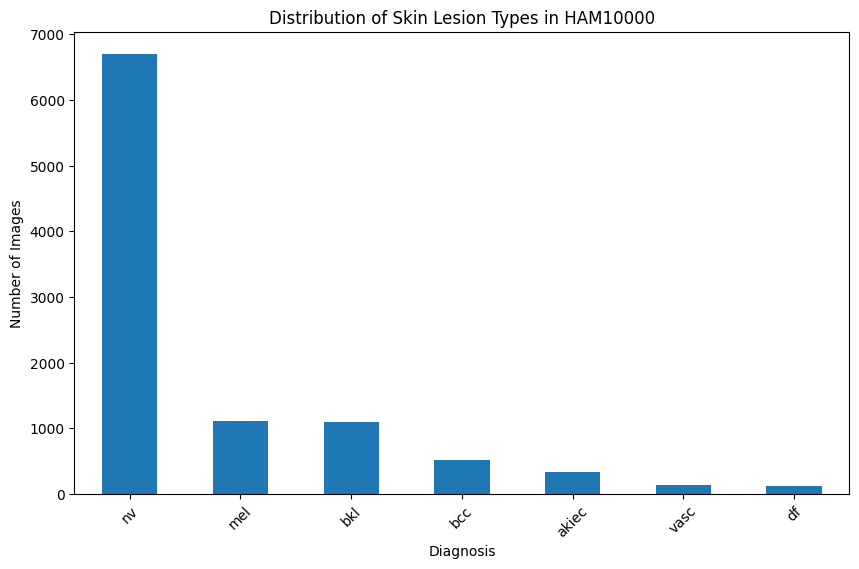

In [6]:
# Visualize the distribution of lesion types

# Count images in each diagnosis category
diagnosis_counts = metadata["dx"].value_counts()

# Create a bar graph
plt.figure(figsize=(10,6))

diagnosis_counts.plot(kind="bar")

plt.title("Distribution of Skin Lesion Types in HAM10000")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

In [7]:
# Create the table using Pandas
# Count the number of images for each diagnosis
diagnosis_counts = metadata["dx"].value_counts()

# Create a table
diagnosis_table = pd.DataFrame({
    "Diagnosis": diagnosis_counts.index,
    "Number of Images": diagnosis_counts.values
})

# Calculate percentage of total images
diagnosis_table["Percentage (%)"] = (
    diagnosis_table["Number of Images"] / len(metadata) * 100
).round(2)

# Define the full diagnosis names
diagnosis_names = {
    "nv": "Melanocytic Nevi",
    "mel": "Melanoma",
    "bkl": "Benign Keratosis",
    "bcc": "Basal Cell Carcinoma",
    "akiec": "Actinic Keratoses / Intraepithelial Carcinoma",
    "vasc": "Vascular Lesions",
    "df": "Dermatofibroma"
}

# Replace abbreviations with full names
diagnosis_table["Diagnosis"] = (
    diagnosis_table["Diagnosis"].map(diagnosis_names)
)

# Display the table
diagnosis_table

,Diagnosis,Number of Images,Percentage (%)
0,Melanocytic Nevi,6705,66.95
1,Melanoma,1113,11.11
2,Benign Keratosis,1099,10.97
3,Basal Cell Carcinoma,514,5.13
4,Actinic Keratoses / Intraepithelial Carcinoma,327,3.27
5,Vascular Lesions,142,1.42
6,Dermatofibroma,115,1.15


In [8]:
# Checking for missing data and duplicates
# Check the size of the dataset
print("Dataset shape:", metadata.shape)
      # returns the number of rows and columns

# Check for missing values in each column
print("\nMissing values:")
print(metadata.isnull().sum())
      # counts missing valyes in each column

# Check for duplicate image IDs
print("\nDuplicate image IDs:")
print(metadata["image_id"].duplicated().sum())
      # checks whether an image ID appears more than once

# Check how many unique lesions exist
print("\nUnique lesions:")
print(metadata["lesion_id"].nunique())
      # counts the number of unique lesions
      # ** VERY IMPORTANT!!!

Dataset shape: (10015, 8)

Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dataset          0
dtype: int64

Duplicate image IDs:
0

Unique lesions:
7470


In [9]:
print("Duplicate image IDs:",
      metadata["image_id"].duplicated().sum())

print("Unique lesions:",
      metadata["lesion_id"].nunique())

Duplicate image IDs: 0
Unique lesions: 7470


In [10]:
# Create a summary table of missing values
missing_table = pd.DataFrame({
    "Variable": metadata.columns,
    "Missing Values": metadata.isnull().sum().values,
    "Percentage Missing (%)": (
        metadata.isnull().sum().values / len(metadata) * 100
    ).round(2)
})

# Display the formatted table
missing_table.style.format({
    "Percentage Missing (%)": "{:.2f}%"
}).set_caption(
    "Table 2. Missing Values in HAM10000 Metadata"
)

,Variable,Missing Values,Percentage Missing (%)
0,lesion_id,0,0.00%
1,image_id,0,0.00%
2,dx,0,0.00%
3,dx_type,0,0.00%
4,age,57,0.57%
5,sex,0,0.00%
6,localization,0,0.00%
7,dataset,0,0.00%


In [11]:
# Define benign and malignant categories

# Melanoma (mel) -> malignant
# Basal cell carcinoma (bcc) -> malignant
# Melanocytic nevi (nv) -> benign
# Benign keratosis (bkl) -> benign
# Dermatofibroma (df) -> benign
# Vascular lesions (vasc) -> benign
# Actinic keratoses / intraepithelial carcinoma (akiec) -> exclude, initially.
    # this contains both premalignant and in-situ lesions


# this would leave:
  # 8,061 Benign images (83.21%)
  # 1,627 Malignant images (16.79%)

In [12]:
# This code creates a separate DataFrame called metadata_binary, preserving the original metadata DataFrame
# Then, it assigns the classifications


# Create a dictionary for binary classification
classification_map = {
    "mel": "Malignant",
    "bcc": "Malignant",
    "nv": "Benign",
    "bkl": "Benign",
    "df": "Benign",
    "vasc": "Benign"
}
        # assigns each diagnosis to either benign or malignant

# Creates a copy of the original metadata
metadata_binary = metadata.copy()
        # preserves your original metadata

# Assign benign or malignant labels
metadata_binary["classification"] = (
    metadata_binary["dx"].map(classification_map)
)
        # creates a new classification column

# Exclude categories without a binary label
metadata_binary = metadata_binary.dropna(
    subset=["classification"]
).copy()
        # removes rows without an assigned classification, which should only be the akiec category

In [13]:
# Count images in each classification
print(metadata_binary["classification"].value_counts())

classification
Benign       8061
Malignant    1627
Name: count, dtype: int64


In [14]:
# Display the first five rows
metadata_binary.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,classification
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,Benign
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,Benign
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern,Benign
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern,Benign
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern,Benign


In [15]:
# Count images in each binary classification
binary_counts = metadata_binary["classification"].value_counts()

# Create a summary table
binary_table = pd.DataFrame({
    "Classification": binary_counts.index,
    "Number of Images": binary_counts.values
})

# Calculate percentages
binary_table["Percentage (%)"] = (
    binary_table["Number of Images"]
    / len(metadata_binary) * 100
).round(2)

# Display formatted table
binary_table.style.format({
    "Number of Images": "{:,}",
    "Percentage (%)": "{:.2f}%"
}).set_caption(
    "Table 3. Distribution of Benign and Malignant Skin Lesions"
)

,Classification,Number of Images,Percentage (%)
0,Benign,"8,061",83.21%
1,Malignant,"1,627",16.79%


# 2. Load and sort the JPEG Images

In [16]:
# Check the image ZIP files
# List the files stored in the ENGG680 folder
import os

folder_path = "/content/drive/MyDrive/ENGG680"

# Display the exact filenames
for file in os.listdir(folder_path):
  print(repr(file))

'HAM10000_metadata.csv'
'HAM10000_images_part_1'
'HAM10000_images_part_2'
'HAM10000_images'
'HAM10000_Splits'
'resnet18_best_initial.pt'
'resnet18_best_finetuned.pt'
'resnet18_finetune_recovery.pt'
'resnet18_calibration_settings.json'
'resnet18_best_augmented.pt'
'resnet18_augmented_recovery.pt'
'resnet18_augmented_calibration_settings.json'
'resnet18_augmented_referral_analysis.csv'
'Final_Test_Results'
'ENGG 680 Final Model.ipynb'
'Model_Optimization'
'Threshold_Optimization'
'Additional_Finetuning'
'Experiment3_Error_Analysis'
'Final_Report_Figures'
'Pythons'


In [17]:
# Check whether Part 1 and Part 2 are folders
for part in [1, 2]:

  path = os.path.join(
      folder_path,
      f"HAM10000_images_part_{part}"
  )

  print(f"Part {part}:")
  print("Is a folder:", os.path.isdir(path))
  print("Is a file:", os.path.isfile(path))
  print()

Part 1:
Is a folder: True
Is a file: False

Part 2:
Is a folder: True
Is a file: False



In [18]:
# Count the images in both folders

# Define the two image folders
image_folders = [
    os.path.join(folder_path, "HAM10000_images_part_1"),
    os.path.join(folder_path, "HAM10000_images_part_2")
]

# Create an empty list to store image paths
image_paths = []

# Search both folders for JPEG images
for folder in image_folders:
  for root, dirs, files in os.walk(folder):
    for file in files:
      if file.lower().endswith((".jpg", ".jpeg")):
        image_paths.append(os.path.join(root, file))

# Dislay the total number of images
print("Total images found:", len(image_paths))

Total images found: 10023


# There are 8 extra images than are listed in the metadata...
Need to investigate this

In [19]:
# Check for duplicate image filenames

# Extract image IDs from the filenames
image_ids = [
    os.path.splitext(os.path.basename(path))[0]
    for path in image_paths
]

# Count duplicate image IDs
image_counts = pd.Series(image_ids).value_counts()

# Display duplicate image IDs
duplicate_images = image_counts[image_counts > 1]

print("Duplicate image IDs:", len(duplicate_images))
print("Extra file copies:", (duplicate_images - 1).sum())

# Display duplicated images
print(duplicate_images)

Duplicate image IDs: 0
Extra file copies: 0
Series([], Name: count, dtype: int64)


In [20]:
# Identify the eight additional images

# Get image IDs from the original metadata
metadata_ids = set(metadata["image_id"])

# Get image IDs from the image folders
folder_ids = set(image_ids)

# Identify images not included in the metadata
extra_images = folder_ids - metadata_ids

# Identify metadata records without matching images
missing_images = metadata_ids - folder_ids

# Display the results
print("Unique image IDs found:", len(folder_ids))
print("Images not in metadata:", len(extra_images))
print("Metadata images not found:", len(missing_images))

print("\nExtra image IDs:")
print(sorted(extra_images))

print("\nMissing image IDs:")
print(sorted(missing_images))

Unique image IDs found: 10023
Images not in metadata: 8
Metadata images not found: 0

Extra image IDs:
['ISIC_0024583 (1)', 'ISIC_0024597 (1)', 'ISIC_0025689 (1)', 'ISIC_0025845 (1)', 'ISIC_0026394 (1)', 'ISIC_0027049 (1)', 'ISIC_0028385 (1)', 'ISIC_0029064 (1)']

Missing image IDs:
[]


What these results mean:
  the 8 extra images all have (1) at the end of their filenames this suggests they are duplicate downloads or copies created when files with the same name were saved

In [21]:
# Verify that the original image IDs exist in your metadata

# Remove the " (1)" suffix from extra image IDs
original_ids = [
    image_id.replace(" (1)", "")
    for image_id in extra_images
]

# Check whether the original IDs exist in the metadata
for image_id in original_ids:
    print(image_id, image_id in metadata_ids)

ISIC_0029064 True
ISIC_0024597 True
ISIC_0025845 True
ISIC_0028385 True
ISIC_0027049 True
ISIC_0024583 True
ISIC_0025689 True
ISIC_0026394 True


Since all 8 are True, that confirms their base image IDs are already represented in the dataset -> we can now move forward

# Matching the images to the benign and malignant classifications

In [22]:
# Back to matching the images to the benign and malignant classifications

# Create a dictionary matching image IDs to file paths
image_path_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
    if os.path.splitext(os.path.basename(path))[0] in metadata_ids
}

# Match image paths to the binary classification dataset
metadata_binary["image_path"] = (
    metadata_binary["image_id"].map(image_path_map)
)

# Check for missing image paths
print("Images without matching files:",
      metadata_binary["image_path"].isnull().sum())

# Display the first five rows
metadata_binary[
    ["image_id", "dx", "classification", "image_path"]
].head()

Images without matching files: 0


,image_id,dx,classification,image_path
0,ISIC_0027419,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,ISIC_0025030,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
2,ISIC_0026769,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
3,ISIC_0025661,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
4,ISIC_0031633,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


# What has been completed so far
1. Load HAM10000 metadata
2. Identify seven diagnostic categories
3. Check missing values
4. Check duplicate image IDs
5. Create benign/malignant labels
6. Locate and match JPEG images

# Next Steps -> we'll need to divide the images into categories
1. Training set (70%) - used to train the CNN
2. Validation set (15%) - used to tune the model and monitor its performance
3. Testing set (15%) - used to evaluate your final model on unseen data

In [23]:
# Spliting the images into training, validaiton, and testing sets

from sklearn.model_selection import train_test_split

# Check that all images have matching file paths
assert metadata_binary["image_path"].notna().all()

#Verify each lesion has only one classification
assert(
    metadata_binary.groupby("lesion_id")["classification"]
    .nunique().max() == 1
)

# Create a table containing each unique lesions and its classification
unique_lesions = metadata_binary[
    ["lesion_id", "classification"]
  ].drop_duplicates()

# Split lesions into 70% training and 30% remaining
train_lesions, remaining_lesions = train_test_split(
    unique_lesions,
    test_size=0.30,
    random_state=42,
    stratify=unique_lesions["classification"]
)

#Split remaining lesions into 15% validation and 15% testing
val_lesions, test_lesions = train_test_split(
    remaining_lesions,
    test_size=0.50,
    random_state=42,
    stratify=remaining_lesions["classification"]
)

# Match all images to their assigned lesion groups
train_df = metadata_binary[
    metadata_binary["lesion_id"].isin(train_lesions["lesion_id"])
].copy()

val_df = metadata_binary[
    metadata_binary["lesion_id"].isin(val_lesions["lesion_id"])
].copy()

test_df = metadata_binary[
    metadata_binary["lesion_id"].isin(test_lesions["lesion_id"])
].copy()

# Display the number of images in each dataset
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("Total images:",
      len(train_df) + len(val_df) + len(test_df))

Training images: 6813
Validation images: 1460
Testing images: 1415
Total images: 9688


In [24]:
# Count benign and malignant distribution

# Count the number of benign and malignant images in each dataset
distribution = pd.DataFrame({
    "Training": train_df["classification"].value_counts(),
    "Validation": val_df["classification"].value_counts(),
    "Testing": test_df["classification"].value_counts()
}).fillna(0).astype(int)

# Display the results
print("Number of images in each classification:")
display(distribution)

Number of images in each classification:


,Training,Validation,Testing
classification,,,
Benign,5673,1209,1179
Malignant,1140,251,236


In [25]:
# Calculate the percentage of benign and malignant image in each dataset
distribution_percent = distribution.div(
    distribution.sum(axis=0), axis=1
) * 100

# Display percentages rounded to two decimal places
print("Percentage distribution of each classification:")
display(distribution_percent.round(2))

Percentage distribution of each classification:


,Training,Validation,Testing
classification,,,
Benign,83.27,82.81,83.32
Malignant,16.73,17.19,16.68


In [26]:
# Check for data leakage
# Verify no lesion overlap between datasets
# Identify unique lesion IDs in each dataset
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

# Check for overlapping lesion IDs
train_val_overlap = train_ids.intersection(val_ids)
train_test_overlap = train_ids.intersection(test_ids)
val_test_overlap = val_ids.intersection(test_ids)

# Display results
print("Training and Validation overlap:", len(train_val_overlap))
print("Training and Testing overlap:", len(train_test_overlap))
print("Validation and Testing overlap:", len(val_test_overlap))

# Confirm that no lesion appears in more than one dataset
assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

# Confirm that all images were assigned exactly once
assert len(train_df) + len(val_df) + len(test_df) == len(metadata_binary)

print("All checks passed! No lesion-level data leakage detected.")


Training and Validation overlap: 0
Training and Testing overlap: 0
Validation and Testing overlap: 0
All checks passed! No lesion-level data leakage detected.


This means there is a data-leakage...

# Fixing data-leakage

In [27]:
# Step 9: Correct the dataset assignments

# Recreate the training dataset
train_df = metadata_binary[
    metadata_binary["lesion_id"].isin(train_lesions["lesion_id"])
].copy()

# Recreate the validation dataset
val_df = metadata_binary[
    metadata_binary["lesion_id"].isin(val_lesions["lesion_id"])
].copy()

# Recreate the testing dataset
test_df = metadata_binary[
    metadata_binary["lesion_id"].isin(test_lesions["lesion_id"])
].copy()

# Check the number of images
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 6813
Validation images: 1460
Testing images: 1415


In [28]:
# Identify unique lesion IDs
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

# Check for overlapping lesions
print("Training and Validation overlap:",
      len(train_ids & val_ids))

print("Training and Testing overlap:",
      len(train_ids & test_ids))

print("Validation and Testing overlap:",
      len(val_ids & test_ids))

# Confirm no overlap
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Confirm all images are accounted for
assert len(train_df) + len(val_df) + len(test_df) == len(metadata_binary)

print("All checks passed! No lesion-level data leakage detected.")

Training and Validation overlap: 0
Training and Testing overlap: 0
Validation and Testing overlap: 0
All checks passed! No lesion-level data leakage detected.


# Save the training, validation, and testing datasets to Google Drive

In [29]:
# Create a folder for your datasets
# Save the training, validation, and testing datasets
import os

# Define the folder where the datasets will be saved
output_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"

# Create the folder where the datasets will be saved
os.makedirs(output_folder, exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


In [30]:
# Save the three datasets
# Save the training dataset
train_df.to_csv(
    os.path.join(output_folder, "train.csv"),
    index=False
)

# Save the validation dataset
val_df.to_csv(
    os.path.join(output_folder, "validation.csv"),
    index=False
)

# Save testing dataset
test_df.to_csv(
    os.path.join(output_folder, "test.csv"),
    index=False
)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [31]:
# Verifying the files were saved
# Check that all three CSV files exist
print(os.listdir(output_folder))

# Reload the training dataset to verify
train_check = pd.read_csv(
    os.path.join(output_folder, "train.csv")
)

print("Training images saved:", len(train_check))
display(train_check.head())

['validation.csv', 'train.csv', 'test.csv']
Training images saved: 6813


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,classification,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
2,HAM_0004234,ISIC_0029396,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
3,HAM_0004234,ISIC_0025984,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
4,HAM_0001949,ISIC_0025767,bkl,histo,70.0,male,trunk,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


## Image preprocessing and data loaders


# Image Preprocessing
Preparing the JPEG images for CNN using PyTorch and Torchvision

In [32]:
# Import the required libraries for preprocessing
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

In [33]:
# Define image preprocessing transformations

# Define preprocessing for all images
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing transformations created successfully!")

Image preprocessing transformations created successfully!


In [34]:
# Test preprocessing on one image

# Select the first image from the training dataset
image_path = train_df.iloc[0]["image_path"]

# Open the original JPEG image
original_image = Image.open(image_path).convert("RGB")

# Apply preprocessing transformations
processed_image = image_transform(original_image)

# Check the image dimensions
print("Original image dimensions:", original_image.size)
print("Processed image tensor shape:", processed_image.shape)


Original image dimensions: (600, 450)
Processed image tensor shape: torch.Size([3, 224, 224])


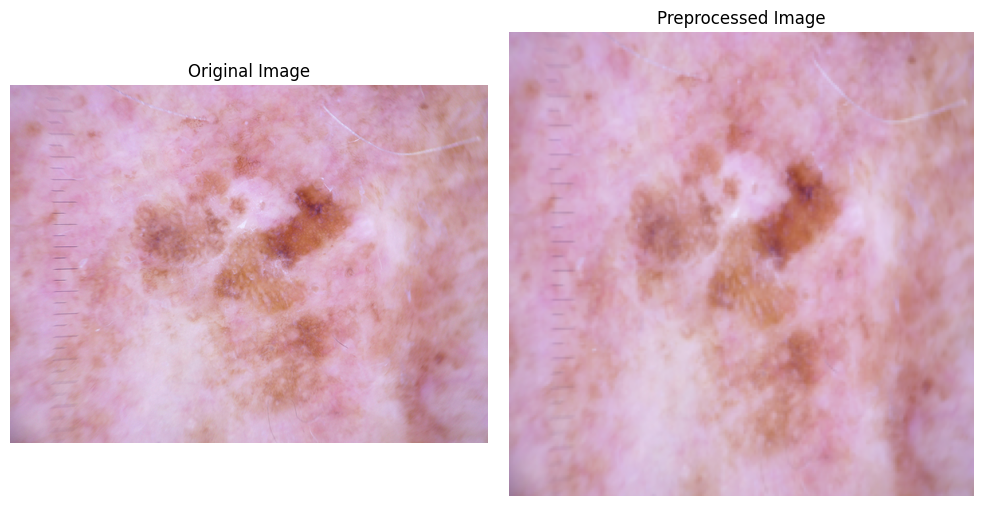

In [35]:
# Compare the original and preprocessed images

# Reverse normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = processed_image * std + mean

# Convert tensor to image format for Matplotlib
display_image = display_image.permute(1, 2, 0).numpy()

# Display images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_image.clip(0, 1))
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [36]:
# Verify the preprocessing was successful

# Check tensor dimensions
assert processed_image.shape == (3, 224, 224)

# Check that all pixel values are finite
assert torch.isfinite(processed_image).all()

# Display tensor information
print("Tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)
print("Minimum normalized value:", processed_image.min().item())
print("Maximum normalized value:", processed_image.max().item())

print("Image preprocessing verified successfully!")

Tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Minimum normalized value: -1.160364031791687
Maximum normalized value: 2.5877127647399902
Image preprocessing verified successfully!


In [37]:
# Create a PyTorch Dataset

from torch.utils.data import Dataset, DataLoader
from PIL import Image

In [38]:
# Create custom HAM10000 Dataset

class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get image file path
        image_path = self.dataframe.iloc[idx]["image_path"]

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        # Convert classification into numerical label
        classification = self.dataframe.iloc[idx]["classification"]

        label = 0 if classification == "Benign" else 1

        return image, label

In [39]:
# Define preprocessing with augmentation for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Each flip has a 50% chance of happening
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    transforms.ToTensor(),

    # Use the same normalization as before
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [40]:
# Create training, validation and testing datasets

# Training images: include random flips
train_dataset = HAM10000Dataset(
    train_df, transform=train_transform
)

# Validation images: use the original preprocessing without random flips
val_dataset = HAM10000Dataset(
    val_df, transform=image_transform
)

# Testing images: use the original preprocessing without random flips
test_dataset = HAM10000Dataset(
    test_df, transform=image_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 6813
Validation dataset: 1460
Testing dataset: 1415


In [41]:
# Test one image and its label

image_tensor, label = train_dataset[0]

print("Image tensor shape:", image_tensor.shape)
print("Classification label:", label)
print("Classification:", "Malignant" if label == 1 else "Benign")

Image tensor shape: torch.Size([3, 224, 224])
Classification label: 0
Classification: Benign


# Create PyTorch DataLoaders
organize the images into smaller batches and feed them to our CNN during training, validation, and testing.

In [42]:
# Create Dataloaders

from torch.utils.data import DataLoader

# Define batch size
batch_size = 32

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [43]:
# Verify the DataLoaders

# Retrieve one batch
images, labels = next(iter(train_loader))

# Display batch information
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Number of images in batch:", len(images))
print("Labels:", labels)

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Number of images in batch: 32
Labels: tensor([0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 1, 0])


In [44]:
# Check the number of batches

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 213
Validation batches: 46
Testing batches: 45


## ResNet-18 baseline


# Setting up ResNet-18


Next we will load ResNet-18 and adapt its final layer for our two categories (benign and malignant)

In [45]:
# Load pretrained ResNet-18
import torch
import torch.nn as nn
from torchvision import models

# Set a seed to make the new layer's initialization reproducible
torch.manual_seed(42)

# Load weights learned from ImageNet
model = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze all existing weights
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the original classification layer
# The new layer is trainable by default
model.fc = nn.Linear(model.fc.in_features, 2)

# Use a GPU if available; otherwise use the CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)

# Check which paramters can learn
print("Device:", device)
print("Trainable parameters:")

for name, parameter in model.named_parameters():
  if parameter.requires_grad:
    print(name)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s]


Device: cuda
Trainable parameters:
fc.weight
fc.bias


The below cell prepares training but does not start it yet

In [46]:
# Account for class imbalance using TRAINING data only

# Count images in label order: benign = 0, malignant = 1
class_counts = train_df["classification"].value_counts()

counts = torch.tensor(
    [class_counts["Benign"], class_counts["Malignant"]],
    dtype=torch.float32
)

# Less common classes receive larger weights
class_weights = counts.sum() / (2 * counts)
class_weights = class_weights.to(device)

# Define how prediction errors will be measured
  # criterion measures prediction errors. For the same prediction error,
  # a malignant example recieves about five times the weight of a benign example
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Define how the new classification layer will learn
  # optimizer -> adjusts the new final layer's weights to reduce those errors
  # lr=0.001 -> learning rate, which controls the size of those adjustments
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Benign weight:", round(class_weights[0].item(), 3))
print("Malignant weight:", round(class_weights[1].item(), 3))
print("Loss function and optimizer are ready.")

Benign weight: 0.6
Malignant weight: 2.988
Loss function and optimizer are ready.


Training the new classification layer

In [47]:
# import copy
# import torch
# from sklearn.metrics import balanced_accuracy_score, recall_score
# from tqdm.auto import tqdm

# num_epochs = 3
# best_val_score = -1
# history = []

# # Save the best model to Google Drive
# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_initial.pt"
# )

# for epoch in range(num_epochs):

#     # Keep the frozen feature extractor fixed,
#     # including its batch-normalization statistics
#     model.eval()
#     model.fc.train()

#     training_loss_sum = 0.0
#     training_weight_sum = 0.0

#     # Train the new classification layer
#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer.zero_grad()

#         # Make predictions and calculate the error
#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         # Update only the new classification layer
#         loss.backward()
#         optimizer.step()

#         # Accumulate the weighted loss
#         batch_weight = class_weights[labels].sum().item()
#         training_loss_sum += loss.item() * batch_weight
#         training_weight_sum += batch_weight

#     # Evaluate without updating the model
#     model.eval()

#     validation_predictions = []
#     validation_labels = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#         ):
#             images = images.to(device)

#             outputs = model(images)
#             predictions = outputs.argmax(dim=1)

#             validation_predictions.extend(
#                 predictions.cpu().tolist()
#             )
#             validation_labels.extend(labels.tolist())

#     # Calculate validation metrics
#     balanced_accuracy = balanced_accuracy_score(
#         validation_labels,
#         validation_predictions
#     )

#     malignant_recall = recall_score(
#         validation_labels,
#         validation_predictions,
#         pos_label=1,
#         zero_division=0
#     )

#     training_loss = training_loss_sum / training_weight_sum

#     # Record results for this epoch
#     history.append({
#         "epoch": epoch + 1,
#         "training_loss": training_loss,
#         "validation_balanced_accuracy": balanced_accuracy,
#         "validation_malignant_recall": malignant_recall
#     })

#     print(
#         f"Epoch {epoch + 1}/{num_epochs} | "
#         f"Training loss: {training_loss:.4f} | "
#         f"Validation balanced accuracy: {balanced_accuracy:.3f} | "
#         f"Malignant recall: {malignant_recall:.3f}",
#         flush=True
#     )

#     # Save the model with the best validation balanced accuracy
#     if balanced_accuracy > best_val_score:
#         best_val_score = balanced_accuracy
#         best_model_weights = copy.deepcopy(model.state_dict())
#         torch.save(best_model_weights, checkpoint_path)

# # Restore the best model from these three epochs
# model.load_state_dict(best_model_weights)

# print("Training complete. Best model restored and saved.")

# What is an epoch
An epoch is one complete pass through all the training images.

There is 6,813 training images, which the model processes in batched of up to 32 images.
  - Epoch 1: The model sees all 6,813 images and adjusts its classification layer as it goes
  - Epoch 2: The model sees all the images again and continues to learn
  - Epoch 3: The model makes another complete pass

After each epoch, your code checks the model on the validation images, without learning from them

# What are the layers?
Layers are the processing stages inside the neural network. Each stage receives numbers from the previous stage, processes them, and passes the result onward.

The image starts as numbers representing its pixels. As it passes through ResNet-18, those numbers become descriptions of visual patterns.




Part of the model   ->    What it does

Early layers -> Detect simple patterns, such as edges and colour changes

Middle layers -> Combine simple patterns into textures and shapes

Latter layers -> Combine those patterns into more complex image features

Final classification layer -> Uses those features to produce benign and malignant scores





These patterns are learned from examples - you don't manually program each layer to recognize a particular feature

In the current training, only the final classification layer is learning. All pretrained layers still process the images, but their weights stay frozen

Think of this as keeping an existing image-analysis system and teaching it a new final decision: "Based on these image features, should this be classified as benign or malignant?"

Later, during the fine-tuning stage, we will allow the last group of pretrained layers to learn too, so their feature detection can adapt more closely to the skin lesion images

## Fine-tuning and calibration


# Next step is fine-tuning: allowing ResNet-18's last feature-extraction block to learn, then checking whether that improves validation performance

In [48]:
# Load the best initial model

# Step 15.1: Inspect the initial ResNet18 checkpoint

import os
import torch

checkpoint_path = "/content/drive/MyDrive/ENGG680/resnet18_best_initial.pt"

assert os.path.isfile(checkpoint_path), "Checkpoint file not found."

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("First checkpoint keys:", list(checkpoint.keys())[:10])

Device: cuda
Checkpoint type: <class 'collections.OrderedDict'>
First checkpoint keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean']


In [49]:
# First: Enable my GPU in Google Colab (this will be much faster for fine-tuning)
# than using my CPU
  # 1. Click Runtime in the top menu
  # 2. Selet Change runtime type
  # 3. Under Hardware accelerator, select T4 GPU (if available)
  # 4. Click save
  # 5. Reconnect to your notebook

In [50]:
# Check whether GPU is available
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [51]:
# Step 15.2: Load the saved initial ResNet18 model

import torch
import torch.nn as nn
from torchvision import models

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Define the saved model location
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_initial.pt"
)

# Load the saved model weights
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Recreate the ResNet18 architecture
model = models.resnet18(weights=None)

# Replace the final classification layer
model.fc = nn.Linear(
    model.fc.in_features,
    2
)

# Load the previously trained weights
model.load_state_dict(checkpoint)

# Move the model to GPU if available
model = model.to(device)

print("Device:", device)
print("Initial ResNet18 weights loaded successfully!")

Device: cuda
Initial ResNet18 weights loaded successfully!


In [52]:
# Step 15.3 - Unfreeze the final feature-extraction block
# Unfreeze layer4 and the classification layer

# Freeze all model paramters
for param in model.parameters():
  param.requires_grad = False

# Unfreeze the final feature-extraction block
for param in model.layer4.parameters():
  param.requires_grad = True

# Unfreeze the final classification layer
for param in model.fc.parameters():
  param.requires_grad = True

# Verify which parameters are trainable
trainable = [
    name for name, param in model.named_parameters()
    if param.requires_grad
]

print("Number of ttrainable parameter tensors:", len(trainable))
print("Trainable layers:")
for name in trainable:
  print(name)

Number of ttrainable parameter tensors: 17
Trainable layers:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [53]:
# conv1, layer1, layer2, layer3 -> frozen -> preserve previously learned image features

# layer4.0 -> trainable -> adapt higher-level image features

# layer4.1 -> trainable -> further refine features for skin lesion classification

# fc.weight -> trainable -> learn how to classify benign vs malignant lesions

# fc.bias -> trainable -> adjust classification outputs

In [54]:
# Step 15.4 - Configure the optimizer
import torch.optim as optim

optimizer = optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

print("Fine-tuning optimizer created succesfully!")
print("Layer4 learning rate:", optimizer.param_groups[0]["lr"])
print("FC learning rate:", optimizer.param_groups[1]["lr"])

Fine-tuning optimizer created succesfully!
Layer4 learning rate: 1e-05
FC learning rate: 0.0001


In [55]:
# Why are we using two different learning rates?
  # layer4: 0.00001 -> smaller learning rate allows the pretrained features to adapt gradually
  # fc: 0.0001 -> slightly larger learning rate allows the classification layer to adjust more quickly

  # Both are starting hyperparameters that we can adjust based on validation performance

In [56]:
# Step 15.5 - Configure the loss function
# Because our dataset contains more benign than malignant images, we need
# the model to account for this class imbalance

# We will be using weighted cross-entropy loss which will assign more
# importance to mistakes involving the less represented class to account for the imbalance


# Step 15.5: Check datasets and class distributions

import pandas as pd

# Check which variables are available
for name in ["train_df", "val_df", "train_loader", "val_loader"]:
    print(f"{name} available:", name in globals())

# Display training class distribution if available
if "train_df" in globals():
    print("\nTraining class distribution:")
    print(train_df["classification"].value_counts())

# Display validation class distribution if available
if "val_df" in globals():
    print("\nValidation class distribution:")
    print(val_df["classification"].value_counts())

train_df available: True
val_df available: True
train_loader available: True
val_loader available: True

Training class distribution:
classification
Benign       5673
Malignant    1140
Name: count, dtype: int64

Validation class distribution:
classification
Benign       1209
Malignant     251
Name: count, dtype: int64


In [57]:
# Step 15.6 - Configure weighted cross-entropy loss
import torch
import torch.nn as nn

# Count training images in each class
class_counts = train_df["classification"].value_counts()

n_benign = class_counts["Benign"]
n_malignant = class_counts["Malignant"]
n_total = n_benign + n_malignant

# Calculate balanced class weights
weight_benign = n_total / (2 * n_benign)
weight_malignant = n_total / (2 * n_malignant)

# Create weight tensor in correct class order
class_weights = torch.tensor(
    [weight_benign, weight_malignant],
    dtype=torch.float32
).to(device)

# Define weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Benign weight:", round(weight_benign, 4))
print("Malignant weight:", round(weight_malignant, 4))
print("Weighted corss-entropy loss configured!")

Benign weight: 0.6005
Malignant weight: 2.9882
Weighted corss-entropy loss configured!


In [58]:
# These class weights are only calculated from the training dataset
# This is important b/c we dont want validation or test information influencing the training

In [59]:
# Checking whether the GPU is actually being used
# Step 1 - Check GPU availability and model device

import torch

print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)
print("Model device:", next(model.parameters()).device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print(
        "GPU memory allocated (GB):",
        round(torch.cuda.memory_allocated(0) / 1e9, 2)
    )

CUDA available: True
Selected device: cuda
Model device: cuda:0
GPU name: Tesla T4
GPU memory allocated (GB): 0.04


In [60]:
# Check image-loading speed
# Step 2: Measure image loading speed

import time

start_time = time.time()

images, labels = next(iter(train_loader))

elapsed_time = time.time() - start_time

print(f"Time to load one batch: {elapsed_time:.2f} seconds")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Time to load one batch: 12.05 seconds
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


So this means it is taking an incredible long time to load the images so we're going to move the images to Colab's local storgae to hopefully speed up the process

In [61]:
# Check image paths and dataset sizes

import os

print("First training image path:")
print(train_df["image_path"].iloc[0])

print("\nFirst validation image path:")
print(val_df["image_path"].iloc[0])

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))

print("\nFirst image exists:",
      os.path.isfile(train_df["image_path"].iloc[0]))

First training image path:
/content/drive/MyDrive/ENGG680/HAM10000_images_part_1/ISIC_0027419.jpg

First validation image path:
/content/drive/MyDrive/ENGG680/HAM10000_images_part_2/ISIC_0031633.jpg

Training images: 6813
Validation images: 1460

First image exists: True


# Moving images to local storage

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 1 - Copy the HAM10000 image folders to local storage

import os
import shutil
import time

# Original Google Drive folder
drive_folder = "/content/drive/MyDrive/ENGG680"

# Temporary local storage folder
local_folder = "/content/HAM10000"

os.makedirs(local_folder, exist_ok=True)

# Image folders
image_folders = [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]

start_time = time.time()

for folder in image_folders:

    source = os.path.join(drive_folder, folder)
    destination = os.path.join(local_folder, folder)

    if not os.path.isdir(source):
        raise FileNotFoundError(
            f"Source folder not found: {source}"
        )

    print(f"Copying {folder}...", flush=True)

    # Copy images to local storage
    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    print(f"Finished copying {folder}!")

elapsed_time = time.time() - start_time

print("\nBoth image folders copied!")
print(f"Total copying time: {elapsed_time / 60:.2f} minutes")

# Verify local image counts
for folder in image_folders:

    folder_path = os.path.join(local_folder, folder)

    image_count = sum(
        filename.lower().endswith((".jpg", ".jpeg", ".png"))
        for filename in os.listdir(folder_path)
    )

    print(f"{folder}: {image_count} images")

Copying HAM10000_images_part_1...
Finished copying HAM10000_images_part_1!
Copying HAM10000_images_part_2...
Finished copying HAM10000_images_part_2!

Both image folders copied!
Total copying time: 4.98 minutes
HAM10000_images_part_1: 5008 images
HAM10000_images_part_2: 5015 images


In [ ]:
# Step 2 - Updating image paths to local storage
import os

# Original and new image locations
old_path = "/content/drive/MyDrive/ENGG680/"
new_path = "/content/HAM10000/"

# Update paths while preserving dataset assignments
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_path"].str.replace(
        old_path,
        new_path,
        regex=False
    )

# Verify every image exists locally
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = sum(
        not os.path.isfile(path)
        for path in df["image_path"]
    )

    print(f"{name}: {len(df)} images")
    print(f"Missing local images: {missing}")
    print()

print("Example updated training path:")
print(train_df["image_path"].iloc[0])

Training: 6813 images
Missing local images: 0

Validation: 1460 images
Missing local images: 0

Testing: 1415 images
Missing local images: 0

Example updated training path:
/content/HAM10000/HAM10000_images_part_1/ISIC_0027419.jpg


In [ ]:
# Step 3 - Recreate the datasets and DataLoaders
# using images stored locally in Colab

from torch.utils.data import DataLoader

# Recreate datasets using updated local paths
train_dataset = HAM10000Dataset(
    train_df,
    transform=image_transform
)

val_dataset = HAM10000Dataset(
    val_df,
    transform=image_transform
)

test_dataset = HAM10000Dataset(
    test_df,
    transform=image_transform
)

# Recreate DataLoaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Local DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Local DataLoaders created successfully!
Training batches: 213
Validation batches: 46
Testing batches: 45


> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 4: Measure local image-loading speed

import time

# Measure two batches to account for initial worker startup
loader_iterator = iter(train_loader)

start_time = time.time()
images, labels = next(loader_iterator)
first_batch_time = time.time() - start_time

start_time = time.time()
images, labels = next(loader_iterator)
second_batch_time = time.time() - start_time

print(f"First batch: {first_batch_time:.2f} seconds")
print(f"Second batch: {second_batch_time:.2f} seconds")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

First batch: 0.66 seconds
Second batch: 0.00 seconds
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


# Restarting the fine-tuning

In [ ]:
# Step 15.7A - Verify fine-tuning setup

import torch
import os

print("Device:", device)
print("Model device:", next(model.parameters()).device)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("Optimizer available:", "optimizer" in globals())
print("Loss function available:", "criterion" in globals())

print(
    "Trainable parameter tensors:",
    sum(p.requires_grad for p in model.parameters())
)

print(
    "Original checkpoint exists:",
    os.path.isfile(
        "/content/drive/MyDrive/ENGG680/resnet18_best_initial.pt"
    )
)

Device: cuda
Model device: cuda:0
Training batches: 213
Validation batches: 46
Optimizer available: True
Loss function available: True
Trainable parameter tensors: 17
Original checkpoint exists: True


In [ ]:
# # Step 15.7B - Fine-tune ResNet18 with checkpoint recovery

# import os
# import torch
# import pandas as pd
# from sklearn.metrics import balanced_accuracy_score, recall_score
# from tqdm.auto import tqdm

# num_epochs = 3

# # Paths for saved models
# save_folder = "/content/drive/MyDrive/ENGG680"

# best_model_path = os.path.join(
#     save_folder, "resnet18_best_finetuned.pt"
# )

# recovery_path = os.path.join(
#     save_folder, "resnet18_finetune_recovery.pt"
# )

# best_val_score = -1.0
# start_epoch = 0
# finetune_history = []

# # Resume if a recovery checkpoint exists
# if os.path.isfile(recovery_path):

#     recovery = torch.load(
#         recovery_path,
#         map_location=device,
#         weights_only=True
#     )

#     model.load_state_dict(recovery["model_state_dict"])
#     optimizer.load_state_dict(recovery["optimizer_state_dict"])

#     start_epoch = recovery["epoch"]
#     best_val_score = recovery["best_val_score"]
#     finetune_history = recovery["history"]

#     print(f"Resuming from epoch {start_epoch + 1}")

# else:
#     print("Starting fine-tuning from initial model.")

# # Fine-tuning loop
# for epoch in range(start_epoch, num_epochs):

#     # Keep frozen layers in evaluation mode
#     model.eval()

#     # Train only layer4 and fc
#     model.layer4.train()
#     model.fc.train()

#     train_loss_sum = 0.0
#     train_weight_sum = 0

#     # Training phase
#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#     ):

#         images = images.to(device, non_blocking=True)
#         labels = labels.to(device, non_blocking=True)

#         optimizer.zero_grad()

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         train_loss_sum += loss.item() * labels.size(0)
#         train_weight_sum += labels.size(0)

#     train_loss = train_loss_sum / train_weight_sum

#     # Validation phase
#     model.eval()

#     val_loss_sum = 0.0
#     val_weight_sum = 0

#     all_labels = []
#     all_predictions = []

#     with torch.no_grad():

#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#         ):

#             images = images.to(device, non_blocking=True)
#             labels = labels.to(device, non_blocking=True)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             predictions = torch.argmax(outputs, dim=1)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_weight_sum += labels.size(0)

#             all_labels.extend(labels.cpu().tolist())
#             all_predictions.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_weight_sum

#     val_balanced_accuracy = balanced_accuracy_score(
#         all_labels,
#         all_predictions
#     )

#     val_malignant_recall = recall_score(
#         all_labels,
#         all_predictions,
#         pos_label=1
#     )

#     # Store results
#     finetune_history.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_balanced_accuracy": val_balanced_accuracy,
#         "val_malignant_recall": val_malignant_recall
#     })

#     print(f"\nEpoch {epoch + 1}/{num_epochs}")
#     print(f"Training Loss: {train_loss:.4f}")
#     print(f"Validation Loss: {val_loss:.4f}")
#     print(f"Validation Balanced Accuracy: {val_balanced_accuracy:.4f}")
#     print(f"Validation Malignant Recall: {val_malignant_recall:.4f}")

#     # Save best-performing model
#     if val_balanced_accuracy > best_val_score:

#         best_val_score = val_balanced_accuracy

#         torch.save(
#             model.state_dict(),
#             best_model_path
#         )

#         print("Best fine-tuned model saved!")

#     # Save recovery checkpoint after every epoch
#     torch.save({
#         "epoch": epoch + 1,
#         "model_state_dict": model.state_dict(),
#         "optimizer_state_dict": optimizer.state_dict(),
#         "best_val_score": best_val_score,
#         "history": finetune_history
#     }, recovery_path)

#     print("Recovery checkpoint saved!")

# print("\nFine-tuning complete!")
# print(f"Best validation balanced accuracy: {best_val_score:.4f}")

# # Display results table
# results_df = pd.DataFrame(finetune_history)
# display(results_df)

In [ ]:
# 0 = benign
# 1 = malignant

# Note: batch normalization
  # model.layer4.train() also enables updates to the batch-normalization running statistics within layer4
  # This is acceptable for the unfrozen block but with a relatively small dataset it may introduce additional variability
  # I will compare this approach with keeping all batch-normalization layers in evaluation mode

In [ ]:
# Step 15.8 - Verify both trained models are saved

import os

initial_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_initial.pt"
)

finetuned_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

print("Initial model exists:", os.path.isfile(initial_path))
print("Fine-tuned model exists:", os.path.isfile(finetuned_path))

if os.path.isfile(initial_path):
    print(
        "Initial model size (MB):",
        round(os.path.getsize(initial_path) / 1e6, 2)
    )

if os.path.isfile(finetuned_path):
    print(
        "Fine-tuned model size (MB):",
        round(os.path.getsize(finetuned_path) / 1e6, 2)
    )

Initial model exists: True
Fine-tuned model exists: True
Initial model size (MB): 44.79
Fine-tuned model size (MB): 44.79


In [ ]:
# Step 15.9 - Load initial and fine-tuned ResNet18 models

import torch
import torch.nn as nn
from torchvision import models

# Function to load a saved ResNet18 model
def load_resnet18(checkpoint_path):

    # Recreate ResNet18 architecture
    loaded_model = models.resnet18(weights=None)

    # Configure binary classification output
    loaded_model.fc = nn.Linear(
        loaded_model.fc.in_features,
        2
    )

    # Load trained weights
    state_dict = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    loaded_model.load_state_dict(state_dict)

    # Move model to GPU
    loaded_model = loaded_model.to(device)

    # Set evaluation mode
    loaded_model.eval()

    return loaded_model


# Load initial model
initial_model = load_resnet18(initial_path)

# Load best fine-tuned model
finetuned_model = load_resnet18(finetuned_path)

print("Initial ResNet18 loaded successfully!")
print("Fine-tuned ResNet18 loaded successfully!")

print("\nInitial model device:",
      next(initial_model.parameters()).device)

print("Fine-tuned model device:",
      next(finetuned_model.parameters()).device)

Initial ResNet18 loaded successfully!
Fine-tuned ResNet18 loaded successfully!

Initial model device: cuda:0
Fine-tuned model device: cuda:0


In [ ]:
# # Step 15.10 - Compare both models on validation data

# import numpy as np
# import pandas as pd
# import torch

# from sklearn.metrics import (
#     accuracy_score,
#     balanced_accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score
# )

# from tqdm.auto import tqdm


# def evaluate_model(model, data_loader, model_name):

#     model.eval()

#     all_labels = []
#     all_predictions = []
#     all_probabilities = []

#     total_loss = 0.0
#     total_samples = 0

#     with torch.no_grad():

#         for images, labels in tqdm(
#             data_loader,
#             desc=f"Evaluating {model_name}"
#         ):

#             images = images.to(
#                 device, non_blocking=True
#             )

#             labels = labels.to(
#                 device, non_blocking=True
#             )

#             # Get model outputs
#             outputs = model(images)

#             # Calculate weighted cross-entropy loss
#             loss = criterion(outputs, labels)

#             # Convert outputs to probabilities
#             probabilities = torch.softmax(
#                 outputs, dim=1
#             )[:, 1]

#             # Classify using the default 0.50 threshold
#             predictions = (
#                 probabilities >= 0.50
#             ).long()

#             total_loss += (
#                 loss.item() * labels.size(0)
#             )

#             total_samples += labels.size(0)

#             all_labels.extend(
#                 labels.cpu().numpy()
#             )

#             all_predictions.extend(
#                 predictions.cpu().numpy()
#             )

#             all_probabilities.extend(
#                 probabilities.cpu().numpy()
#             )

#     # Convert results to NumPy arrays
#     all_labels = np.array(all_labels)
#     all_predictions = np.array(all_predictions)
#     all_probabilities = np.array(all_probabilities)

#     # Calculate performance metrics
#     results = {
#         "Model": model_name,

#         "Accuracy": accuracy_score(
#             all_labels, all_predictions
#         ),

#         "Balanced Accuracy": balanced_accuracy_score(
#             all_labels, all_predictions
#         ),

#         "Malignant Recall": recall_score(
#             all_labels,
#             all_predictions,
#             pos_label=1
#         ),

#         "Precision": precision_score(
#             all_labels,
#             all_predictions,
#             pos_label=1,
#             zero_division=0
#         ),

#         "F1 Score": f1_score(
#             all_labels,
#             all_predictions,
#             pos_label=1,
#             zero_division=0
#         ),

#         "ROC-AUC": roc_auc_score(
#             all_labels,
#             all_probabilities
#         ),

#         "Validation Loss": (
#             total_loss / total_samples
#         )
#     }

#     return results, all_labels, all_probabilities


# # Evaluate original ResNet18
# initial_results, initial_labels, initial_probs = (
#     evaluate_model(
#         initial_model,
#         val_loader,
#         "Initial ResNet18"
#     )
# )

# # Evaluate fine-tuned ResNet18
# finetuned_results, finetuned_labels, finetuned_probs = (
#     evaluate_model(
#         finetuned_model,
#         val_loader,
#         "Fine-tuned ResNet18"
#     )
# )

# # Confirm both models evaluated the same labels
# assert np.array_equal(
#     initial_labels,
#     finetuned_labels
# ), "Validation labels do not match!"

# # Create comparison table
# comparison_df = pd.DataFrame([
#     initial_results,
#     finetuned_results
# ])

# display(comparison_df.round(4))

# print("\nBoth models evaluated successfully!")

This above step will help us learn and figure out:

- Balanced accuracy
- Malignant recall
- Precision
- F1 score
- ROC-AUC
- Validation loss

Most encouraging results is malignant recall it increased from 80.48% to 83.67%.
This means the fine-tuned model correctly identifies a greater proportion of malignant lesions.

ROC-AUC also imporved 0.8329 -> 0.8580, indicates better discrimination between benign and malignant lesions across classification thresholds.

Precision is still too low at 36.65% this means that many images classified as malignant are actually benign. We will need to examine this more.

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.11 - Evaluate the 95% prediction-confidence threshold

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# True validation labels
y_true = np.asarray(finetuned_labels)

# Predicted probability of malignancy
p_malignant = np.asarray(finetuned_probs)

# Predicted probability of benign
p_benign = 1 - p_malignant

# Default binary predictions
predictions = (p_malignant >= 0.50).astype(int)

# Highest predicted probability for each image
confidence = np.maximum(p_benign, p_malignant)

# Require at least 95% confidence
confidence_threshold = 0.95

accepted = confidence >= confidence_threshold
referred = ~accepted

# Overall counts
total_images = len(y_true)
accepted_count = accepted.sum()
referred_count = referred.sum()

# Accuracy on accepted predictions
accepted_accuracy = (
    accuracy_score(
        y_true[accepted],
        predictions[accepted]
    )
    if accepted_count > 0
    else np.nan
)

# Malignant lesion counts
malignant = y_true == 1

malignant_accepted = (malignant & accepted).sum()
malignant_referred = (malignant & referred).sum()

# Malignant lesions incorrectly classified as benign
malignant_missed = (
    malignant & accepted & (predictions == 0)
).sum()

results_95 = pd.DataFrame({
    "Metric": [
        "Total validation images",
        "Images classified (>=95% confidence)",
        "Images referred (<95% confidence)",
        "Classification coverage (%)",
        "Accuracy on classified images (%)",
        "Malignant images classified",
        "Malignant images referred",
        "Malignant images incorrectly classified as benign"
    ],
    "Value": [
        total_images,
        accepted_count,
        referred_count,
        round(100 * accepted_count / total_images, 2),
        round(100 * accepted_accuracy, 2),
        malignant_accepted,
        malignant_referred,
        malignant_missed
    ]
})

display(results_95)

NameError: name 'finetuned_labels' is not defined

# Important findings:
- Of the 251 malignant lesions:
  - 45 met the 95% confidence threshold and recieved a classification
  - 206 did not meet the threshold and were flagged for expert review
  - 0 malignant images were confidently misclassified as benign

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.12 - Calculate calibration metrics
# We wil use:
  # Brier score:
    # measures how closely predicted malignant probabilities match actual outcomes. Lower is better.
  # Expected Calibration Error (ECE):
    # Measures the difference between predicted confidence and observed accuracy across probability groups. Lower is better.

# Step 15.12 - Evaluate probability calibration

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

# Use predictions from our fine-tuned ResNet18
y_true = np.asarray(finetuned_labels)
p_malignant = np.asarray(finetuned_probs)

# Calculate Brier score
brier = brier_score_loss(y_true, p_malignant)

# Calculate Expected Calibration Error (ECE)
def calculate_ece(y_true, probabilities, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)

    predicted_classes = (
        probabilities >= 0.5
    ).astype(int)

    confidence = np.maximum(
        probabilities, 1 - probabilities
    )

    correct = (predicted_classes == y_true)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = correct[mask].mean()
        bin_confidence = confidence[mask].mean()

        ece += (
            mask.mean() *
            abs(bin_accuracy - bin_confidence)
        )

    return ece


ece = calculate_ece(
    y_true,
    p_malignant,
    n_bins=10
)

print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error: {ece:.4f}")

# Generate reliability diagram
fraction_positive, mean_predicted = (
    calibration_curve(
        y_true,
        p_malignant,
        n_bins=10,
        strategy="uniform"
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Fine-tuned ResNet18"
)

plt.xlabel("Mean Predicted Probability of Malignancy")
plt.ylabel("Observed Fraction of Malignant Lesions")

plt.title(
    "ResNet18 Probability Calibration "
    "(Validation Set)"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This tells us that the model can distinguish malignant from benign lesions reasonably well, but its predicted probabilities are not yet well calibrated



For example, looking at your graph:
- When the model predicts approximately 65% malignancy probability, only around 25% of lesions in that probability bin are malignant.
- When it predicts approximately 85%, only around 34% are malignant.
- Even around 95% predicted malignancy, the observed malignant fraction is approximately 72%.


This pattern is consistent with the fact that we trained your model using weighted cross-entropy, which gives malignant lesions greater importance during training.

Weighted cross-entropy can improve malignant recall, but it can also distort the probabilities produced by softmax.


An ECE of 0.09 means that, across the confidence bins, the weighted average difference between predicted confidence and observed classification accuracy is approximately 9 percentage points.

That isn't necessarily terrible, but it does indicate room for improvement.

Importantly, your ECE measures confidence in the predicted class, while the reliability diagram measures predicted probability of malignancy. They describe different aspects of calibration.

In [ ]:
# Step 15.13 - Calibrate the model's probabilities
# we will use temperature scaling to adjust the model's prediction confidence
# without retraining ResNet-18 or changing the ordering of its prediction

# We are going to divide the validation data into two groups:
  # 1. Calibration subset (729 images) - learn the temperature parameter
  # 2. Evaluation subset (731 images) - evaluate calibrated probabilities and compare confidence threshold


# Step 15.13A: Split validation data for calibration

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# Use our existing validation dataframe
val_calibration_df = val_df.reset_index(drop=True).copy()

# Confirm necessary columns exist
required_columns = [
    "lesion_id",
    "classification",
    "image_path"
]

assert all(
    col in val_calibration_df.columns
    for col in required_columns
), "One or more required columns are missing!"

# Split by lesion_id to prevent leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

calibration_idx, evaluation_idx = next(
    splitter.split(
        val_calibration_df,
        groups=val_calibration_df["lesion_id"]
    )
)

# Create separate dataframes
calibration_df = (
    val_calibration_df.iloc[calibration_idx]
    .reset_index(drop=True)
)

evaluation_df = (
    val_calibration_df.iloc[evaluation_idx]
    .reset_index(drop=True)
)

# Confirm no lesion overlap
overlap = set(
    calibration_df["lesion_id"]
) & set(
    evaluation_df["lesion_id"]
)

assert len(overlap) == 0, (
    "Lesion overlap detected!"
)

# Check split sizes
print("Calibration images:", len(calibration_df))
print("Evaluation images:", len(evaluation_df))

print(
    "Total images:",
    len(calibration_df) + len(evaluation_df)
)

print("Overlapping lesion IDs:", len(overlap))

# Check class distributions
print("\nCalibration class distribution:")
print(calibration_df["classification"].value_counts())

print("\nEvaluation class distribution:")
print(evaluation_df["classification"].value_counts())

In [ ]:
# # Step 15.13B - Generate logits for calibration and evaluation subsets

# import numpy as np
# import torch
# from torch.utils.data import DataLoader
# from tqdm.auto import tqdm

# # Create datasets using our existing dataset class
# calibration_dataset = HAM10000Dataset(
#     calibration_df,
#     transform=image_transform
# )

# evaluation_dataset = HAM10000Dataset(
#     evaluation_df,
#     transform=image_transform
# )

# # Create DataLoaders
# # num_workers=0 avoids previous multiprocessing warnings
# calibration_loader = DataLoader(
#     calibration_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# evaluation_loader = DataLoader(
#     evaluation_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# # Function to extract raw model logits
# def extract_logits(model, data_loader, name):

#     model.eval()

#     all_logits = []
#     all_labels = []

#     with torch.no_grad():

#         for images, labels in tqdm(
#             data_loader,
#             desc=f"Processing {name}"
#         ):

#             images = images.to(
#                 device,
#                 non_blocking=True
#             )

#             # Raw model outputs before softmax
#             logits = model(images)

#             all_logits.append(
#                 logits.cpu().numpy()
#             )

#             all_labels.append(
#                 labels.numpy()
#             )

#     all_logits = np.concatenate(all_logits)
#     all_labels = np.concatenate(all_labels)

#     return all_logits, all_labels


# # Extract logits from calibration subset
# calibration_logits, calibration_labels = (
#     extract_logits(
#         finetuned_model,
#         calibration_loader,
#         "Calibration"
#     )
# )

# # Extract logits from evaluation subset
# evaluation_logits, evaluation_labels = (
#     extract_logits(
#         finetuned_model,
#         evaluation_loader,
#         "Evaluation"
#     )
# )

# # Verify output shapes
# print("\nCalibration logits shape:",
#       calibration_logits.shape)

# print("Calibration labels shape:",
#       calibration_labels.shape)

# print("\nEvaluation logits shape:",
#       evaluation_logits.shape)

# print("Evaluation labels shape:",
#       evaluation_labels.shape)

# print("\nCalibration malignant images:",
#       np.sum(calibration_labels == 1))

# print("Evaluation malignant images:",
#       np.sum(evaluation_labels == 1))

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.13C - Fit the temperature parameter
  # T = 1: no change to the original predictions
  # T > 1: predictions become less confident
  # T < 1: predictions become more confident

import numpy as np
import torch
import torch.nn.functional as F

from scipy.optimize import minimize_scalar

# Convert calibration logits and labels to tensors
cal_logits = torch.tensor(
    calibration_logits,
    dtype=torch.float64
)

cal_labels = torch.tensor(
    calibration_labels,
    dtype=torch.long
)

# Calculate negative log-likelihood for a temperature
def temperature_nll(log_temperature):

    temperature = np.exp(log_temperature)

    scaled_logits = cal_logits / temperature

    loss = F.cross_entropy(
        scaled_logits,
        cal_labels
    )

    return loss.item()


# Optimize log-temperature to guarantee T > 0
result = minimize_scalar(
    temperature_nll,
    bounds=(np.log(0.05), np.log(20.0)),
    method="bounded"
)

assert result.success, "Temperature optimization failed!"

# Save optimal temperature
optimal_temperature = float(np.exp(result.x))

# Compare NLL before and after calibration
nll_before = temperature_nll(0.0)
nll_after = temperature_nll(result.x)

print(f"Optimal Temperature: {optimal_temperature:.4f}")

print(f"NLL Before Calibration: {nll_before:.4f}")
print(f"NLL After Calibration:  {nll_after:.4f}")

print("\nTemperature scaling complete!")

What does this mean?
Because your optimal temperature is greater than 1, temperature scaling makes your model's predictions less extreme.

This is consistent with our earlier finding that the model was overestimating some probabilities.

Importantly, we haven't changed ResNet-18's learned weights or retrained the model. We've only adjusted how its output scores are converted into probabilities.

However, the improvement is currently demonstrated on the calibration subset. We need to check whether it also improves performance on the separate evaluation subset.

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.13D - Evaluate calibrated probabilities
  # now we will use the 731 evaluation images to compare the original and calibrated predictions

# We will measure:
  # Brier score
  # Expected calibration error (ECE)
  # Negative log-likelihood (NLL)
  # Performance under the 95% prediction-confidence threshold

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    accuracy_score
)

# Convert evaluation logits to a tensor
eval_logits = torch.tensor(
    evaluation_logits,
    dtype=torch.float64
)

y_true = np.asarray(evaluation_labels)

# Probabilities before calibration
probs_before = F.softmax(
    eval_logits,
    dim=1
).numpy()

# Probabilities after calibration
probs_after = F.softmax(
    eval_logits / optimal_temperature,
    dim=1
).numpy()

# Malignant probabilities
p_before = probs_before[:, 1]
p_after = probs_after[:, 1]

# Calculate calibration metrics
metrics = pd.DataFrame({
    "Metric": [
        "Brier Score",
        "Expected Calibration Error",
        "Negative Log-Likelihood"
    ],
    "Before Calibration": [
        brier_score_loss(y_true, p_before),
        calculate_ece(y_true, p_before),
        log_loss(y_true, probs_before, labels=[0, 1])
    ],
    "After Calibration": [
        brier_score_loss(y_true, p_after),
        calculate_ece(y_true, p_after),
        log_loss(y_true, probs_after, labels=[0, 1])
    ]
})

print("Calibration comparison:")
display(metrics.round(4))


# Evaluate the 95% confidence threshold
def evaluate_confidence_threshold(
    probabilities,
    labels,
    threshold=0.95
):

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    confidence = np.max(
        probabilities,
        axis=1
    )

    accepted = confidence >= threshold
    referred = ~accepted

    malignant = labels == 1

    accepted_accuracy = (
        accuracy_score(
            labels[accepted],
            predictions[accepted]
        )
        if accepted.sum() > 0
        else np.nan
    )

    malignant_missed = np.sum(
        malignant &
        accepted &
        (predictions == 0)
    )

    return {
        "Images Classified": int(accepted.sum()),
        "Images Referred": int(referred.sum()),
        "Coverage (%)": round(
            100 * accepted.mean(), 2
        ),
        "Accepted Accuracy (%)": round(
            100 * accepted_accuracy, 2
        ),
        "Malignant Images Referred": int(
            np.sum(malignant & referred)
        ),
        "Malignant Images Misclassified as Benign": int(
            malignant_missed
        )
    }


# Compare the threshold before and after calibration
threshold_results = pd.DataFrame([
    {
        "Model": "Before Calibration",
        **evaluate_confidence_threshold(
            probs_before, y_true
        )
    },
    {
        "Model": "After Calibration",
        **evaluate_confidence_threshold(
            probs_after, y_true
        )
    }
])

print("\n95% confidence-threshold comparison:")
display(threshold_results)

#What does this mean?

After calibration, the model is more conservative about its confidence.

Only 32 of 731 images meet the 95% confidence threshold, and all 32 were correctly classified.

That's encouraging, but 32 predictions are too few to conclude that the model achieves 100% accuracy generally.

More importantly, 699 images — approximately 95.6% of the evaluation dataset — would require expert review.

That is probably too many referrals for an efficient screening-assistance system.

#Should we abandon our 95% threshold?

I wouldn't abandon it, but I also wouldn't finalize it yet.

Your results suggest that 95% may be too restrictive after calibration.

I recommend comparing several confidence thresholds to determine whether we can classify more images while maintaining a low number of confidently incorrect benign predictions.

We should pay particular attention to malignant lesions because your project prioritizes identifying suspicious cases.

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.14 - Compare different confidence thresholds
  # We will test 80%, 85%, 90%, and 95% using the calibrated probabilities

import numpy as np
import pandas as pd

thresholds = [0.80, 0.85, 0.90, 0.95]

threshold_comparison = []

for threshold in thresholds:

    results = evaluate_confidence_threshold(
        probs_after,
        y_true,
        threshold=threshold
    )

    threshold_comparison.append({
        "Confidence Threshold": f"{threshold:.0%}",
        **results
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(threshold_comparison_df)

# These results tell us:
that the 90% confidence threshold is the best because:
- it classifies 118 images rather than just 32
- accepted-prediction accuracy is 96.61%
- No malignant lesions were incorrectly accepted as benign in this evaluation subset
- 613 images are referred for review

At 95%, accuracy increases to 100%, but only 32 images recieve classifications. This is a very small proportion of the dataset.


The 90% threshold gives us nearly four times as many accepted predictions while maintaining high observed accuracy.

- However, it still refers 83.86% of images for expert review, so we dont have an efficient clinical screening system yet...

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.15 - Examine the three decision categories
  # This will help us evaluate whether the system is appropriately prioritizing
  # malignant lesions, rather than relying on overall accuracy alone

import numpy as np
import pandas as pd

threshold = 0.90

# Calibrated malignant probabilities
p_malignant = probs_after[:, 1]

# Three possible decisions
decisions = np.where(
    p_malignant >= threshold,
    "High-confidence malignant",
    np.where(
        p_malignant <= (1 - threshold),
        "High-confidence benign",
        "Uncertain - expert review"
    )
)

# Create results dataframe
decision_df = pd.DataFrame({
    "True Label": np.where(
        y_true == 1,
        "Malignant",
        "Benign"
    ),
    "Decision": decisions,
    "Malignant Probability": p_malignant
})

# Cross-tabulation
decision_table = pd.crosstab(
    decision_df["True Label"],
    decision_df["Decision"]
)

# Keep a consistent column order
decision_table = decision_table.reindex(
    columns=[
        "High-confidence benign",
        "Uncertain - expert review",
        "High-confidence malignant"
    ],
    fill_value=0
)

display(decision_table)

# Count malignant lesions not flagged for assessment
missed_malignant = (
    (decision_df["True Label"] == "Malignant") &
    (decision_df["Decision"] == "High-confidence benign")
).sum()

print(
    "\nMalignant images incorrectly accepted as benign:",
    missed_malignant
)

print(
    "Total evaluation images:",
    len(decision_df)
)

# What is working well within the model so far
- No malignant lesions were incorrectly accepted as benign
  - All 121 malignant images were either classified as malignant (11) or flagged for expert review (110)
- 96.61% accuracy on accepted predictions
  - Of the 118 images recieving high-confidence classifications, 114 were correct
- Temperature scaling improved probability calibration
  - The expected calibration error decreased from 7.82% to 4.41% on the evaluation subset

# The biggest need for improvement
The referral rate is 83.86% (613 out of the 731 images)

Why?
- 1. confidence threshold is quite strict. At 90%, ResNet-18 must be very confident before accepting a classification

- 2. Temperature scaling made out probabilities less extreme. Our optimal temperature of 1.5818 improved calibration, but it also reduced the number of predictions exceeding 90% confidence

# How do we fix this?
Currently, we require 90% confidence for both classes.

However, incorrectly accepting a malignant lesion as benign is more concerning than incorrectly flagging a benign lesion as suspicious.

Instead of using one threshold, we can investigate two...

This might be able to reduce the number of uncertain predictions because more lesions would enter the suspicious category.

But, suspicious lesions would still require expert assessment. This may improve triage and prioritization without necessarily reducing the total clinical workload.

In order to reduce the number of cases requiring review, we would need to safely accept more benign predictions.

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 15.16 - Examine benign and malignant thresholds separately

import numpy as np
import pandas as pd

p_malignant = probs_after[:, 1]
labels = np.asarray(y_true)

# Probability cutoffs for accepting benign predictions
benign_cutoffs = [0.10, 0.15, 0.20, 0.25, 0.30]

# Fixed cutoff for high-confidence malignant predictions
malignant_cutoff = 0.90

results = []

for benign_cutoff in benign_cutoffs:

    accepted_benign = p_malignant <= benign_cutoff
    suspicious = p_malignant >= malignant_cutoff

    uncertain = ~(accepted_benign | suspicious)

    # Malignant images incorrectly accepted as benign
    missed_malignant = np.sum(
        (labels == 1) & accepted_benign
    )

    # Benign images accepted as benign
    correctly_accepted_benign = np.sum(
        (labels == 0) & accepted_benign
    )

    results.append({
        "Benign Probability Cutoff": benign_cutoff,
        "Accepted Benign Images": int(
            accepted_benign.sum()
        ),
        "Correctly Accepted Benign": int(
            correctly_accepted_benign
        ),
        "Missed Malignant": int(
            missed_malignant
        ),
        "Suspicious Images": int(
            suspicious.sum()
        ),
        "Uncertain Images": int(
            uncertain.sum()
        ),
        "Uncertain Rate (%)": round(
            100 * uncertain.mean(), 2
        )
    })

results_df = pd.DataFrame(results)

display(results_df)

# This above step tells us
That increasing the benign cutoff from 0.10 to 0.15 introduced one missed malignant lesion.

- At a benign cutoff of 0.10 -> the model accepts 103 benign images correctly and misses no malignant images in this subset

- At a benign cutoff of 0.30 -> the model accepts 300 images as benign, of which 299 are actually benign (1 was malignant). This is a substantial improvement in the number of images that can be assigned a benign prediction
  - For skin cancer screening that error matters. Even a single missed malignant lesion could delay further assessment.



I am going to keep the conservative baseline of 0.10 and I am going to try more fine-tuning, data augmentation or class-imbalance strategies to improve the model.

## Augmented model training


# Next test - ResNet-18 with data augmentation
Goal: to reduce unnecessary referrals without increasing missed malignant lesions

In [ ]:
# Step 16.1 - Create training data augmentation
# Define data augmentation for training

from torchvision import transforms

# Training transformations with augmentation
train_transform_augmented = transforms.Compose([

    # Resize image
    transforms.Resize((224, 224)),

    # Random horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # Random vertical flip
    transforms.RandomVerticalFlip(p=0.5),

    # Random rotation
    transforms.RandomRotation(degrees=20),

    # Small brightness and contrast changes
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.02
    ),

    # Convert image to tensor
    transforms.ToTensor(),

    # ImageNet normalization
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation pipeline created!")

# Validation and test images will continue using
# the original image_transform without augmentation.

In [ ]:
# Step 16.2 - Create the augmented training DataLoader

import os
from torch.utils.data import DataLoader

# Confirm images are still available locally
assert os.path.isdir(
    "/content/HAM10000"
), "Local images are missing. Copy them from Drive again."

# Create training dataset with augmentation
train_dataset_augmented = HAM10000Dataset(
    train_df,
    transform=train_transform_augmented
)

# Create augmented training DataLoader
train_loader_augmented = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# Keep validation data unchanged
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Verify dataset sizes
print(
    "Augmented training images:",
    len(train_dataset_augmented)
)

print(
    "Validation images:",
    len(val_dataset_original)
)

print(
    "Training batches:",
    len(train_loader_augmented)
)

print(
    "Validation batches:",
    len(val_loader_original)
)

# Check a single augmented batch
images, labels = next(iter(train_loader_augmented))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("\nAugmented DataLoader created successfully!")

In [ ]:
# Step 16.3 - Save our calibration settings to Google Drive

import os
import json
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Project folder
project_folder = "/content/drive/MyDrive/ENGG680"

os.makedirs(project_folder, exist_ok=True)

# Calibration settings
calibration_settings = {
    "model": "resnet18_best_finetuned.pt",
    "calibration_method": "temperature_scaling",
    "optimal_temperature": 1.5818,
    "confidence_threshold": 0.90,
    "threshold_status": "provisional",
    "calibration_images": 729,
    "evaluation_images": 731,
    "random_state": 42
}

# Save settings to Drive
settings_path = os.path.join(
    project_folder,
    "resnet18_calibration_settings.json"
)

with open(settings_path, "w") as f:
    json.dump(calibration_settings, f, indent=4)

print("Calibration settings saved successfully!")
print("File location:", settings_path)

# Verify saved settings
with open(settings_path, "r") as f:
    saved_settings = json.load(f)

print("\nSaved settings:")
print(json.dumps(saved_settings, indent=4))

In [ ]:
# Step 16.4 - Load the best fit-tuned ResNet-18 checkpoint
  # This step will:
    # 1. Load the best fine-tuned checkpoint
    # 2. Freeze the earlier ResNet-18 layers
    # 3. Allow layer4 and the final classification layer (fc) to be trained
    # 4. Create a new optimizer for augmented fine-tuning
    # 5. Preserve the original checkpoint

import os
import torch
import torch.nn as nn
from torchvision import models

# Select available device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Current device:", device)

# Path to our best fine-tuned model
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

assert os.path.isfile(checkpoint_path), (
    "Fine-tuned model checkpoint not found!"
)

# Recreate ResNet18
augmented_model = models.resnet18(weights=None)

# Configure the binary classification layer
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Load previously trained weights
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(checkpoint)

# Freeze all parameters initially
for parameter in augmented_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4
for parameter in augmented_model.layer4.parameters():
    parameter.requires_grad = True

# Unfreeze final classification layer
for parameter in augmented_model.fc.parameters():
    parameter.requires_grad = True

# Move model to available device
augmented_model = augmented_model.to(device)

# Create optimizer with separate learning rates
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Count trainable parameter tensors
trainable_tensors = sum(
    p.requires_grad
    for p in augmented_model.parameters()
)

print("\nBest fine-tuned checkpoint loaded!")
print("Trainable parameter tensors:", trainable_tensors)
print("Optimizer created successfully!")

# New checkpoint path
augmented_checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

print("\nNew augmented model will be saved to:")
print(augmented_checkpoint_path)

In [ ]:
# Step 16.5A - Prepare the weighted cross- entropy loss function

import torch
import torch.nn as nn

# Count training images in each class
class_counts = train_df["classification"].value_counts()

n_benign = class_counts["Benign"]
n_malignant = class_counts["Malignant"]
n_total = n_benign + n_malignant

# Calculate class weights
weight_benign = n_total / (2 * n_benign)
weight_malignant = n_total / (2 * n_malignant)

# Create weight tensor
augmented_class_weights = torch.tensor(
    [weight_benign, weight_malignant],
    dtype=torch.float32,
    device=device
)

# Define weighted loss
augmented_criterion = nn.CrossEntropyLoss(
    weight=augmented_class_weights
)

print("Benign images:", n_benign)
print("Malignant images:", n_malignant)

print("\nBenign weight:", round(weight_benign, 4))
print("Malignant weight:", round(weight_malignant, 4))

print("\nWeighted loss function ready!")

In [ ]:
# Step 16.5B - Prepare the augmented training loop

import os
import torch
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score
)
from tqdm.auto import tqdm

# Do not begin training without a GPU
if not torch.cuda.is_available():
    print("GPU unavailable. Training has NOT started.")
    print("Run this cell again when CUDA is available.")

else:
    device = torch.device("cuda")

    augmented_model = augmented_model.to(device)
    augmented_class_weights = augmented_class_weights.to(device)

    augmented_criterion = torch.nn.CrossEntropyLoss(
        weight=augmented_class_weights
    )

    num_epochs = 3

    save_folder = "/content/drive/MyDrive/ENGG680"

    best_model_path = os.path.join(
        save_folder,
        "resnet18_best_augmented.pt"
    )

    recovery_path = os.path.join(
        save_folder,
        "resnet18_augmented_recovery.pt"
    )

    best_val_score = -1.0
    start_epoch = 0
    augmented_history = []

    # Resume from recovery checkpoint if available
    if os.path.isfile(recovery_path):

        recovery = torch.load(
            recovery_path,
            map_location=device,
            weights_only=True
        )

        augmented_model.load_state_dict(
            recovery["model_state_dict"]
        )

        augmented_optimizer.load_state_dict(
            recovery["optimizer_state_dict"]
        )

        start_epoch = recovery["epoch"]
        best_val_score = recovery["best_val_score"]
        augmented_history = recovery["history"]

        print(
            f"Resuming augmented training from epoch "
            f"{start_epoch + 1}"
        )

    else:
        print("Starting augmented fine-tuning!")

    for epoch in range(start_epoch, num_epochs):

        # Keep frozen layers in evaluation mode
        augmented_model.eval()

        # Train only layer4 and classifier
        augmented_model.layer4.train()
        augmented_model.fc.train()

        train_loss_sum = 0.0
        train_samples = 0

        for images, labels in tqdm(
            train_loader_augmented,
            desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
        ):

            images = images.to(device)
            labels = labels.to(device)

            augmented_optimizer.zero_grad()

            outputs = augmented_model(images)

            loss = augmented_criterion(
                outputs,
                labels
            )

            loss.backward()
            augmented_optimizer.step()

            train_loss_sum += (
                loss.item() * labels.size(0)
            )

            train_samples += labels.size(0)

        train_loss = train_loss_sum / train_samples

        # Validation
        augmented_model.eval()

        val_loss_sum = 0.0
        val_samples = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in tqdm(
                val_loader_original,
                desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
            ):

                images = images.to(device)
                labels = labels.to(device)

                outputs = augmented_model(images)

                loss = augmented_criterion(
                    outputs,
                    labels
                )

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                val_loss_sum += (
                    loss.item() * labels.size(0)
                )

                val_samples += labels.size(0)

                all_labels.extend(
                    labels.cpu().tolist()
                )

                all_predictions.extend(
                    predictions.cpu().tolist()
                )

        val_loss = val_loss_sum / val_samples

        val_balanced_accuracy = balanced_accuracy_score(
            all_labels,
            all_predictions
        )

        val_malignant_recall = recall_score(
            all_labels,
            all_predictions,
            pos_label=1
        )

        augmented_history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_balanced_accuracy": val_balanced_accuracy,
            "val_malignant_recall": val_malignant_recall
        })

        print(f"\nEpoch {epoch + 1}/{num_epochs}")
        print(f"Training Loss: {train_loss:.4f}")
        print(f"Validation Loss: {val_loss:.4f}")
        print(
            "Validation Balanced Accuracy:",
            f"{val_balanced_accuracy:.4f}"
        )
        print(
            "Validation Malignant Recall:",
            f"{val_malignant_recall:.4f}"
        )

        # Save best augmented model
        if val_balanced_accuracy > best_val_score:

            best_val_score = val_balanced_accuracy

            torch.save(
                augmented_model.state_dict(),
                best_model_path
            )

            print("Best augmented model saved!")

        # Save recovery checkpoint
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": augmented_model.state_dict(),
            "optimizer_state_dict": augmented_optimizer.state_dict(),
            "best_val_score": best_val_score,
            "history": augmented_history
        }, recovery_path)

        print("Recovery checkpoint saved!")

    print("\nAugmented fine-tuning complete!")

    results_df = pd.DataFrame(augmented_history)
    display(results_df)

In [ ]:
# Step 16.6: Check whether local image files are available

import os

local_image_folder = "/content/HAM10000"

print("Local image folder exists:",
      os.path.isdir(local_image_folder))

print("Augmented training loader exists:",
      "train_loader_augmented" in globals())

print("Validation loader exists:",
      "val_loader_original" in globals())

print("GPU available:",
      torch.cuda.is_available())

In [ ]:
# Restore ResNet18 model for CPU training

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cpu")

# Location of our best fine-tuned model
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Verify the checkpoint exists
assert os.path.isfile(checkpoint_path), (
    "Checkpoint not found. Make sure Google Drive is mounted."
)

# Recreate ResNet18
augmented_model = models.resnet18(weights=None)

# Binary classification: benign (0), malignant (1)
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Load previously trained weights
state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)

# Freeze all layers
for parameter in augmented_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4 and final classification layer
for parameter in augmented_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in augmented_model.fc.parameters():
    parameter.requires_grad = True

augmented_model = augmented_model.to(device)

# Create optimizer
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

print("Model restored successfully!")
print("Device:", device)
print("Trainable parameter tensors:", sum(
    p.requires_grad for p in augmented_model.parameters()
))

In [ ]:
# Check which training components need to be restored

import os
import torch

components = [
    "augmented_model",
    "augmented_optimizer",
    "augmented_criterion",
    "train_df",
    "val_df",
    "train_loader_augmented",
    "val_loader_original",
    "train_transform_augmented",
    "image_transform"
]

for component in components:
    print(
        f"{component}:",
        "Available" if component in globals()
        else "Needs restoring"
    )

print(
    "\nLocal image folder:",
    "Available" if os.path.isdir("/content/HAM10000")
    else "Needs restoring"
)

print("GPU available:", torch.cuda.is_available())

In [ ]:
# Step 16.9: Restore missing training components

import torch
import torch.nn as nn

from torchvision import transforms
from torch.utils.data import DataLoader

# 1. Restore data augmentation
train_transform_augmented = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Restore augmented training dataset and loader
train_dataset_augmented = HAM10000Dataset(
    train_df,
    transform=train_transform_augmented
)

train_loader_augmented = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

# 3. Restore validation dataset and loader
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# 4. Restore weighted loss function
class_counts = train_df["classification"].value_counts()

n_benign = class_counts["Benign"]
n_malignant = class_counts["Malignant"]
n_total = n_benign + n_malignant

class_weights = torch.tensor([
    n_total / (2 * n_benign),
    n_total / (2 * n_malignant)
], dtype=torch.float32)

augmented_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Confirm everything is ready
print("Training images:", len(train_dataset_augmented))
print("Validation images:", len(val_dataset_original))
print("Training batches:", len(train_loader_augmented))
print("Validation batches:", len(val_loader_original))
print("Class weights:", class_weights.tolist())
print("\nAll missing components restored!")

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 16.10: CPU training speed test

import time
import torch

device = torch.device("cpu")

augmented_model = augmented_model.to(device)
augmented_criterion = augmented_criterion.to(device)

# Keep frozen layers in evaluation mode
augmented_model.eval()

# Enable training behavior for trainable layers
augmented_model.layer4.train()
augmented_model.fc.train()

num_test_batches = 5

start_time = time.time()
batches_completed = 0

for images, labels in train_loader_augmented:

    images = images.to(device)
    labels = labels.to(device)

    # Forward pass
    outputs = augmented_model(images)

    # Calculate loss
    loss = augmented_criterion(outputs, labels)

    # Backward pass (without updating weights)
    augmented_optimizer.zero_grad()
    loss.backward()

    batches_completed += 1

    print(
        f"Completed batch {batches_completed}/{num_test_batches}",
        flush=True
    )

    if batches_completed >= num_test_batches:
        break

elapsed_time = time.time() - start_time

seconds_per_batch = elapsed_time / batches_completed

estimated_epoch_minutes = (
    seconds_per_batch * len(train_loader_augmented)
) / 60

print("\nCPU speed test complete!")
print(f"Time for {batches_completed} batches: {elapsed_time:.2f} seconds")
print(f"Average time per batch: {seconds_per_batch:.2f} seconds")
print(f"Estimated training time per epoch: {estimated_epoch_minutes:.1f} minutes")
print("\nModel weights were NOT updated.")

In [ ]:
# Step 16.11: Check local and Google Drive image files

import os

local_root = "/content/HAM10000"
drive_root = "/content/drive/MyDrive/ENGG680"

folders = [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]

for folder in folders:

    local_path = os.path.join(local_root, folder)
    drive_path = os.path.join(drive_root, folder)

    print(f"\nFolder: {folder}")

    for location, path in [
        ("Local", local_path),
        ("Google Drive", drive_path)
    ]:

        if os.path.isdir(path):
            image_count = sum(
                name.lower().endswith((".jpg", ".jpeg", ".png"))
                for name in os.listdir(path)
            )

            print(f"{location}: {image_count} images")

        else:
            print(f"{location}: Folder not found")

# Check the exact missing image
missing_image = "ISIC_0030824.jpg"

for root in [local_root, drive_root]:

    path = os.path.join(
        root,
        "HAM10000_images_part_2",
        missing_image
    )

    print(f"\n{path}")
    print("Exists:", os.path.isfile(path))

In [ ]:
# Step 16.12: Restore missing HAM10000 images

import os
import shutil
import time

drive_root = "/content/drive/MyDrive/ENGG680"
local_root = "/content/HAM10000"

folders = [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]

start_time = time.time()

for folder in folders:

    source_folder = os.path.join(drive_root, folder)
    destination_folder = os.path.join(local_root, folder)

    os.makedirs(destination_folder, exist_ok=True)

    copied = 0
    skipped = 0

    for filename in os.listdir(source_folder):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        source_file = os.path.join(source_folder, filename)
        destination_file = os.path.join(
            destination_folder,
            filename
        )

        # Copy only missing or empty files
        if (
            not os.path.isfile(destination_file)
            or os.path.getsize(destination_file) == 0
        ):
            shutil.copy2(source_file, destination_file)
            copied += 1
        else:
            skipped += 1

        if copied > 0 and copied % 500 == 0:
            print(
                f"{folder}: {copied} images copied",
                flush=True
            )

    print(f"\n{folder} complete!")
    print("New images copied:", copied)
    print("Existing images skipped:", skipped)

elapsed = (time.time() - start_time) / 60

print(f"\nCopy operation completed in {elapsed:.1f} minutes")

# Verify all image paths referenced by our datasets
missing_paths = []

for df in [train_df, val_df]:

    for path in df["image_path"]:
        if not os.path.isfile(path):
            missing_paths.append(path)

print("\nMissing training/validation images:", len(missing_paths))

if len(missing_paths) == 0:
    print("All training and validation images are ready!")
else:
    print("Example missing paths:", missing_paths[:5])

In [ ]:
# Step 16.13: CPU training speed test

import time
import torch

device = torch.device("cpu")

augmented_model = augmented_model.to(device)
augmented_criterion = augmented_criterion.to(device)

# Keep frozen layers in evaluation mode
augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

num_test_batches = 5

start_time = time.time()
batches_completed = 0

for images, labels in train_loader_augmented:

    images = images.to(device)
    labels = labels.to(device)

    # Forward pass
    outputs = augmented_model(images)

    # Calculate loss
    loss = augmented_criterion(outputs, labels)

    # Backward pass without optimizer.step()
    augmented_optimizer.zero_grad()
    loss.backward()

    batches_completed += 1

    print(
        f"Completed batch {batches_completed}/{num_test_batches}",
        flush=True
    )

    if batches_completed >= num_test_batches:
        break

elapsed_time = time.time() - start_time

seconds_per_batch = elapsed_time / batches_completed

estimated_epoch_minutes = (
    seconds_per_batch * len(train_loader_augmented)
) / 60

print("\nCPU speed test complete!")
print(f"Time for {batches_completed} batches: {elapsed_time:.2f} seconds")
print(f"Average time per batch: {seconds_per_batch:.2f} seconds")
print(f"Estimated training time per epoch: {estimated_epoch_minutes:.1f} minutes")
print("\nModel weights were NOT updated.")

In [ ]:
# Step 16.15: Reset augmented model to the best fine-tuned checkpoint

import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cpu")

checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Restore the saved model weights
state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)
augmented_model = augmented_model.to(device)

# Create a fresh optimizer
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Ensure loss function is on CPU
augmented_criterion = augmented_criterion.to(device)

print("Best fine-tuned checkpoint restored!")
print("Fresh optimizer created!")
print("Device:", device)
print("Training and validation images:",
      len(train_dataset_augmented),
      len(val_dataset_original))

In [ ]:
# Step 16.16: One epoch of augmented CPU training
# Train ResNet-18 for one augmented epoch on CPU

import os
import time
import torch
from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    accuracy_score,
    precision_score,
    f1_score
)
from tqdm.auto import tqdm

device = torch.device("cpu")

# Check that all required images are available
for df in [train_df, val_df]:
    missing = [
        path for path in df["image_path"]
        if not os.path.isfile(path)
    ]
    assert len(missing) == 0, (
        f"{len(missing)} images are missing!"
    )

save_folder = "/content/drive/MyDrive/ENGG680"

best_model_path = os.path.join(
    save_folder,
    "resnet18_best_augmented.pt"
)

recovery_path = os.path.join(
    save_folder,
    "resnet18_augmented_recovery.pt"
)

# Train one epoch
augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

training_loss_sum = 0.0
training_samples = 0

start_time = time.time()

print("Starting augmented CPU training...\n")

for images, labels in tqdm(
    train_loader_augmented,
    desc="Epoch 1 - Training"
):

    images = images.to(device)
    labels = labels.to(device)

    augmented_optimizer.zero_grad()

    outputs = augmented_model(images)

    loss = augmented_criterion(outputs, labels)

    loss.backward()
    augmented_optimizer.step()

    training_loss_sum += loss.item() * labels.size(0)
    training_samples += labels.size(0)

train_loss = training_loss_sum / training_samples

training_minutes = (time.time() - start_time) / 60

print("\nTraining completed!")
print(f"Training loss: {train_loss:.4f}")
print(f"Training time: {training_minutes:.1f} minutes")

# Validation
augmented_model.eval()

validation_loss_sum = 0.0
validation_samples = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="Epoch 1 - Validation"
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = augmented_model(images)

        loss = augmented_criterion(outputs, labels)

        predictions = torch.argmax(outputs, dim=1)

        validation_loss_sum += (
            loss.item() * labels.size(0)
        )
        validation_samples += labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(
            predictions.cpu().tolist()
        )

val_loss = validation_loss_sum / validation_samples

val_accuracy = accuracy_score(
    all_labels, all_predictions
)

val_balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)

val_malignant_recall = recall_score(
    all_labels, all_predictions,
    pos_label=1
)

val_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1,
    zero_division=0
)

val_f1 = f1_score(
    all_labels, all_predictions,
    pos_label=1,
    zero_division=0
)

print("\n--- Epoch 1 Validation Results ---")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Malignant Recall: {val_malignant_recall:.4f}")
print(f"Malignant Precision: {val_precision:.4f}")
print(f"F1 Score: {val_f1:.4f}")

# Save the trained model
torch.save(
    augmented_model.state_dict(),
    best_model_path
)

# Save recovery checkpoint
torch.save({
    "epoch": 1,
    "model_state_dict": augmented_model.state_dict(),
    "optimizer_state_dict": augmented_optimizer.state_dict(),
    "best_val_score": val_balanced_accuracy,
    "history": [{
        "epoch": 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_balanced_accuracy": val_balanced_accuracy,
        "val_malignant_recall": val_malignant_recall
    }]
}, recovery_path)

print("\nAugmented model saved to:")
print(best_model_path)

print("\nRecovery checkpoint saved to:")
print(recovery_path)

print("\nEpoch 1 successfully completed!")

In [ ]:

# Step 16.17: Identify unreadable or truncated images

import os
from PIL import Image
from tqdm.auto import tqdm

# Collect unique training and validation image paths
image_paths = list(set(
    train_df["image_path"].tolist()
    + val_df["image_path"].tolist()
))

damaged_images = []

for path in tqdm(image_paths, desc="Checking images"):

    try:
        # Verify image structure
        with Image.open(path) as img:
            img.verify()

        # Fully decode image pixels
        with Image.open(path) as img:
            img.load()

    except Exception as e:
        damaged_images.append({
            "path": path,
            "error": str(e)
        })

print("\nImage integrity check complete!")
print("Images checked:", len(image_paths))
print("Damaged/unreadable images:", len(damaged_images))

for item in damaged_images[:10]:
    print("\nFile:", item["path"])
    print("Error:", item["error"])


In [ ]:

# Step 16.18: Repair the damaged image

import os
import shutil
from PIL import Image

filename = "ISIC_0028289.jpg"

drive_path = os.path.join(
    "/content/drive/MyDrive/ENGG680",
    "HAM10000_images_part_1",
    filename
)

local_path = os.path.join(
    "/content/HAM10000",
    "HAM10000_images_part_1",
    filename
)

# Check the original image in Google Drive
try:
    with Image.open(drive_path) as img:
        img.verify()

    with Image.open(drive_path) as img:
        img.load()

    print("Google Drive original is readable!")

    # Replace damaged local copy
    shutil.copy2(drive_path, local_path)

    # Verify repaired local image
    with Image.open(local_path) as img:
        img.load()

    print("Local image successfully repaired!")
    print("Image:", filename)

except Exception as e:
    print("Image repair could not be completed.")
    print("Error:", str(e))


In [ ]:

# Step 16.19: Reset model and optimizer

import torch
import torch.nn as nn

device = torch.device("cpu")

checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Reload the original best fine-tuned weights
state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)
augmented_model = augmented_model.to(device)

# Freeze all layers
for parameter in augmented_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4 and classifier
for parameter in augmented_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in augmented_model.fc.parameters():
    parameter.requires_grad = True

# Reset optimizer
augmented_optimizer = torch.optim.Adam([
    {
        "params": augmented_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": augmented_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Ensure loss function is on CPU
augmented_criterion = augmented_criterion.to(device)

# Verify repaired image
from PIL import Image

repaired_image = (
    "/content/HAM10000/"
    "HAM10000_images_part_1/"
    "ISIC_0028289.jpg"
)

with Image.open(repaired_image) as img:
    img.load()

print("Damaged image repair verified!")
print("Best fine-tuned model restored!")
print("Optimizer reset successfully!")
print("Device:", device)
print("Ready to restart augmented CPU training!")


> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:

# Step 16.22: Verify augmented training checkpoint

import os
import torch

recovery_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_recovery.pt"
)

best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

print("Best augmented model exists:",
      os.path.isfile(best_model_path))

print("Recovery checkpoint exists:",
      os.path.isfile(recovery_path))

if os.path.isfile(recovery_path):

    checkpoint = torch.load(
        recovery_path,
        map_location="cpu",
        weights_only=True
    )

    print("Last completed epoch:", checkpoint["epoch"])

    print(
        "Best validation balanced accuracy:",
        round(checkpoint["best_val_score"], 4)
    )

    print(
        "Saved history entries:",
        len(checkpoint["history"])
    )


In [ ]:

# Step 16.23: Load and verify our recovery checkpoint

import os
import torch

recovery_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_recovery.pt"
)

best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

print("Best augmented model exists:",
      os.path.isfile(best_model_path))

print("Recovery checkpoint exists:",
      os.path.isfile(recovery_path))

# Only use weights_only=False for checkpoints
# that you created yourself and trust.
checkpoint = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=False
)

print("\nRecovery checkpoint loaded successfully!")

print("Last completed epoch:", checkpoint["epoch"])

print(
    "Best validation balanced accuracy:",
    round(float(checkpoint["best_val_score"]), 4)
)

print(
    "Saved history entries:",
    len(checkpoint["history"])
)

print("\nTraining history:")

for result in checkpoint["history"]:
    print(
        f"Epoch {result['epoch']}: "
        f"Balanced Accuracy = "
        f"{float(result['val_balanced_accuracy']):.4f}, "
        f"Malignant Recall = "
        f"{float(result['val_malignant_recall']):.4f}"
    )


In [ ]:

# Step 16.24: Resume augmented CPU training for Epoch 2

import os
import time
import torch
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score
)

device = torch.device("cpu")

save_folder = "/content/drive/MyDrive/ENGG680"

recovery_path = os.path.join(
    save_folder, "resnet18_augmented_recovery.pt"
)

best_model_path = os.path.join(
    save_folder, "resnet18_best_augmented.pt"
)

# Load our trusted recovery checkpoint
checkpoint = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=False
)

# Restore model and optimizer
augmented_model.load_state_dict(
    checkpoint["model_state_dict"]
)
augmented_model = augmented_model.to(device)

augmented_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

augmented_criterion = augmented_criterion.to(device)

last_epoch = int(checkpoint["epoch"])
best_val_score = float(checkpoint["best_val_score"])
augmented_history = checkpoint["history"]

assert last_epoch == 1, (
    f"Expected Epoch 1 checkpoint, found Epoch {last_epoch}"
)

# Confirm images are still available
for df in [train_df, val_df]:
    missing = [
        path for path in df["image_path"]
        if not os.path.isfile(path)
    ]
    assert not missing, f"{len(missing)} images missing!"

print("Checkpoint restored successfully!")
print("Continuing from Epoch:", last_epoch)
print("Training next epoch:", last_epoch + 1)

# ---------------- TRAINING ----------------

augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

train_loss_sum = 0.0
train_samples = 0
start_time = time.time()

for images, labels in tqdm(
    train_loader_augmented,
    desc="Epoch 2 - Training"
):
    images = images.to(device)
    labels = labels.to(device)

    augmented_optimizer.zero_grad()

    outputs = augmented_model(images)
    loss = augmented_criterion(outputs, labels)

    loss.backward()
    augmented_optimizer.step()

    train_loss_sum += loss.item() * labels.size(0)
    train_samples += labels.size(0)

train_loss = train_loss_sum / train_samples

print(
    f"\nEpoch 2 training finished in "
    f"{(time.time() - start_time)/60:.1f} minutes"
)

# ---------------- VALIDATION ----------------

augmented_model.eval()

val_loss_sum = 0.0
val_samples = 0
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader_original,
        desc="Epoch 2 - Validation"
    ):
        images = images.to(device)
        labels = labels.to(device)

        outputs = augmented_model(images)
        loss = augmented_criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        val_loss_sum += loss.item() * labels.size(0)
        val_samples += labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

val_loss = val_loss_sum / val_samples

val_accuracy = accuracy_score(
    all_labels, all_predictions
)
val_balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)
val_malignant_recall = recall_score(
    all_labels, all_predictions, pos_label=1
)
val_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)
val_f1 = f1_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

print("\n--- Epoch 2 Validation Results ---")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Malignant Recall: {val_malignant_recall:.4f}")
print(f"Malignant Precision: {val_precision:.4f}")
print(f"F1 Score: {val_f1:.4f}")

# ---------------- SAVE RESULTS ----------------

# Save best model only if balanced accuracy improves
if val_balanced_accuracy > best_val_score:
    best_val_score = float(val_balanced_accuracy)

    torch.save(
        augmented_model.state_dict(),
        best_model_path
    )

    print("\nNew best augmented model saved!")
else:
    print("\nEpoch 1 remains the best augmented model.")

augmented_history.append({
    "epoch": 2,
    "train_loss": float(train_loss),
    "val_loss": float(val_loss),
    "val_balanced_accuracy": float(val_balanced_accuracy),
    "val_malignant_recall": float(val_malignant_recall)
})

# Convert earlier NumPy values to Python floats
clean_history = []
for result in augmented_history:
    clean_history.append({
        "epoch": int(result["epoch"]),
        "train_loss": float(result["train_loss"]),
        "val_loss": float(result["val_loss"]),
        "val_balanced_accuracy": float(
            result["val_balanced_accuracy"]
        ),
        "val_malignant_recall": float(
            result["val_malignant_recall"]
        )
    })

# Save checkpoint for continuing to Epoch 3
torch.save({
    "epoch": 2,
    "model_state_dict": augmented_model.state_dict(),
    "optimizer_state_dict": augmented_optimizer.state_dict(),
    "best_val_score": float(best_val_score),
    "history": clean_history
}, recovery_path)

print("\nEpoch 2 recovery checkpoint saved!")
print("Best validation balanced accuracy:",
      round(best_val_score, 4))

In [ ]:

# Step 16.26: Verify Epoch 2 recovery checkpoint

import torch
import os

recovery_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_recovery.pt"
)

checkpoint = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=True
)

print("Last completed epoch:", checkpoint["epoch"])
print(
    "Best balanced accuracy:",
    round(float(checkpoint["best_val_score"]), 4)
)
print("History entries:", len(checkpoint["history"]))

print("\nTraining history:")
for result in checkpoint["history"]:
    print(
        f"Epoch {result['epoch']}: "
        f"Balanced accuracy = "
        f"{result['val_balanced_accuracy']:.4f}, "
        f"Malignant recall = "
        f"{result['val_malignant_recall']:.4f}"
    )


In [ ]:

# Step 16.27: Continue augmented training - Epoch 3

import os
import time
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

device = torch.device("cpu")

save_folder = "/content/drive/MyDrive/ENGG680"

recovery_path = os.path.join(
    save_folder, "resnet18_augmented_recovery.pt"
)

best_model_path = os.path.join(
    save_folder, "resnet18_best_augmented.pt"
)

# Restore Epoch 2 checkpoint
checkpoint = torch.load(
    recovery_path,
    map_location=device,
    weights_only=True
)

assert checkpoint["epoch"] == 2, (
    "Expected Epoch 2 checkpoint!"
)

augmented_model.load_state_dict(
    checkpoint["model_state_dict"]
)

augmented_model = augmented_model.to(device)

augmented_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

augmented_criterion = augmented_criterion.to(device)

best_val_score = float(checkpoint["best_val_score"])
augmented_history = list(checkpoint["history"])

# Check local image files
for df in [train_df, val_df]:
    missing = [
        p for p in df["image_path"]
        if not os.path.isfile(p)
    ]
    assert not missing, f"{len(missing)} images missing!"

print("Epoch 2 checkpoint restored!")
print("Starting Epoch 3...\n")

# ---------------- TRAINING ----------------

# Keep frozen layers and batch normalization
# in evaluation mode
augmented_model.eval()
augmented_model.layer4.train()
augmented_model.fc.train()

train_loss_sum = 0.0
train_samples = 0
start_time = time.time()

for images, labels in tqdm(
    train_loader_augmented,
    desc="Epoch 3 - Training"
):
    images = images.to(device)
    labels = labels.to(device)

    augmented_optimizer.zero_grad()

    outputs = augmented_model(images)

    loss = augmented_criterion(outputs, labels)

    loss.backward()
    augmented_optimizer.step()

    train_loss_sum += loss.item() * labels.size(0)
    train_samples += labels.size(0)

train_loss = train_loss_sum / train_samples

print("\nTraining completed!")
print(f"Training loss: {train_loss:.4f}")
print(
    f"Training time: "
    f"{(time.time() - start_time)/60:.1f} minutes"
)

# ---------------- VALIDATION ----------------

augmented_model.eval()

val_loss_sum = 0.0
val_samples = 0

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="Epoch 3 - Validation"
    ):
        images = images.to(device)
        labels = labels.to(device)

        outputs = augmented_model(images)
        loss = augmented_criterion(outputs, labels)

        probabilities = torch.softmax(
            outputs, dim=1
        )[:, 1]

        predictions = outputs.argmax(dim=1)

        val_loss_sum += loss.item() * labels.size(0)
        val_samples += labels.size(0)

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_probabilities.extend(
            probabilities.cpu().tolist()
        )

val_loss = val_loss_sum / val_samples

val_accuracy = accuracy_score(
    all_labels, all_predictions
)

val_balanced_accuracy = balanced_accuracy_score(
    all_labels, all_predictions
)

val_malignant_recall = recall_score(
    all_labels, all_predictions, pos_label=1
)

val_precision = precision_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

val_f1 = f1_score(
    all_labels, all_predictions,
    pos_label=1, zero_division=0
)

val_roc_auc = roc_auc_score(
    all_labels, all_probabilities
)

print("\n--- Epoch 3 Validation Results ---")

print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
print(f"Malignant Recall: {val_malignant_recall:.4f}")
print(f"Malignant Precision: {val_precision:.4f}")
print(f"F1 Score: {val_f1:.4f}")
print(f"ROC-AUC: {val_roc_auc:.4f}")

# ---------------- SAVE CHECKPOINTS ----------------

if val_balanced_accuracy > best_val_score:

    best_val_score = float(val_balanced_accuracy)

    torch.save(
        augmented_model.state_dict(),
        best_model_path
    )

    print("\nNew best augmented model saved!")

else:
    print(
        "\nPrevious best augmented model retained."
    )

augmented_history.append({
    "epoch": 3,
    "train_loss": float(train_loss),
    "val_loss": float(val_loss),
    "val_balanced_accuracy": float(
        val_balanced_accuracy
    ),
    "val_malignant_recall": float(
        val_malignant_recall
    ),
    "val_roc_auc": float(val_roc_auc)
})

torch.save({
    "epoch": 3,
    "model_state_dict": augmented_model.state_dict(),
    "optimizer_state_dict": augmented_optimizer.state_dict(),
    "best_val_score": float(best_val_score),
    "history": augmented_history
}, recovery_path)

print("\nEpoch 3 recovery checkpoint saved!")
print(
    "Best balanced accuracy:",
    round(best_val_score, 4)
)

print("\nEpoch 3 successfully completed!")

In [ ]:
# Step 16.29: Verify our final augmented checkpoint

import os
import torch

best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

recovery_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_recovery.pt"
)

print("Best augmented model exists:",
      os.path.isfile(best_model_path))

print("Recovery checkpoint exists:",
      os.path.isfile(recovery_path))

checkpoint = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=True
)

print("\nLast completed epoch:", checkpoint["epoch"])

print(
    "Best balanced accuracy:",
    round(float(checkpoint["best_val_score"]), 4)
)

print(
    "Number of completed epochs:",
    len(checkpoint["history"])
)

print("\nSaved model file size:")
print(
    round(os.path.getsize(best_model_path) / (1024**2), 2),
    "MB"
)

In [ ]:
# Step 16.30: Confusion matrix for best augmented model

import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

device = torch.device("cpu")

# Load the best augmented model (Epoch 3)
best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

augmented_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

augmented_model = augmented_model.to(device)
augmented_model.eval()

all_labels = []
all_predictions = []

# Evaluate on validation data only
with torch.no_grad():

    for images, labels in val_loader_original:

        images = images.to(device)

        outputs = augmented_model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(
            predictions.cpu().tolist()
        )

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

display.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "ResNet-18 Augmented Model - Validation Confusion Matrix"
)

plt.show()

# Print classification metrics
print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Benign", "Malignant"]
    )
)

# Extract important values
TN, FP, FN, TP = cm.ravel()

print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives:", TP)

In [ ]:
# Step 16.32: Collect validation logits for calibration

import torch
import numpy as np
from tqdm.auto import tqdm

device = torch.device("cpu")

# Use the saved best augmented model
best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

augmented_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

augmented_model = augmented_model.to(device)
augmented_model.eval()

validation_logits = []
validation_labels = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="Collecting validation predictions"
    ):

        images = images.to(device)

        outputs = augmented_model(images)

        validation_logits.append(
            outputs.cpu()
        )

        validation_labels.append(
            labels.cpu()
        )

# Combine all batches
validation_logits = torch.cat(
    validation_logits, dim=0
)

validation_labels = torch.cat(
    validation_labels, dim=0
)

print("Validation logits shape:",
      validation_logits.shape)

print("Validation labels shape:",
      validation_labels.shape)

print(
    "Benign samples:",
    int((validation_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((validation_labels == 1).sum())
)

# Calculate uncalibrated probabilities
validation_probabilities = torch.softmax(
    validation_logits, dim=1
)[:, 1].numpy()

print(
    "\nProbability range:",
    round(float(validation_probabilities.min()), 4),
    "to",
    round(float(validation_probabilities.max()), 4)
)

print("\nValidation predictions collected successfully!")

In [ ]:
# Step 16.33A: Check which variables are available

variables_to_check = [
    "train_df",
    "val_df",
    "test_df",
    "augmented_model",
    "val_loader_original",
    "validation_logits",
    "validation_labels",
    "calibration_idx",
    "evaluation_idx"
]

print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

print("\n--- Variable Availability ---")

for variable in variables_to_check:
    if variable in globals():
        print(f"{variable}: Available")
    else:
        print(f"{variable}: Missing")

In [ ]:
# Step 16.33B: Reconnect Google Drive and check saved files

from google.colab import drive
import os

drive.mount("/content/drive")

project_folder = "/content/drive/MyDrive/ENGG680"

print("\n--- Project Folder ---")
print("Project folder exists:", os.path.isdir(project_folder))

print("\n--- Saved Model Checkpoints ---")

model_files = [
    "resnet18_best_initial.pt",
    "resnet18_best_finetuned.pt",
    "resnet18_best_augmented.pt",
    "resnet18_augmented_recovery.pt"
]

for filename in model_files:
    path = os.path.join(project_folder, filename)
    print(f"{filename}: {os.path.isfile(path)}")

print("\n--- Dataset Split Folder ---")

split_folder = os.path.join(
    project_folder,
    "HAM10000_Splits"
)

print("Split folder exists:", os.path.isdir(split_folder))

if os.path.isdir(split_folder):
    print("Files:", sorted(os.listdir(split_folder)))

print("\n--- Original Image Folders ---")

for folder in [
    "HAM10000_images_part_1",
    "HAM10000_images_part_2"
]:
    path = os.path.join(project_folder, folder)

    print(f"{folder}: {os.path.isdir(path)}")

In [ ]:
# Step 16.33C: Restore our saved validation dataset

import os
import pandas as pd

project_folder = "/content/drive/MyDrive/ENGG680"

validation_path = os.path.join(
    project_folder,
    "HAM10000_Splits",
    "validation.csv"
)

# Load the original validation split
val_df = pd.read_csv(validation_path)

print("Validation dataset restored successfully!")

print("\n--- Dataset Information ---")
print("Number of validation images:", len(val_df))

print("\nColumn names:")
print(val_df.columns.tolist())

print("\nClassification counts:")
print(val_df["classification"].value_counts())

print("\nUnique lesion IDs:")
print(val_df["lesion_id"].nunique())

print("\nFirst 3 rows:")
display(val_df.head(3))

# Check where the image paths currently point
print("\nFirst saved image path:")
print(val_df["image_path"].iloc[0])

print("\nDoes this image exist?")
print(os.path.isfile(val_df["image_path"].iloc[0]))

In [ ]:
# Step 16.33D: Restore validation DataLoader

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Validation transformations
# Must match the transformations used previously
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Recreate validation dataset
class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = (
            1 if row["classification"] == "Malignant"
            else 0
        )

        return image, label

# Create validation dataset
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

# Create validation DataLoader
val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Validation DataLoader restored!")

print("Validation images:", len(val_dataset_original))
print("Validation batches:", len(val_loader_original))

# Test one batch
images, labels = next(iter(val_loader_original))

print("\nFirst batch image shape:", images.shape)
print("First batch label shape:", labels.shape)

print("\nGPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
# Step 16.33E: Restore best augmented ResNet-18 on GPU

import torch
import torch.nn as nn
from torchvision import models
import os

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create ResNet-18 architecture
# No pretrained download needed because we have saved weights
augmented_model = models.resnet18(weights=None)

# Replace final classification layer
# 2 classes: Benign (0), Malignant (1)
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Locate saved best augmented model
best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

assert os.path.isfile(best_model_path), (
    "Best augmented checkpoint not found!"
)

# Load trained weights
state_dict = torch.load(
    best_model_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)

# Move model to GPU
augmented_model = augmented_model.to(device)

# Set evaluation mode
augmented_model.eval()

print("Best augmented model restored successfully!")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Model output classes:",
      augmented_model.fc.out_features)

print("Ready for GPU evaluation!")

In [ ]:
# Step 16.33F: Collect validation logits using GPU

import torch
from tqdm.auto import tqdm

# Confirm GPU is selected
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

augmented_model = augmented_model.to(device)
augmented_model.eval()

validation_logits_list = []
validation_labels_list = []

print("Collecting validation predictions...")
print("Device:", device)

# Disable gradient calculations for evaluation
with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="GPU Validation Predictions"
    ):

        # Move images to GPU
        images = images.to(device)

        # Forward pass
        outputs = augmented_model(images)

        # Store logits and labels on CPU
        validation_logits_list.append(
            outputs.cpu()
        )

        validation_labels_list.append(
            labels.cpu()
        )

# Combine batches into tensors
validation_logits = torch.cat(
    validation_logits_list,
    dim=0
)

validation_labels = torch.cat(
    validation_labels_list,
    dim=0
)

# Calculate uncalibrated malignant probabilities
validation_probabilities = torch.softmax(
    validation_logits,
    dim=1
)[:, 1].numpy()

print("\n--- Validation Results ---")

print(
    "Validation logits shape:",
    validation_logits.shape
)

print(
    "Validation labels shape:",
    validation_labels.shape
)

print(
    "Benign samples:",
    int((validation_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((validation_labels == 1).sum())
)

print(
    "\nProbability range:",
    round(float(validation_probabilities.min()), 4),
    "to",
    round(float(validation_probabilities.max()), 4)
)

print("\nGPU validation predictions collected successfully!")

In [ ]:
# Step 16.33: Split validation data for temperature scaling

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit

# Verify predictions match the validation dataset
assert len(val_df) == len(validation_labels), (
    "Validation dataframe and predictions do not match!"
)

# Confirm our DataLoader does not shuffle images
assert not isinstance(
    val_loader_original.sampler,
    torch.utils.data.RandomSampler
), "Validation DataLoader must use shuffle=False!"

# Create a 50/50 split grouped by lesion ID
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

calibration_idx, evaluation_idx = next(
    splitter.split(
        val_df,
        groups=val_df["lesion_id"]
    )
)

# Separate logits and labels
calibration_logits = validation_logits[calibration_idx]
calibration_labels = validation_labels[calibration_idx]

evaluation_logits = validation_logits[evaluation_idx]
evaluation_labels = validation_labels[evaluation_idx]

# Verify lesion IDs do not overlap
calibration_lesions = set(
    val_df.iloc[calibration_idx]["lesion_id"]
)

evaluation_lesions = set(
    val_df.iloc[evaluation_idx]["lesion_id"]
)

overlap = calibration_lesions.intersection(
    evaluation_lesions
)

print("--- Calibration and Evaluation Split ---")

print("Calibration images:", len(calibration_idx))
print("Evaluation images:", len(evaluation_idx))

print("\nCalibration class counts:")
print(
    pd.Series(
        calibration_labels.numpy()
    ).value_counts().sort_index()
)

print("\nEvaluation class counts:")
print(
    pd.Series(
        evaluation_labels.numpy()
    ).value_counts().sort_index()
)

print("\nOverlapping lesion IDs:", len(overlap))

assert len(overlap) == 0, (
    "Data leakage detected!"
)

# Confirm both subsets contain both classes
assert calibration_labels.unique().numel() == 2
assert evaluation_labels.unique().numel() == 2

print("\nCalibration and evaluation split successful!")

In [ ]:
# Step 16.34: Evaluate uncalibrated model probabilities

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import brier_score_loss, log_loss

# Convert evaluation logits into class probabilities
uncalibrated_probs = torch.softmax(
    evaluation_logits, dim=1
).numpy()

# Extract probability of malignant class (class 1)
malignant_probs = uncalibrated_probs[:, 1]

# Actual labels
true_labels = evaluation_labels.numpy()

# 1. Brier score
brier = brier_score_loss(
    true_labels,
    malignant_probs
)

# 2. Negative log-likelihood
nll = log_loss(
    true_labels,
    uncalibrated_probs,
    labels=[0, 1]
)

# 3. Expected Calibration Error (ECE)
# Multiclass confidence-based ECE
def calculate_ece(probabilities, labels, n_bins=10):

    confidences = np.max(probabilities, axis=1)
    predictions = np.argmax(probabilities, axis=1)
    accuracies = (predictions == labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            in_bin = (
                (confidences >= lower) &
                (confidences <= upper)
            )
        else:
            in_bin = (
                (confidences >= lower) &
                (confidences < upper)
            )

        if np.any(in_bin):
            bin_accuracy = np.mean(accuracies[in_bin])
            bin_confidence = np.mean(confidences[in_bin])

            bin_weight = np.mean(in_bin)

            ece += (
                bin_weight *
                abs(bin_accuracy - bin_confidence)
            )

    return ece

ece = calculate_ece(
    uncalibrated_probs,
    true_labels,
    n_bins=10
)

print("--- Uncalibrated Model Evaluation ---")
print("Evaluation images:", len(true_labels))

print(f"\nBrier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")
print(f"Negative Log-Likelihood (NLL): {nll:.4f}")

print("\nBaseline calibration metrics calculated!")

In [ ]:
# Step 16.35: Find optimal temperature for augmented model

import torch
import torch.nn.functional as F
from scipy.optimize import minimize_scalar

# Use calibration subset only (729 images)
logits = calibration_logits.float()
labels = calibration_labels.long()

# Define negative log-likelihood as a function of temperature
def temperature_nll(temperature):

    scaled_logits = logits / temperature

    loss = F.cross_entropy(
        scaled_logits,
        labels
    )

    return float(loss.item())

# Find temperature that minimizes NLL
result = minimize_scalar(
    temperature_nll,
    bounds=(0.05, 10.0),
    method="bounded",
    options={"xatol": 1e-5}
)

assert result.success, "Temperature optimization failed!"

optimal_temperature = float(result.x)

# Compare calibration-subset NLL
original_nll = temperature_nll(1.0)
calibrated_nll = temperature_nll(optimal_temperature)

print("--- Temperature Scaling Results ---")

print("Calibration images:", len(labels))

print(f"\nOptimal Temperature: {optimal_temperature:.4f}")

print(f"Original Calibration NLL: {original_nll:.4f}")

print(f"Calibrated Calibration NLL: {calibrated_nll:.4f}")

print(
    f"NLL Improvement: "
    f"{original_nll - calibrated_nll:.4f}"
)

print("\nTemperature optimization completed!")

In [ ]:
# Step 16.36: Compare calibration before and after temperature scaling

import numpy as np
import torch
from sklearn.metrics import brier_score_loss, log_loss

# Use the separate evaluation subset
true_labels = evaluation_labels.numpy()

# Probabilities BEFORE calibration
uncalibrated_probs = torch.softmax(
    evaluation_logits, dim=1
).numpy()

# Probabilities AFTER temperature scaling
calibrated_probs = torch.softmax(
    evaluation_logits / optimal_temperature,
    dim=1
).numpy()

# Calculate calibration metrics
def evaluate_calibration(probabilities, labels):

    malignant_probs = probabilities[:, 1]

    brier = brier_score_loss(
        labels,
        malignant_probs
    )

    nll = log_loss(
        labels,
        probabilities,
        labels=[0, 1]
    )

    ece = calculate_ece(
        probabilities,
        labels,
        n_bins=10
    )

    return brier, ece, nll

# Evaluate both sets of probabilities
before_brier, before_ece, before_nll = (
    evaluate_calibration(
        uncalibrated_probs,
        true_labels
    )
)

after_brier, after_ece, after_nll = (
    evaluate_calibration(
        calibrated_probs,
        true_labels
    )
)

print("--- Evaluation Subset: Calibration Comparison ---")
print("Evaluation images:", len(true_labels))

print("\nMetric                 Before       After")
print("---------------------------------------------")
print(
    f"Brier Score            "
    f"{before_brier:.4f}       {after_brier:.4f}"
)
print(
    f"ECE                    "
    f"{before_ece:.4f}       {after_ece:.4f}"
)
print(
    f"NLL                    "
    f"{before_nll:.4f}       {after_nll:.4f}"
)

print("\nChanges (positive = improvement):")
print(f"Brier: {before_brier - after_brier:+.4f}")
print(f"ECE:   {before_ece - after_ece:+.4f}")
print(f"NLL:   {before_nll - after_nll:+.4f}")

print("\nTemperature scaling evaluation complete!")

^^^ These are good results, the Brier score, ECE and NLL all improved following the temperature scaling (T = 1.6473)



Biggest improvementwas in ECE which decreased from 7.74% to 2.21%.



- This suggests that the calibrated confidence estimates better match observed classification accuracy on this subset.

In [ ]:
# Step 16.37: Examine calibrated prediction confidence

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Predicted classes after calibration
predicted_labels = np.argmax(
    calibrated_probs,
    axis=1
)

# Confidence in the predicted class
prediction_confidence = np.max(
    calibrated_probs,
    axis=1
)

# Create a dataframe for analysis
confidence_df = pd.DataFrame({
    "True_Label": true_labels,
    "Predicted_Label": predicted_labels,
    "Confidence": prediction_confidence,
    "Malignant_Probability": calibrated_probs[:, 1]
})

# Identify correct and incorrect predictions
confidence_df["Correct"] = (
    confidence_df["True_Label"] ==
    confidence_df["Predicted_Label"]
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
).ravel()

print("--- Calibrated Prediction Analysis ---")

print("Evaluation images:", len(confidence_df))

print("\nConfusion Matrix:")
print("True Benign predicted Benign:", tn)
print("True Benign predicted Malignant:", fp)
print("True Malignant predicted Benign:", fn)
print("True Malignant predicted Malignant:", tp)

print("\nAverage prediction confidence:")

print(
    "Correct predictions:",
    round(
        confidence_df.loc[
            confidence_df["Correct"], "Confidence"
        ].mean(), 4
    )
)

print(
    "Incorrect predictions:",
    round(
        confidence_df.loc[
            ~confidence_df["Correct"], "Confidence"
        ].mean(), 4
    )
)

# Examine false negatives
false_negatives = confidence_df[
    (confidence_df["True_Label"] == 1) &
    (confidence_df["Predicted_Label"] == 0)
]

print("\n--- False Negative Analysis ---")

print("Malignant lesions predicted benign:", len(false_negatives))

if len(false_negatives) > 0:

    print(
        "Average confidence in incorrect benign prediction:",
        round(false_negatives["Confidence"].mean(), 4)
    )

    print(
        "Highest confidence in incorrect benign prediction:",
        round(false_negatives["Confidence"].max(), 4)
    )

print("\nConfidence analysis complete!")

In [ ]:
# Step 16.38: Evaluate confidence-based referral thresholds

import numpy as np
import pandas as pd

# Confidence thresholds to investigate
thresholds = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:

    # Automatically accept only confident benign predictions
    accepted = (
        (predicted_labels == 0) &
        (prediction_confidence >= threshold)
    )

    # Refer all other images
    referred = ~accepted

    # Malignant images incorrectly accepted as benign
    missed_malignant = np.sum(
        accepted & (true_labels == 1)
    )

    # Malignant images referred for review
    malignant_referred = np.sum(
        referred & (true_labels == 1)
    )

    results.append({
        "Threshold": threshold,
        "Accepted": int(np.sum(accepted)),
        "Referred": int(np.sum(referred)),
        "Referral Rate (%)": round(
            np.mean(referred) * 100, 2
        ),
        "Malignant Referred": int(malignant_referred),
        "Malignant Missed": int(missed_malignant)
    })

referral_results = pd.DataFrame(results)

print("--- Confidence-Based Referral Analysis ---")
print("Evaluation images:", len(true_labels))
print("Total malignant images:", int(np.sum(true_labels == 1)))

print("\nReferral Threshold Comparison:")
print(referral_results.to_string(index=False))

print("\nReferral threshold analysis complete!")

In [ ]:
# Step 16.39: Save calibration settings and referral results

import os
import json
import pandas as pd

project_folder = "/content/drive/MyDrive/ENGG680"

os.makedirs(project_folder, exist_ok=True)

# Save calibration settings and evaluation results
calibration_settings = {
    "model": "ResNet18_augmented_epoch3",
    "checkpoint": "resnet18_best_augmented.pt",
    "temperature": float(optimal_temperature),
    "calibration_images": int(len(calibration_labels)),
    "evaluation_images": int(len(evaluation_labels)),
    "uncalibrated_brier": float(before_brier),
    "calibrated_brier": float(after_brier),
    "uncalibrated_ece": float(before_ece),
    "calibrated_ece": float(after_ece),
    "uncalibrated_nll": float(before_nll),
    "calibrated_nll": float(after_nll),
    "candidate_referral_threshold": 0.80,
    "threshold_status": "Preliminary; selected using validation data",
    "calibration_method": "Temperature scaling"
}

settings_path = os.path.join(
    project_folder,
    "resnet18_augmented_calibration_settings.json"
)

with open(settings_path, "w") as f:
    json.dump(calibration_settings, f, indent=4)

# Save referral threshold comparison
referral_path = os.path.join(
    project_folder,
    "resnet18_augmented_referral_analysis.csv"
)

referral_results.to_csv(
    referral_path,
    index=False
)

print("--- Results Saved Successfully ---")
print("\nCalibration settings:")
print(settings_path)

print("\nReferral analysis:")
print(referral_path)

print("\nOptimal temperature:", optimal_temperature)
print("Candidate referral threshold: 0.80")

print("\nBoth files saved to Google Drive!")

In [ ]:
# Step 16.40: Verify our untouched test dataset

import os
import pandas as pd

# Load our saved dataset splits
split_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"

train_df = pd.read_csv(
    os.path.join(split_folder, "train.csv")
)

test_df = pd.read_csv(
    os.path.join(split_folder, "test.csv")
)

# We already restored val_df in an earlier step

print("--- Test Dataset Verification ---")

print("Total test images:", len(test_df))

print("\nClass distribution:")
print(test_df["classification"].value_counts())

print("\nUnique lesion IDs:", test_df["lesion_id"].nunique())

# Check that all image files exist
missing_paths = test_df[
    ~test_df["image_path"].apply(os.path.isfile)
]

print("\nMissing image files:", len(missing_paths))

# Check for overlapping lesions
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

train_overlap = len(test_lesions & train_lesions)
val_overlap = len(test_lesions & val_lesions)

print("\nOverlapping lesion IDs:")
print("Test vs. Training:", train_overlap)
print("Test vs. Validation:", val_overlap)

# Verify dataset integrity
assert len(test_df) == 1415, "Unexpected test set size!"
assert len(missing_paths) == 0, "Some test images are missing!"
assert train_overlap == 0, "Training/test leakage detected!"
assert val_overlap == 0, "Validation/test leakage detected!"

print("\nTest dataset verification successful!")

In [ ]:
# Step 16.41: Prepare test DataLoader

import torch
from torch.utils.data import DataLoader

# Reuse the dataset class and image transformations
# already defined for validation

test_dataset = HAM10000Dataset(
    test_df,
    transform=image_transform
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("--- Test DataLoader ---")

print("Total test images:", len(test_dataset))
print("Total test batches:", len(test_loader))

print("\nImage transformations:")
print(image_transform)

print("\nShuffle enabled: False")

# Check that the test DataLoader was created correctly
assert len(test_dataset) == 1415
assert len(test_loader) == 45

print("\nTest DataLoader successfully created!")

In [ ]:
# Step 16.42: Generate predictions on the untouched test dataset

import torch
from tqdm.auto import tqdm

# Confirm GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move our trained model to the GPU
augmented_model = augmented_model.to(device)

# Set model to evaluation mode
augmented_model.eval()

# Store predictions and actual labels
test_logits_list = []
test_labels_list = []

print("--- Final Test Prediction Collection ---")
print("Device:", device)

# Disable gradient calculations during evaluation
with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Test Predictions"
    ):

        # Move images to GPU
        images = images.to(device)

        # Generate model outputs
        outputs = augmented_model(images)

        # Save logits and labels on CPU
        test_logits_list.append(outputs.cpu())
        test_labels_list.append(labels.cpu())

# Combine all batches
test_logits = torch.cat(
    test_logits_list,
    dim=0
)

test_labels = torch.cat(
    test_labels_list,
    dim=0
)

# Verify prediction dimensions
assert test_logits.shape == (1415, 2)
assert test_labels.shape == (1415,)

# Confirm that labels match our saved test dataframe
expected_labels = (
    test_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

assert (
    test_labels.numpy() == expected_labels
).all(), "Test labels do not match the dataframe!"

print("\n--- Test Prediction Results ---")

print("Test logits shape:", test_logits.shape)
print("Test labels shape:", test_labels.shape)

print(
    "Benign samples:",
    int((test_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((test_labels == 1).sum())
)

print("\nFinal test predictions collected successfully!")

In [ ]:
# Step 16.43: Calculate final test classification metrics

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Apply our previously determined temperature
optimal_temperature = 1.6472741540516778

test_calibrated_probs = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

# Probability of malignant class
test_malignant_probs = test_calibrated_probs[:, 1]

# Predicted class: 0 = benign, 1 = malignant
test_predictions = np.argmax(
    test_calibrated_probs,
    axis=1
)

# Actual labels
test_true_labels = test_labels.numpy()

# Calculate classification metrics
test_accuracy = accuracy_score(
    test_true_labels, test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    test_true_labels, test_predictions
)

test_recall = recall_score(
    test_true_labels, test_predictions,
    pos_label=1
)

test_precision = precision_score(
    test_true_labels, test_predictions,
    pos_label=1,
    zero_division=0
)

test_f1 = f1_score(
    test_true_labels, test_predictions,
    pos_label=1
)

test_roc_auc = roc_auc_score(
    test_true_labels, test_malignant_probs
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1]
).ravel()

print("--- FINAL TEST CLASSIFICATION RESULTS ---")

print("Test images:", len(test_true_labels))

print(f"\nAccuracy:           {test_accuracy:.4f}")
print(f"Balanced Accuracy:  {test_balanced_accuracy:.4f}")
print(f"Malignant Recall:   {test_recall:.4f}")
print(f"Malignant Precision:{test_precision:.4f}")
print(f"F1 Score:           {test_f1:.4f}")
print(f"ROC-AUC:            {test_roc_auc:.4f}")

print("\n--- Confusion Matrix ---")

print("True Benign predicted Benign:", tn)
print("True Benign predicted Malignant:", fp)
print("True Malignant predicted Benign:", fn)
print("True Malignant predicted Malignant:", tp)

print("\nFinal classification metrics calculated!")

In [ ]:
# Step 16.44: Evaluate calibration on the untouched test dataset

import numpy as np
import torch
from sklearn.metrics import brier_score_loss, log_loss

# Use the temperature previously fitted on validation data
optimal_temperature = 1.6472741540516778

# Probabilities BEFORE temperature scaling
test_uncalibrated_probs = torch.softmax(
    test_logits,
    dim=1
).numpy()

# Probabilities AFTER temperature scaling
test_calibrated_probs = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

# Calculate calibration metrics
def test_calibration_metrics(probabilities, labels):

    brier = brier_score_loss(
        labels,
        probabilities[:, 1]
    )

    nll = log_loss(
        labels,
        probabilities,
        labels=[0, 1]
    )

    ece = calculate_ece(
        probabilities,
        labels,
        n_bins=10
    )

    return brier, ece, nll

# Calculate metrics before calibration
test_before_brier, test_before_ece, test_before_nll = (
    test_calibration_metrics(
        test_uncalibrated_probs,
        test_true_labels
    )
)

# Calculate metrics after calibration
test_after_brier, test_after_ece, test_after_nll = (
    test_calibration_metrics(
        test_calibrated_probs,
        test_true_labels
    )
)

print("--- FINAL TEST CALIBRATION RESULTS ---")

print("Test images:", len(test_true_labels))

print("\nMetric                 Before       After")
print("---------------------------------------------")

print(
    f"Brier Score            "
    f"{test_before_brier:.4f}       {test_after_brier:.4f}"
)

print(
    f"ECE                    "
    f"{test_before_ece:.4f}       {test_after_ece:.4f}"
)

print(
    f"NLL                    "
    f"{test_before_nll:.4f}       {test_after_nll:.4f}"
)

print("\nChanges (positive = improvement):")
print(f"Brier: {test_before_brier - test_after_brier:+.4f}")
print(f"ECE:   {test_before_ece - test_after_ece:+.4f}")
print(f"NLL:   {test_before_nll - test_after_nll:+.4f}")

print("\nFinal test calibration evaluation complete!")

In [ ]:
# Step 16.45: Evaluate the fixed referral threshold on test data

import numpy as np

# Our previously selected referral threshold
referral_threshold = 0.80

# Predicted classes using calibrated probabilities
test_predicted_labels = np.argmax(
    test_calibrated_probs,
    axis=1
)

# Confidence in the predicted class
test_prediction_confidence = np.max(
    test_calibrated_probs,
    axis=1
)

# Automatically accept only confident benign predictions
test_accepted = (
    (test_predicted_labels == 0) &
    (test_prediction_confidence >= referral_threshold)
)

# Refer all other images
test_referred = ~test_accepted

# Count referral outcomes
total_accepted = int(np.sum(test_accepted))
total_referred = int(np.sum(test_referred))

malignant_referred = int(np.sum(
    test_referred & (test_true_labels == 1)
))

malignant_missed = int(np.sum(
    test_accepted & (test_true_labels == 1)
))

benign_referred = int(np.sum(
    test_referred & (test_true_labels == 0)
))

benign_accepted = int(np.sum(
    test_accepted & (test_true_labels == 0)
))

# Calculate rates
referral_rate = (
    total_referred / len(test_true_labels)
)

malignant_referral_sensitivity = (
    malignant_referred /
    np.sum(test_true_labels == 1)
)

print("--- FINAL TEST REFERRAL RESULTS ---")

print("Test images:", len(test_true_labels))
print("Referral threshold:", referral_threshold)

print("\nOverall referral outcomes:")
print("Automatically accepted:", total_accepted)
print("Referred for expert review:", total_referred)
print(f"Referral rate: {referral_rate * 100:.2f}%")

print("\nMalignant image outcomes:")
print("Malignant images referred:", malignant_referred)
print("Malignant images missed:", malignant_missed)
print(
    f"Malignant referral sensitivity: "
    f"{malignant_referral_sensitivity * 100:.2f}%"
)

print("\nBenign image outcomes:")
print("Benign images referred:", benign_referred)
print("Benign images accepted:", benign_accepted)

# Check consistency
assert total_accepted + total_referred == 1415
assert malignant_referred + malignant_missed == 236
assert benign_referred + benign_accepted == 1179

print("\nFinal test referral analysis complete!")

# Where we are now?
- Malignant classification recall -> 91.10%
- Classification ROC-AUC -> 0.8981
- Calibrated ECE -> 0.0281
- Referral sensitivity -> 100% observed
- Referral rate -> 70.74%
- 95% confidence intervals -> Next step

In [ ]:
# Step 16.46: Prepare data for lesion-level bootstrap

import numpy as np
import pandas as pd

# Create a dataframe containing final test predictions
bootstrap_df = pd.DataFrame({
    "lesion_id": test_df["lesion_id"].to_numpy(),
    "true_label": test_true_labels,
    "predicted_label": test_predictions,
    "malignant_probability": test_malignant_probs,
    "referred": test_referred
})

# Check that all columns have the correct number of rows
assert len(bootstrap_df) == 1415

# Confirm labels match the original test dataset
expected_labels = test_df["classification"].map({
    "Benign": 0,
    "Malignant": 1
}).to_numpy()

assert np.array_equal(
    bootstrap_df["true_label"].to_numpy(),
    expected_labels
)

# Confirm referral outcomes match previous results
assert bootstrap_df["referred"].sum() == 1001

# Count unique lesions
n_lesions = bootstrap_df["lesion_id"].nunique()

print("--- Bootstrap Data Verification ---")

print("Total test images:", len(bootstrap_df))
print("Unique lesion IDs:", n_lesions)

print("\nClass distribution:")
print(bootstrap_df["true_label"].value_counts().sort_index())

print("\nReferral outcomes:")
print(bootstrap_df["referred"].value_counts())

print("\nBootstrap dataset successfully prepared!")

In [ ]:
# Step 16.47: Lesion-level bootstrap 95% confidence intervals

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

# Number of bootstrap repetitions
n_bootstrap = 2000

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Group image row positions by lesion ID
lesion_groups = bootstrap_df.groupby(
    "lesion_id",
    sort=False
).indices

unique_lesions = np.array(list(lesion_groups.keys()))
n_lesions = len(unique_lesions)

# Store bootstrap metric results
bootstrap_results = {
    "Accuracy": [],
    "Balanced Accuracy": [],
    "Malignant Recall": [],
    "Malignant Precision": [],
    "F1 Score": [],
    "ROC-AUC": [],
    "Referral Rate": []
}

# Extract arrays once for efficiency
y_true = bootstrap_df["true_label"].to_numpy()
y_pred = bootstrap_df["predicted_label"].to_numpy()
y_prob = bootstrap_df["malignant_probability"].to_numpy()
referred = bootstrap_df["referred"].to_numpy()

print("Starting lesion-level bootstrap...")
print("Bootstrap repetitions:", n_bootstrap)
print("Unique lesions:", n_lesions)

for i in range(n_bootstrap):

    # Sample lesion IDs with replacement
    sampled_lesions = rng.choice(
        unique_lesions,
        size=n_lesions,
        replace=True
    )

    # Include every image associated with each sampled lesion
    sampled_indices = np.concatenate([
        lesion_groups[lesion_id]
        for lesion_id in sampled_lesions
    ])

    # Extract bootstrap sample
    yt = y_true[sampled_indices]
    yp = y_pred[sampled_indices]
    prob = y_prob[sampled_indices]
    ref = referred[sampled_indices]

    # Skip samples missing either class
    if len(np.unique(yt)) < 2:
        continue

    # Calculate performance metrics
    bootstrap_results["Accuracy"].append(
        accuracy_score(yt, yp)
    )

    bootstrap_results["Balanced Accuracy"].append(
        balanced_accuracy_score(yt, yp)
    )

    bootstrap_results["Malignant Recall"].append(
        recall_score(yt, yp, pos_label=1)
    )

    bootstrap_results["Malignant Precision"].append(
        precision_score(
            yt, yp, pos_label=1, zero_division=0
        )
    )

    bootstrap_results["F1 Score"].append(
        f1_score(yt, yp, pos_label=1)
    )

    bootstrap_results["ROC-AUC"].append(
        roc_auc_score(yt, prob)
    )

    bootstrap_results["Referral Rate"].append(
        np.mean(ref)
    )

# Calculate percentile confidence intervals
ci_rows = []

for metric, values in bootstrap_results.items():

    lower, upper = np.percentile(
        values,
        [2.5, 97.5]
    )

    ci_rows.append({
        "Metric": metric,
        "95% CI Lower": round(float(lower), 4),
        "95% CI Upper": round(float(upper), 4)
    })

bootstrap_ci_df = pd.DataFrame(ci_rows)

print("\n--- FINAL 95% BOOTSTRAP CONFIDENCE INTERVALS ---")
print(bootstrap_ci_df.to_string(index=False))

print("\nValid bootstrap samples:",
      len(bootstrap_results["Accuracy"]))

print("\nLesion-level bootstrap complete!")

In [ ]:
# Step 16.48: Confidence interval for malignant referral sensitivity

import numpy as np
from statsmodels.stats.proportion import proportion_confint

# Number of malignant images referred
n_malignant_referred = int(
    np.sum(
        (test_true_labels == 1) &
        test_referred
    )
)

# Total malignant images
n_malignant = int(
    np.sum(test_true_labels == 1)
)

# Wilson 95% confidence interval
ci_lower, ci_upper = proportion_confint(
    count=n_malignant_referred,
    nobs=n_malignant,
    alpha=0.05,
    method="wilson"
)

# Count unique malignant lesions
malignant_test_df = bootstrap_df[
    bootstrap_df["true_label"] == 1
]

unique_malignant_lesions = (
    malignant_test_df["lesion_id"].nunique()
)

print("--- MALIGNANT REFERRAL SENSITIVITY ---")

print("Malignant images:", n_malignant)
print("Malignant images referred:", n_malignant_referred)
print("Malignant images missed:",
      n_malignant - n_malignant_referred)

print(
    f"\nObserved referral sensitivity: "
    f"{n_malignant_referred / n_malignant * 100:.2f}%"
)

print(
    f"Wilson 95% CI (image-level): "
    f"{ci_lower * 100:.2f}% – {ci_upper * 100:.2f}%"
)

print(
    "\nUnique malignant lesions:",
    unique_malignant_lesions
)

print("\nReferral sensitivity interval calculated!")

In [ ]:
# Step 16.49: Lesion-level confidence interval
# for malignant referral sensitivity

from statsmodels.stats.proportion import proportion_confint

# Select malignant images
malignant_lesion_data = bootstrap_df[
    bootstrap_df["true_label"] == 1
].copy()

# A lesion is counted as successfully referred only if
# ALL its malignant images were referred
lesion_referral_results = (
    malignant_lesion_data
    .groupby("lesion_id")["referred"]
    .all()
)

# Count successful referrals at the lesion level
n_malignant_lesions = len(lesion_referral_results)

n_lesions_fully_referred = int(
    lesion_referral_results.sum()
)

n_lesions_with_missed_images = (
    n_malignant_lesions - n_lesions_fully_referred
)

# Wilson 95% confidence interval
lesion_ci_lower, lesion_ci_upper = proportion_confint(
    count=n_lesions_fully_referred,
    nobs=n_malignant_lesions,
    alpha=0.05,
    method="wilson"
)

print("--- LESION-LEVEL REFERRAL RESULTS ---")

print("Unique malignant lesions:", n_malignant_lesions)

print(
    "Malignant lesions with all images referred:",
    n_lesions_fully_referred
)

print(
    "Malignant lesions with at least one missed image:",
    n_lesions_with_missed_images
)

print(
    f"\nObserved lesion-level referral sensitivity: "
    f"{n_lesions_fully_referred / n_malignant_lesions * 100:.2f}%"
)

print(
    f"Lesion-level Wilson 95% CI: "
    f"{lesion_ci_lower * 100:.2f}% – "
    f"{lesion_ci_upper * 100:.2f}%"
)

print("\nLesion-level confidence interval complete!")

In [ ]:
# Step 16.50: Save final test results to Google Drive

import os
import json
import numpy as np
import pandas as pd

# Create results folder
results_folder = "/content/drive/MyDrive/ENGG680/Final_Test_Results"

os.makedirs(results_folder, exist_ok=True)

# Save individual test predictions and referral decisions
final_predictions_df = bootstrap_df.copy()

final_predictions_df["image_id"] = (
    test_df["image_id"].to_numpy()
)

final_predictions_df["prediction_confidence"] = (
    test_prediction_confidence
)

final_predictions_df.to_csv(
    os.path.join(
        results_folder,
        "augmented_resnet18_test_predictions.csv"
    ),
    index=False
)

# Save bootstrap confidence intervals
bootstrap_ci_df.to_csv(
    os.path.join(
        results_folder,
        "augmented_resnet18_bootstrap_95CI.csv"
    ),
    index=False
)

# Save summary metrics
final_summary = {
    "model": "Augmented ResNet-18",
    "test_images": 1415,
    "test_unique_lesions": 1087,
    "temperature": float(optimal_temperature),
    "referral_threshold": 0.80,

    "classification": {
        "accuracy": 0.7399,
        "balanced_accuracy": 0.8083,
        "malignant_recall": 0.9110,
        "malignant_precision": 0.3826,
        "f1_score": 0.5388,
        "roc_auc": 0.8981
    },

    "calibration": {
        "brier_score": float(test_after_brier),
        "ece": float(test_after_ece),
        "nll": float(test_after_nll)
    },

    "referral": {
        "images_accepted": int(total_accepted),
        "images_referred": int(total_referred),
        "referral_rate": float(referral_rate),
        "malignant_images_referred": int(malignant_referred),
        "malignant_images_missed": int(malignant_missed),
        "malignant_referral_sensitivity": float(
            malignant_referral_sensitivity
        ),
        "unique_malignant_lesions": int(
            n_malignant_lesions
        ),
        "lesion_level_wilson_95ci": [
            float(lesion_ci_lower),
            float(lesion_ci_upper)
        ]
    }
}

summary_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(final_summary, f, indent=4)

print("--- FINAL RESULTS SAVED ---")

print("\nFolder:", results_folder)

print("\nSaved files:")
for filename in sorted(os.listdir(results_folder)):
    print("-", filename)

print("\nFinal results successfully saved!")

In [ ]:
# Step 16.51: Create and save final test confusion matrix

import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix from test predictions
cm = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1]
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Augmented ResNet-18: Test Confusion Matrix",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Predicted Classification", fontsize=12)
ax.set_ylabel("True Classification", fontsize=12)

plt.tight_layout()

# Save high-resolution image
figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_confusion_matrix.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix:")
print(cm)

print("\nFigure saved to:")
print(figure_path)

In [ ]:
# Step 16.52: Create and save final test ROC curve

import os
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    test_true_labels,
    test_malignant_probs
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    test_true_labels,
    test_malignant_probs
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"Augmented ResNet-18 (AUC = {roc_auc:.4f})"
)

# Random classification reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier (AUC = 0.50)"
)

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Malignant Recall)", fontsize=12)

ax.set_title(
    "Augmented ResNet-18: Test ROC Curve",
    fontsize=14,
    pad=15
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save high-resolution figure
figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_roc_curve.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nFinal test ROC-AUC: {roc_auc:.4f}")
print("\nFigure saved to:")
print(figure_path)

In [ ]:
# Step 16.53: Create and save test calibration plot

import os
import numpy as np
import matplotlib.pyplot as plt

# Calculate confidence and correctness for each prediction
def get_reliability_data(probabilities, true_labels, n_bins=10):

    confidence = np.max(probabilities, axis=1)
    predictions = np.argmax(probabilities, axis=1)
    correct = (predictions == true_labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    mean_confidence = []
    observed_accuracy = []
    bin_counts = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if np.sum(mask) > 0:
            mean_confidence.append(np.mean(confidence[mask]))
            observed_accuracy.append(np.mean(correct[mask]))
            bin_counts.append(np.sum(mask))

    return (
        np.array(mean_confidence),
        np.array(observed_accuracy),
        np.array(bin_counts)
    )


# Before temperature scaling
before_conf, before_acc, before_counts = get_reliability_data(
    test_uncalibrated_probs,
    test_true_labels
)

# After temperature scaling
after_conf, after_acc, after_counts = get_reliability_data(
    test_calibrated_probs,
    test_true_labels
)

# Create calibration figure
fig, ax = plt.subplots(figsize=(7, 6))

# Perfect calibration reference
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

# Uncalibrated reliability
ax.plot(
    before_conf,
    before_acc,
    marker="o",
    linewidth=2,
    label=f"Before calibration (ECE = {test_before_ece:.4f})"
)

# Calibrated reliability
ax.plot(
    after_conf,
    after_acc,
    marker="s",
    linewidth=2,
    label=f"After calibration (ECE = {test_after_ece:.4f})"
)

ax.set_title(
    "Augmented ResNet-18: Test Calibration",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Mean Predicted Confidence", fontsize=12)
ax.set_ylabel("Observed Classification Accuracy", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()

# Save figure
calibration_figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_calibration_plot.png"
)

plt.savefig(
    calibration_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("--- FINAL TEST CALIBRATION ---")
print(f"ECE before: {test_before_ece:.4f}")
print(f"ECE after:  {test_after_ece:.4f}")

print("\nFigure saved to:")
print(calibration_figure_path)

In [ ]:
# Step 16.54: Create final referral strategy visualization

import os
import numpy as np
import matplotlib.pyplot as plt

# Outcomes from independent test evaluation
categories = ["Benign", "Malignant"]

accepted_counts = [414, 0]
referred_counts = [765, 236]

x = np.arange(len(categories))

fig, ax = plt.subplots(figsize=(8, 6))

# Automatically accepted images
ax.bar(
    x,
    accepted_counts,
    label="Automatically Accepted as Benign",
    color="#4C9F70"
)

# Images referred for expert review
ax.bar(
    x,
    referred_counts,
    bottom=accepted_counts,
    label="Referred for Expert Review",
    color="#E69F00"
)

# Label each bar segment
for i in range(len(categories)):

    if accepted_counts[i] > 0:
        ax.text(
            x[i],
            accepted_counts[i] / 2,
            str(accepted_counts[i]),
            ha="center",
            va="center",
            fontsize=13
        )

    if referred_counts[i] > 0:
        ax.text(
            x[i],
            accepted_counts[i] + referred_counts[i] / 2,
            str(referred_counts[i]),
            ha="center",
            va="center",
            fontsize=13
        )

ax.set_xticks(x)
ax.set_xticklabels(categories)

ax.set_ylabel("Number of Test Images", fontsize=12)

ax.set_title(
    "Augmented ResNet-18: Confidence-Based Referral Outcomes",
    fontsize=13,
    pad=15
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save figure
referral_figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_referral_outcomes.png"
)

plt.savefig(
    referral_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("--- FINAL REFERRAL RESULTS ---")
print("Malignant images referred:", 236)
print("Malignant images automatically accepted:", 0)
print("Overall referral rate: 70.74%")

print("\nFigure saved to:")
print(referral_figure_path)

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 16.55: Create final performance summary table

import os
import pandas as pd

# Load our saved bootstrap confidence intervals
ci_path = os.path.join(
    results_folder,
    "augmented_resnet18_bootstrap_95CI.csv"
)

ci_df = pd.read_csv(ci_path)

# Helper function to retrieve bootstrap confidence intervals
def get_ci(metric, percentage=False):
    row = ci_df.loc[ci_df["Metric"] == metric].iloc[0]

    lower = row["95% CI Lower"]
    upper = row["95% CI Upper"]

    if percentage:
        return f"{lower*100:.2f}%–{upper*100:.2f}%"

    return f"{lower:.4f}–{upper:.4f}"


# Create the final table
final_table = pd.DataFrame([
    ["Classification", "Accuracy",
     "73.99%", get_ci("Accuracy", True)],

    ["Classification", "Balanced Accuracy",
     "80.83%", get_ci("Balanced Accuracy", True)],

    ["Classification", "Malignant Recall",
     "91.10%", get_ci("Malignant Recall", True)],

    ["Classification", "Malignant Precision",
     "38.26%", get_ci("Malignant Precision", True)],

    ["Classification", "F1 Score",
     "0.5388", get_ci("F1 Score")],

    ["Classification", "ROC-AUC",
     "0.8981", get_ci("ROC-AUC")],

    ["Calibration", "ECE (After Calibration)",
     f"{test_after_ece:.4f}", "Not calculated"],

    ["Calibration", "Brier Score (After Calibration)",
     f"{test_after_brier:.4f}", "Not calculated"],

    ["Calibration", "NLL (After Calibration)",
     f"{test_after_nll:.4f}", "Not calculated"],

    ["Referral", "Referral Rate",
     f"{referral_rate*100:.2f}%",
     get_ci("Referral Rate", True)],

    ["Referral", "Malignant Referral Sensitivity",
     f"{malignant_referral_sensitivity*100:.2f}%",
     f"{lesion_ci_lower*100:.2f}%–{lesion_ci_upper*100:.2f}%"]
], columns=[
    "Category",
    "Metric",
    "Final Test Result",
    "95% Confidence Interval"
])

# Display table
print("--- FINAL ENGG 680 PERFORMANCE SUMMARY ---")
display(final_table)

# Save as CSV
table_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_performance_table.csv"
)

final_table.to_csv(table_path, index=False)

print("\nTable saved to:")
print(table_path)

print("\nFinal performance table complete!")

In [ ]:
# Step 16.55A: Fix display error and save final table

from IPython.display import display as notebook_display
import os

# Display our completed performance table
print("--- FINAL ENGG 680 PERFORMANCE SUMMARY ---")
notebook_display(final_table)

# Save table to Google Drive
table_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_performance_table.csv"
)

final_table.to_csv(table_path, index=False)

print("\nTable successfully saved to:")
print(table_path)

## Class-weight optimization experiments


# Data Optimization

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
# Step 2 - Load our saved predictions
import pandas as pd
import os

# Folder containing our final test results
results_folder = "/content/drive/MyDrive/ENGG680/Final_Test_Results"

# Path to our saved predictions
predictions_path = os.path.join(
    results_folder,
    "augmented_resnet18_test_predictions.csv"
)

# Load the predictions
test_predictions = pd.read_csv(predictions_path)

# Check the dataset
print("Total predictions:", len(test_predictions))
print("\nColumn names:")
print(test_predictions.columns.tolist())

# Preview the first five rows
display(test_predictions.head())

In [ ]:
# Step 3 - Analyze our model's classification errors
# Separate predictions into four categories

true_positives = test_predictions[
    (test_predictions["true_label"] == 1) &
    (test_predictions["predicted_label"] == 1)
]

true_negatives = test_predictions[
    (test_predictions["true_label"] == 0) &
    (test_predictions["predicted_label"] == 0)
]

false_positives = test_predictions[
    (test_predictions["true_label"] == 0) &
    (test_predictions["predicted_label"] == 1)
]

false_negatives = test_predictions[
    (test_predictions["true_label"] == 1) &
    (test_predictions["predicted_label"] == 0)
]

print("MODEL CLASSIFICATION RESULTS")
print("----------------------------")
print("True positives:", len(true_positives))
print("True negatives:", len(true_negatives))
print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

print("\nFALSE POSITIVE CONFIDENCE")
print("----------------------------")
print(false_positives["prediction_confidence"].describe())

print("\nFALSE NEGATIVE CONFIDENCE")
print("----------------------------")
print(false_negatives["prediction_confidence"].describe())

In [ ]:
# Step 4 - Visualize the confidence distributions
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    false_positives["prediction_confidence"],
    bins=20,
    alpha=0.6,
    label="False positives (benign predicted malignant)"
)

plt.hist(
    false_negatives["prediction_confidence"],
    bins=20,
    alpha=0.6,
    label="False negatives (malignant predicted benign)"
)

plt.axvline(
    0.80,
    linestyle="--",
    color="black",
    label="80% referral threshold"
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Images")
plt.title("Confidence Distribution of Incorrect Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Step 5 - Check our saved validation data
import os

# Check our saved results and dataset folders
folders_to_check = [
    "/content/drive/MyDrive/ENGG680",
    "/content/drive/MyDrive/ENGG680/Final_Test_Results",
    "/content/drive/MyDrive/ENGG680/HAM10000_Splits"
]

for folder in folders_to_check:
    print(f"\nFOLDER: {folder}")

    if os.path.exists(folder):
        for file in sorted(os.listdir(folder)):
            print("  -", file)
    else:
        print("  Folder not found")

In [ ]:
# Step 6 - Inspect our saved referral analysis
import pandas as pd
import os

# Path to our saved referral analysis
referral_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_referral_analysis.csv"
)

# Load the file
referral_analysis = pd.read_csv(referral_path)

print("Number of rows:", len(referral_analysis))

print("\nColumn names:")
print(referral_analysis.columns.tolist())

print("\nFirst five rows:")
display(referral_analysis.head())

In [ ]:
# Step 7 - Check our validation dataset
import pandas as pd

validation_path = (
    "/content/drive/MyDrive/ENGG680/"
    "HAM10000_Splits/validation.csv"
)

validation_df = pd.read_csv(validation_path)

print("Validation samples:", len(validation_df))

print("\nColumns:")
print(validation_df.columns.tolist())

print("\nFirst five rows:")
display(validation_df.head())

In [ ]:
# Step 8 - Examine class imbalance
# Count benign and malignant images
class_counts = validation_df["classification"].value_counts()

# Calculate percentages
class_percentages = (
    validation_df["classification"]
    .value_counts(normalize=True) * 100
)

print("VALIDATION CLASS DISTRIBUTION")
print("-----------------------------")

for class_name in class_counts.index:
    print(
        f"{class_name}: {class_counts[class_name]} images "
        f"({class_percentages[class_name]:.2f}%)"
    )

print("\nLESION DIAGNOSIS DISTRIBUTION")
print("-----------------------------")

print(validation_df["dx"].value_counts())

In [ ]:
# Step 9 - Examine our training data
# Load our training dataset
train_path = (
    "/content/drive/MyDrive/ENGG680/"
    "HAM10000_Splits/train.csv"
)

train_df = pd.read_csv(train_path)

print("TRAINING CLASS DISTRIBUTION")
print("---------------------------")

train_counts = train_df["classification"].value_counts()
train_percentages = (
    train_df["classification"].value_counts(normalize=True) * 100
)

for class_name in train_counts.index:
    print(
        f"{class_name}: {train_counts[class_name]} images "
        f"({train_percentages[class_name]:.2f}%)"
    )

print("\nTRAINING DIAGNOSIS DISTRIBUTION")
print("-------------------------------")
print(train_df["dx"].value_counts())

Our model sees approximately five benign images for every malignant image during training.

This shows that our model detects most malignant images, but it also incorrectly labels many benign images as malignant.

In [ ]:
# Step 10 - Check our original training configuration
# Check whether training-related variables
# are currently available in our Colab session

variables_to_check = [
    "criterion",
    "class_weights",
    "train_loader",
    "train_dataset",
    "optimizer",
    "model"
]

print("ORIGINAL TRAINING VARIABLES")
print("---------------------------")

for name in variables_to_check:
    if name in globals():
        value = globals()[name]
        print(f"{name}: Available")

        if name == "criterion":
            print("  Loss function:", value)

        if name == "optimizer":
            print("  Optimizer:", type(value).__name__)
    else:
        print(f"{name}: Not currently loaded")

In [ ]:
# Step 11 - Check how we handled class imbalance originally
import json
import os

# Folder containing our original notebook
folder = "/content/drive/MyDrive/ENGG680"

# Find the original notebook
notebook_path = os.path.join(
    folder,
    "ENGG 680 Original Data Processing.ipynb"
)

# Open the notebook
with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Search for training-related code
search_terms = [
    "CrossEntropyLoss",
    "class_weights",
    "WeightedRandomSampler",
    "BCEWithLogitsLoss",
    "Adam",
    "learning_rate",
    "lr="
]

print("ORIGINAL TRAINING CONFIGURATION")
print("--------------------------------")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    matching_lines = [
        line.strip()
        for line in source.splitlines()
        if any(term.lower() in line.lower() for term in search_terms)
    ]

    if matching_lines:
        print(f"\nCell {i}:")
        for line in matching_lines[:10]:
            print(" ", line)

In [ ]:
# Step 12 - Inspect our final augmented training settings
# Inspect the training configuration for our augmented model

cells_to_inspect = [121, 122, 123, 125, 127, 132, 136]

for i in cells_to_inspect:
    cell = notebook["cells"][i]
    source = "".join(cell["source"])

    print(f"\n{'=' * 55}")
    print(f"CELL {i}")
    print("=" * 55)

    print(source[:3500])

In [ ]:
# Step 13 - Prepare alternative class weights
import pandas as pd

# Training class counts
n_benign = 5673
n_malignant = 1140
n_total = n_benign + n_malignant

# Original class weights
original_benign = n_total / (2 * n_benign)
original_malignant = n_total / (2 * n_malignant)

# Candidate training experiments
weight_experiments = pd.DataFrame({
    "Experiment": [
        "Original weighted loss",
        "Reduced malignant weighting",
        "Equal class weighting"
    ],
    "Benign Weight": [
        original_benign,
        original_benign,
        1.0
    ],
    "Malignant Weight": [
        original_malignant,
        original_malignant * 0.75,
        1.0
    ]
})

weight_experiments["Malignant / Benign Ratio"] = (
    weight_experiments["Malignant Weight"] /
    weight_experiments["Benign Weight"]
)

display(weight_experiments.round(4))

In [ ]:
# Step 14 - Save our experiment plan
import os

# Create a folder for optimization experiments
optimization_folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Model_Optimization"
)

os.makedirs(optimization_folder, exist_ok=True)

# Save our proposed class-weight experiments
save_path = os.path.join(
    optimization_folder,
    "class_weight_experiments.csv"
)

weight_experiments.to_csv(save_path, index=False)

print("Experiment configurations saved!")
print("Location:", save_path)

display(weight_experiments.round(4))

In [ ]:
# Step 15 - Check whether GPU access has returned
import torch

print("Current device:", "GPU" if torch.cuda.is_available() else "CPU")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not currently available.")

In [ ]:
# Step 16 - Check our saved model checkpoints
import os

model_folder = "/content/drive/MyDrive/ENGG680"

checkpoints = [
    "resnet18_best_initial.pt",
    "resnet18_best_finetuned.pt",
    "resnet18_best_augmented.pt"
]

print("SAVED MODEL CHECKPOINTS")
print("-----------------------")

for filename in checkpoints:
    path = os.path.join(model_folder, filename)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)

        print(f"{filename}")
        print(f"  Status: Found")
        print(f"  Size: {size_mb:.2f} MB\n")
    else:
        print(f"{filename}")
        print("  Status: NOT FOUND\n")

In [ ]:
# Step 17 - Prepare our model for optimization
import torch
import torch.nn as nn
from torchvision import models

# Use CPU for preparation
device = torch.device("cpu")

# Load our best fine-tuned checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

# Recreate the ResNet-18 architecture
optimization_model = models.resnet18(weights=None)

# Replace final layer for binary classification
# 0 = Benign, 1 = Malignant
optimization_model.fc = nn.Linear(
    optimization_model.fc.in_features,
    2
)

# Load our previously trained weights
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

optimization_model.load_state_dict(state_dict)

# Freeze all layers initially
for parameter in optimization_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4
for parameter in optimization_model.layer4.parameters():
    parameter.requires_grad = True

# Unfreeze final classification layer
for parameter in optimization_model.fc.parameters():
    parameter.requires_grad = True

optimization_model = optimization_model.to(device)

# Verify the configuration
total_parameters = sum(
    p.numel() for p in optimization_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in optimization_model.parameters()
    if p.requires_grad
)

print("Optimization model loaded successfully!")
print("Device:", device)
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print(
    "Percentage trainable:",
    round(100 * trainable_parameters / total_parameters, 2),
    "%"
)

In [ ]:
# Step 18 - Configure our reduced class-weight experiment
import torch
import torch.nn as nn

# Use our previously calculated class weights
benign_weight = original_benign
malignant_weight = original_malignant * 0.75

# Create the new class-weight tensor
optimization_class_weights = torch.tensor(
    [benign_weight, malignant_weight],
    dtype=torch.float32,
    device=device
)

# Define the weighted loss function
optimization_criterion = nn.CrossEntropyLoss(
    weight=optimization_class_weights
)

# Keep the same learning rates as our original augmented model
optimization_optimizer = torch.optim.Adam([
    {
        "params": optimization_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": optimization_model.fc.parameters(),
        "lr": 1e-4
    }
])

print("OPTIMIZATION CONFIGURATION")
print("--------------------------")
print("Device:", device)
print("Benign class weight:", round(benign_weight, 4))
print("Malignant class weight:", round(malignant_weight, 4))
print("Loss function:", optimization_criterion)

print("\nLearning rates:")
for i, group in enumerate(optimization_optimizer.param_groups):
    print(f"Parameter group {i + 1}: {group['lr']}")

print("\nReady for training when GPU becomes available!")

In [ ]:
# Step 19 - Prepare a CPU training speed test
# Check whether our training components are available

components = [
    "HAM10000Dataset",
    "train_transform_augmented",
    "train_loader_augmented",
    "train_df",
    "optimization_model",
    "optimization_optimizer",
    "optimization_criterion"
]

print("TRAINING COMPONENT CHECK")
print("------------------------")

for name in components:
    if name in globals():
        print(f"{name}: Available")
    else:
        print(f"{name}: Not loaded")

In [ ]:
# Step 20 - Restore our image preprocessing
import torch
from torchvision import transforms

# Recreate our original training augmentation
train_transform_augmented = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation restored successfully!")
print(train_transform_augmented)

In [ ]:
# Step 21 - Restore our HAM10000 dataset class
from torch.utils.data import Dataset
from PIL import Image

class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Load image
        image = Image.open(row["image_path"]).convert("RGB")

        # Apply image preprocessing and augmentation
        if self.transform:
            image = self.transform(image)

        # Convert classification to numerical label
        # Benign = 0, Malignant = 1
        label = 0 if row["classification"] == "Benign" else 1

        return image, label


# Create our training dataset
train_dataset_augmented = HAM10000Dataset(
    train_df,
    transform=train_transform_augmented
)

print("Dataset class restored successfully!")
print("Training images:", len(train_dataset_augmented))

In [ ]:
# Step 22 - Create a small CPU training batch
from torch.utils.data import DataLoader

# Create a small data loader for our CPU speed test
cpu_test_loader = DataLoader(
    train_dataset_augmented,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

# Load one batch
images, labels = next(iter(cpu_test_loader))

print("CPU test batch loaded successfully!")
print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Labels:", labels.tolist())
print("Device:", images.device)

In [ ]:
# Step 23 - Benchmark CPU training speed
import copy
import time
import torch

# Create a temporary copy of our optimization model
benchmark_model = copy.deepcopy(optimization_model)
benchmark_model.train()

# Keep frozen layers in evaluation mode
benchmark_model.eval()
benchmark_model.layer4.train()
benchmark_model.fc.train()

# Create a separate optimizer
benchmark_optimizer = torch.optim.Adam([
    {
        "params": benchmark_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": benchmark_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Start timing
start_time = time.perf_counter()

# Forward pass
benchmark_optimizer.zero_grad()

outputs = benchmark_model(images)

# Calculate loss
loss = optimization_criterion(outputs, labels)

# Backward pass
loss.backward()

# Update temporary model weights
benchmark_optimizer.step()

# Stop timing
elapsed_time = time.perf_counter() - start_time

print("CPU TRAINING SPEED TEST")
print("-----------------------")
print(f"Batch size: {len(labels)} images")
print(f"Training loss: {loss.item():.4f}")
print(f"Time per batch: {elapsed_time:.2f} seconds")

# Rough estimate for 3 training epochs
batches_per_epoch = (len(train_df) + 7) // 8

estimated_minutes = (
    elapsed_time * batches_per_epoch * 3 / 60
)

print(
    f"Estimated training time for 3 epochs: "
    f"{estimated_minutes:.1f} minutes"
)

In [ ]:
# Step 24 - Check available CPU memory
import psutil
import torch

memory = psutil.virtual_memory()

print("CPU TRAINING READINESS")
print("----------------------")
print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"RAM usage: {memory.percent:.1f}%")

print("\nPyTorch CPU threads:", torch.get_num_threads())
print("Planned training batch size: 32")

In [ ]:
# Step 25 - Benchmark a batch of 32 images
import os
import copy
import time
import torch
from torch.utils.data import DataLoader

# Allow PyTorch to use up to 2 CPU threads
torch.set_num_threads(min(2, os.cpu_count() or 1))

# Create a data loader with our original batch size
cpu_test_loader_32 = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

# Load one batch
images_32, labels_32 = next(iter(cpu_test_loader_32))

# Create a temporary copy of our model
benchmark_model_32 = copy.deepcopy(optimization_model)

# Keep frozen layers in evaluation mode
benchmark_model_32.eval()
benchmark_model_32.layer4.train()
benchmark_model_32.fc.train()

# Separate optimizer for the benchmark
benchmark_optimizer_32 = torch.optim.Adam([
    {
        "params": benchmark_model_32.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": benchmark_model_32.fc.parameters(),
        "lr": 1e-4
    }
])

# Measure one training update
start_time = time.perf_counter()

benchmark_optimizer_32.zero_grad()

outputs = benchmark_model_32(images_32)
loss = optimization_criterion(outputs, labels_32)

loss.backward()
benchmark_optimizer_32.step()

elapsed_time = time.perf_counter() - start_time

# Estimate training time
batches_per_epoch = (
    len(train_dataset_augmented) + 31
) // 32

estimated_minutes = (
    elapsed_time * batches_per_epoch * 3 / 60
)

print("CPU BATCH SIZE 32 BENCHMARK")
print("---------------------------")
print("CPU threads:", torch.get_num_threads())
print("Batch size:", len(labels_32))
print(f"Training loss: {loss.item():.4f}")
print(f"Time per batch: {elapsed_time:.2f} seconds")
print(f"Estimated time for 3 epochs: {estimated_minutes:.1f} minutes")

In [ ]:
# Step 26 - Prepare our full training data loader
from torch.utils.data import DataLoader

optimization_train_loader = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

print("OPTIMIZATION TRAINING LOADER")
print("----------------------------")
print("Training images:", len(train_dataset_augmented))
print("Batch size:", optimization_train_loader.batch_size)
print("Batches per epoch:", len(optimization_train_loader))
print("Device:", device)

print("\nReduced class-weight experiment is ready!")

In [ ]:
# Step 27 - Set up our checkpoint folder
import os

# Create a separate folder for our optimization experiment
optimization_save_dir = (
    "/content/drive/MyDrive/ENGG680/"
    "Model_Optimization/Reduced_Class_Weight"
)

os.makedirs(optimization_save_dir, exist_ok=True)

# Define checkpoint paths
optimization_checkpoint_path = os.path.join(
    optimization_save_dir,
    "reduced_weight_latest_checkpoint.pt"
)

optimization_best_model_path = os.path.join(
    optimization_save_dir,
    "reduced_weight_best_model.pt"
)

# Training configuration
optimization_num_epochs = 3
optimization_start_epoch = 0
optimization_best_val_score = -1.0
optimization_history = []

print("OPTIMIZATION CHECKPOINT SETUP")
print("-----------------------------")
print("Save folder:", optimization_save_dir)
print("Total epochs:", optimization_num_epochs)
print("Starting epoch:", optimization_start_epoch + 1)
print("Latest checkpoint:", optimization_checkpoint_path)
print("Best model:", optimization_best_model_path)
print("\nCheckpoint configuration ready!")

In [ ]:
# Step 28A - Reload our validation data
import pandas as pd
import os

# Path to our previously saved validation split
validation_csv_path = (
    "/content/drive/MyDrive/ENGG680/"
    "HAM10000_Splits/validation.csv"
)

# Load validation data
val_df = pd.read_csv(validation_csv_path)

print("VALIDATION DATA RESTORED")
print("------------------------")
print("Validation samples:", len(val_df))
print("\nColumns:")
print(val_df.columns.tolist())

print("\nClass distribution:")
print(val_df["classification"].value_counts())

# Check whether image paths are accessible
missing_paths = (~val_df["image_path"].apply(os.path.isfile)).sum()

print("\nMissing image files:", missing_paths)

In [ ]:
# Step 28B - Create our validation data loader
from torchvision import transforms
from torch.utils.data import DataLoader

# Validation preprocessing (no random augmentation)
optimization_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Create validation dataset
optimization_val_dataset = HAM10000Dataset(
    val_df,
    transform=optimization_val_transform
)

# Create validation loader
optimization_val_loader = DataLoader(
    optimization_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("OPTIMIZATION VALIDATION SETUP")
print("-----------------------------")
print("Validation images:", len(optimization_val_dataset))
print("Batch size:", optimization_val_loader.batch_size)
print("Validation batches:", len(optimization_val_loader))
print("Random augmentation: Disabled")
print("\nValidation loader ready!")

In [ ]:
# Step 29 - Create our training and validation functions
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score
)
import torch

def train_optimization_epoch(model, loader, optimizer, criterion, device):

    # Keep frozen layers in evaluation mode
    model.eval()
    model.layer4.train()
    model.fc.train()

    total_loss = 0.0
    total_samples = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        total_samples += len(labels)

    return total_loss / total_samples


def validate_optimization_model(model, loader, device):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.tolist())
            all_predictions.extend(predictions.cpu().tolist())

    metrics = {
        "balanced_accuracy": balanced_accuracy_score(
            all_labels, all_predictions
        ),
        "malignant_recall": recall_score(
            all_labels, all_predictions,
            pos_label=1, zero_division=0
        ),
        "malignant_precision": precision_score(
            all_labels, all_predictions,
            pos_label=1, zero_division=0
        )
    }

    return metrics


print("Training and validation functions created successfully!")
print("Ready to configure checkpoint recovery.")

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 30 - Set up checkpoint recovery
import os
import torch

if os.path.exists(optimization_checkpoint_path):

    print("Existing checkpoint found! Restoring training...")

    checkpoint = torch.load(
        optimization_checkpoint_path,
        map_location=device,
        weights_only=True
    )

    optimization_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimization_optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    optimization_start_epoch = checkpoint["epoch"] + 1

    optimization_best_val_score = checkpoint["best_val_score"]

    optimization_history = checkpoint["history"]

    print("Checkpoint restored successfully!")

else:

    print("No previous checkpoint found.")
    print("Starting a new optimization experiment.")

    optimization_start_epoch = 0
    optimization_best_val_score = -1.0
    optimization_history = []

print("\nTRAINING STATUS")
print("---------------------------")
print("Device:", device)
print("Total epochs:", optimization_num_epochs)
print("Next epoch:", optimization_start_epoch + 1)
print("Completed epochs:", optimization_start_epoch)
print("Previous training records:", len(optimization_history))

In [ ]:
# # Step 31 - Start our first-epoch training experiment
# import os
# import time
# import torch
# from tqdm.auto import tqdm

# for epoch in range(
#     optimization_start_epoch,
#     min(optimization_start_epoch + 1, optimization_num_epochs)
# ):

#     print(f"\nEPOCH {epoch + 1}/{optimization_num_epochs}")
#     print("-----------------------------------")

#     epoch_start_time = time.perf_counter()

#     # Keep frozen layers in evaluation mode
#     optimization_model.eval()
#     optimization_model.layer4.train()
#     optimization_model.fc.train()

#     training_loss_sum = 0.0
#     training_samples = 0

#     # Training
#     for images, labels in tqdm(
#         optimization_train_loader,
#         desc=f"Epoch {epoch + 1} Training"
#     ):

#         images = images.to(device)
#         labels = labels.to(device)

#         optimization_optimizer.zero_grad()

#         outputs = optimization_model(images)

#         loss = optimization_criterion(
#             outputs,
#             labels
#         )

#         loss.backward()
#         optimization_optimizer.step()

#         training_loss_sum += loss.item() * len(labels)
#         training_samples += len(labels)

#     average_training_loss = (
#         training_loss_sum / training_samples
#     )

#     # Validation
#     validation_metrics = validate_optimization_model(
#         optimization_model,
#         optimization_val_loader,
#         device
#     )

#     balanced_accuracy = validation_metrics["balanced_accuracy"]
#     malignant_recall = validation_metrics["malignant_recall"]
#     malignant_precision = validation_metrics["malignant_precision"]

#     epoch_minutes = (
#         time.perf_counter() - epoch_start_time
#     ) / 60

#     # Save training history
#     optimization_history.append({
#         "epoch": epoch + 1,
#         "training_loss": average_training_loss,
#         "balanced_accuracy": balanced_accuracy,
#         "malignant_recall": malignant_recall,
#         "malignant_precision": malignant_precision,
#         "epoch_minutes": epoch_minutes
#     })

#     print(f"\nEpoch {epoch + 1} Results")
#     print(f"Training loss: {average_training_loss:.4f}")
#     print(f"Balanced accuracy: {balanced_accuracy:.4f}")
#     print(f"Malignant recall: {malignant_recall:.4f}")
#     print(f"Malignant precision: {malignant_precision:.4f}")
#     print(f"Epoch duration: {epoch_minutes:.1f} minutes")

#     # Save best model based on validation balanced accuracy
#     if balanced_accuracy > optimization_best_val_score:

#         optimization_best_val_score = balanced_accuracy

#         torch.save(
#             optimization_model.state_dict(),
#             optimization_best_model_path
#         )

#         print("New best model saved!")

#     # Save checkpoint after every epoch
#     torch.save(
#         {
#             "epoch": epoch,
#             "model_state_dict": optimization_model.state_dict(),
#             "optimizer_state_dict": optimization_optimizer.state_dict(),
#             "best_val_score": optimization_best_val_score,
#             "history": optimization_history
#         },
#         optimization_checkpoint_path
#     )

#     print("Epoch checkpoint saved successfully!")

#     # Update progress for this runtime
#     optimization_start_epoch = epoch + 1

# print("\nREDUCED CLASS-WEIGHT TRAINING COMPLETE!")

> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 32 - Verify the saved checkpoint
import os
import torch

checkpoint = torch.load(
    optimization_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("CHECKPOINT VERIFICATION")
print("-----------------------")
print("Checkpoint exists:", os.path.exists(optimization_checkpoint_path))
print("Completed epoch:", checkpoint["epoch"] + 1)
print("Next epoch:", checkpoint["epoch"] + 2)
print("Best validation balanced accuracy:", checkpoint["best_val_score"])
print("Training history records:", len(checkpoint["history"]))
print("Best model exists:", os.path.exists(optimization_best_model_path))

In [ ]:
# Step 32 - Corrected checkpoint verification
import os
import torch

# Verify that our checkpoint file exists
print("Checkpoint exists:", os.path.exists(optimization_checkpoint_path))

# Load our own trusted training checkpoint
checkpoint = torch.load(
    optimization_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\nCHECKPOINT VERIFICATION")
print("-----------------------")
print("Completed epoch:", checkpoint["epoch"] + 1)
print("Next epoch:", checkpoint["epoch"] + 2)
print(
    "Best validation balanced accuracy:",
    checkpoint["best_val_score"]
)
print("Training history records:", len(checkpoint["history"]))
print("Best model exists:", os.path.exists(optimization_best_model_path))

In [ ]:
# Step 33 - Restore Epoch 1 before training Epoch 2
import torch

checkpoint = torch.load(
    optimization_checkpoint_path,
    map_location=device,
    weights_only=False  # Only for our own trusted checkpoint
)

# Restore model weights
optimization_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Restore optimizer state
optimization_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# Restore training progress
optimization_start_epoch = checkpoint["epoch"] + 1
optimization_best_val_score = checkpoint["best_val_score"]
optimization_history = checkpoint["history"]

print("TRAINING RESTORED SUCCESSFULLY!")
print("--------------------------------")
print("Completed epochs:", optimization_start_epoch)
print("Next epoch:", optimization_start_epoch + 1)
print("Total epochs:", optimization_num_epochs)
print("Best balanced accuracy:", round(float(optimization_best_val_score), 4))

In [ ]:
# Step 34 - Train Epoch 2 of our reduced-class-weight ResNet-18
import os
import time
import torch
from tqdm.auto import tqdm

# ==========================================
# STEP 34: TRAIN EPOCH 2 ONLY
# ==========================================

# Confirm we are starting at Epoch 2
assert optimization_start_epoch == 1, (
    "Expected Epoch 1 to be completed. "
    "Check the restored checkpoint before continuing."
)

epoch = optimization_start_epoch

print(f"\nEPOCH {epoch + 1}/{optimization_num_epochs}")
print("-----------------------------------")

epoch_start_time = time.perf_counter()

# ==========================================
# 1. PREPARE MODEL FOR TRAINING
# ==========================================

# Keep frozen layers in evaluation mode
optimization_model.eval()

# Train only layer4 and the final classification layer
optimization_model.layer4.train()
optimization_model.fc.train()

training_loss_sum = 0.0
training_samples = 0

# ==========================================
# 2. TRAIN EPOCH 2
# ==========================================

for images, labels in tqdm(
    optimization_train_loader,
    desc="Epoch 2 Training"
):

    images = images.to(device)
    labels = labels.to(device)

    # Reset gradients
    optimization_optimizer.zero_grad()

    # Forward pass
    outputs = optimization_model(images)

    # Calculate weighted loss
    loss = optimization_criterion(outputs, labels)

    # Backward pass
    loss.backward()

    # Update model parameters
    optimization_optimizer.step()

    # Track training loss
    training_loss_sum += loss.item() * len(labels)
    training_samples += len(labels)

average_training_loss = (
    training_loss_sum / training_samples
)

# ==========================================
# 3. VALIDATE MODEL
# ==========================================

print("\nTraining complete. Starting validation...")

validation_metrics = validate_optimization_model(
    optimization_model,
    optimization_val_loader,
    device
)

balanced_accuracy = validation_metrics["balanced_accuracy"]
malignant_recall = validation_metrics["malignant_recall"]
malignant_precision = validation_metrics["malignant_precision"]

epoch_minutes = (
    time.perf_counter() - epoch_start_time
) / 60

# ==========================================
# 4. RECORD EPOCH 2 RESULTS
# ==========================================

optimization_history.append({
    "epoch": epoch + 1,
    "training_loss": average_training_loss,
    "balanced_accuracy": balanced_accuracy,
    "malignant_recall": malignant_recall,
    "malignant_precision": malignant_precision,
    "epoch_minutes": epoch_minutes
})

print("\nEPOCH 2 RESULTS")
print("-----------------------------------")
print(f"Training loss: {average_training_loss:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")
print(f"Malignant recall: {malignant_recall:.4f}")
print(f"Malignant precision: {malignant_precision:.4f}")
print(f"Epoch duration: {epoch_minutes:.1f} minutes")

# ==========================================
# 5. SAVE BEST MODEL
# ==========================================

if balanced_accuracy > optimization_best_val_score:

    optimization_best_val_score = balanced_accuracy

    torch.save(
        optimization_model.state_dict(),
        optimization_best_model_path
    )

    print("\nNew best model saved!")

else:
    print("\nPrevious best model retained.")

# ==========================================
# 6. SAVE RECOVERY CHECKPOINT
# ==========================================

torch.save(
    {
        "epoch": epoch,
        "model_state_dict": optimization_model.state_dict(),
        "optimizer_state_dict": optimization_optimizer.state_dict(),
        "best_val_score": optimization_best_val_score,
        "history": optimization_history
    },
    optimization_checkpoint_path
)

# Update current training progress
optimization_start_epoch = epoch + 1

print("\nEpoch 2 checkpoint saved successfully!")
print("Completed epochs:", optimization_start_epoch)
print("Next epoch:", optimization_start_epoch + 1)
print("\nEPOCH 2 COMPLETE — TRAINING STOPPED!")

In [ ]:
# Step 35 - Train Epoch 3 only
import os
import time
import torch
from tqdm.auto import tqdm

# ==========================================
# STEP 35: TRAIN EPOCH 3 ONLY
# ==========================================

# Confirm Epochs 1 and 2 are completed
assert optimization_start_epoch == 2, (
    "Expected 2 completed epochs. "
    "Restore the latest checkpoint before continuing."
)

assert optimization_num_epochs == 3, (
    "Expected a total of 3 training epochs."
)

epoch = optimization_start_epoch

print(f"\nEPOCH {epoch + 1}/{optimization_num_epochs}")
print("-----------------------------------")

epoch_start_time = time.perf_counter()

# ==========================================
# 1. PREPARE MODEL FOR TRAINING
# ==========================================

# Keep frozen layers in evaluation mode
optimization_model.eval()

# Fine-tune layer4 and the classification layer
optimization_model.layer4.train()
optimization_model.fc.train()

training_loss_sum = 0.0
training_samples = 0

# ==========================================
# 2. TRAIN EPOCH 3
# ==========================================

for images, labels in tqdm(
    optimization_train_loader,
    desc="Epoch 3 Training"
):

    images = images.to(device)
    labels = labels.to(device)

    # Reset gradients
    optimization_optimizer.zero_grad()

    # Forward pass
    outputs = optimization_model(images)

    # Calculate weighted loss
    loss = optimization_criterion(
        outputs,
        labels
    )

    # Backward pass
    loss.backward()

    # Update model parameters
    optimization_optimizer.step()

    # Track training loss
    training_loss_sum += loss.item() * len(labels)
    training_samples += len(labels)

average_training_loss = (
    training_loss_sum / training_samples
)

# ==========================================
# 3. VALIDATE MODEL
# ==========================================

print("\nTraining complete. Starting validation...")

validation_metrics = validate_optimization_model(
    optimization_model,
    optimization_val_loader,
    device
)

balanced_accuracy = validation_metrics["balanced_accuracy"]
malignant_recall = validation_metrics["malignant_recall"]
malignant_precision = validation_metrics["malignant_precision"]

epoch_minutes = (
    time.perf_counter() - epoch_start_time
) / 60

# ==========================================
# 4. RECORD EPOCH 3 RESULTS
# ==========================================

optimization_history.append({
    "epoch": epoch + 1,
    "training_loss": average_training_loss,
    "balanced_accuracy": balanced_accuracy,
    "malignant_recall": malignant_recall,
    "malignant_precision": malignant_precision,
    "epoch_minutes": epoch_minutes
})

print("\nEPOCH 3 RESULTS")
print("-----------------------------------")
print(f"Training loss: {average_training_loss:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")
print(f"Malignant recall: {malignant_recall:.4f}")
print(f"Malignant precision: {malignant_precision:.4f}")
print(f"Epoch duration: {epoch_minutes:.1f} minutes")

# ==========================================
# 5. SAVE BEST MODEL
# ==========================================

if balanced_accuracy > optimization_best_val_score:

    optimization_best_val_score = balanced_accuracy

    torch.save(
        optimization_model.state_dict(),
        optimization_best_model_path
    )

    print("\nNew best model saved!")

else:

    print("\nPrevious best model retained.")

# ==========================================
# 6. SAVE RECOVERY CHECKPOINT
# ==========================================

torch.save(
    {
        "epoch": epoch,
        "model_state_dict": optimization_model.state_dict(),
        "optimizer_state_dict": optimization_optimizer.state_dict(),
        "best_val_score": optimization_best_val_score,
        "history": optimization_history
    },
    optimization_checkpoint_path
)

# Update training progress
optimization_start_epoch = epoch + 1

print("\nEpoch 3 checkpoint saved successfully!")
print("Completed epochs:", optimization_start_epoch)
print("Total epochs:", optimization_num_epochs)

print("\nALL 3 TRAINING EPOCHS COMPLETE!")
print("Reduced class-weight experiment finished!")

In [ ]:
# Step 36 - Verify our completed experiment
import os
import pandas as pd

# Convert our training history into a table
optimization_results_df = pd.DataFrame(
    optimization_history
)

print("REDUCED CLASS-WEIGHT EXPERIMENT RESULTS")
print("--------------------------------------")

print(
    optimization_results_df.to_string(index=False)
)

print("\nCHECKPOINT VERIFICATION")
print("--------------------------------------")

print(
    "Best model saved:",
    os.path.exists(optimization_best_model_path)
)

print(
    "Recovery checkpoint saved:",
    os.path.exists(optimization_checkpoint_path)
)

print(
    "Completed epochs:",
    optimization_start_epoch
)

print(
    "Best validation balanced accuracy:",
    round(float(optimization_best_val_score), 4)
)

# Save results to Google Drive
results_csv_path = os.path.join(
    optimization_save_dir,
    "reduced_weight_training_history.csv"
)

optimization_results_df.to_csv(
    results_csv_path,
    index=False
)

print("\nTraining history saved to:")
print(results_csv_path)

# What did this reduced-class-weight ResNet-18 experiment tell us?
- Malignant precision increased from 34.74% to 41.36%
- Malignant recall decreased from 88.45% to 75.30%
- Balanced accuracy remained relatively stable, peaking at 77.20% in Epoch 2

# Whats next?
- We will compare our original augmented ResNet-18 against our reduced-class-weight model on the exact same validation images

In [ ]:
# Step 1 - Prepare to compare our original and optimized models
import os

# Original augmented ResNet-18
original_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

# Best reduced-class-weight ResNet-18
reduced_weight_model_path = optimization_best_model_path

print("MODEL COMPARISON CHECK")
print("--------------------------------")

print(
    "Original augmented model:",
    os.path.isfile(original_model_path)
)

print(
    "Reduced-class-weight model:",
    os.path.isfile(reduced_weight_model_path)
)

print("\nMODEL FILE SIZES")

for name, path in [
    ("Original augmented", original_model_path),
    ("Reduced class weight", reduced_weight_model_path)
]:
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"{name}: {size_mb:.2f} MB")
    else:
        print(f"{name}: FILE NOT FOUND")

In [ ]:
# Step 2 - Load both models for evaluation
import torch
import torch.nn as nn
from torchvision import models

# ==========================================
# STEP 38: LOAD BOTH MODELS
# ==========================================

# Function to create the same ResNet-18 architecture
def create_comparison_model():

    model = models.resnet18(weights=None)

    # Binary classification: Benign (0), Malignant (1)
    model.fc = nn.Linear(
        model.fc.in_features,
        2
    )

    return model


# 1. Load original augmented ResNet-18
original_comparison_model = create_comparison_model()

original_comparison_model.load_state_dict(
    torch.load(
        original_model_path,
        map_location=device,
        weights_only=True
    )
)

original_comparison_model = original_comparison_model.to(device)
original_comparison_model.eval()


# 2. Load reduced-class-weight ResNet-18
reduced_comparison_model = create_comparison_model()

reduced_comparison_model.load_state_dict(
    torch.load(
        reduced_weight_model_path,
        map_location=device,
        weights_only=True
    )
)

reduced_comparison_model = reduced_comparison_model.to(device)
reduced_comparison_model.eval()


# 3. Confirm models are ready
print("MODEL COMPARISON SETUP")
print("--------------------------------")

print("Original augmented model: Loaded")
print("Reduced-class-weight model: Loaded")

print("\nDevice:", device)

print(
    "Original model in evaluation mode:",
    not original_comparison_model.training
)

print(
    "Reduced model in evaluation mode:",
    not reduced_comparison_model.training
)

print("\nBoth models ready for validation!")

# Reminder
- Malignant recall -> measures how many malignant lesions we identify
- Malignant precision -> measures how reliable malignant predictions are
- Balanced accuracy -> accounts for the imbalance between benign and malignant samples
- False positives -> benign lesions incorrectly classified as malignant
- False negatives -> malignant lesions incorrectly classified as benign

# What we want those metrics to do
- Malignant precision -> increase
- False positives -> decrease
- Malignant recall -> keep as high as possible
- False negatives -> keep as low as possible
- Balanced accuracy -> maintain or improve
- ROC-AUC -> maintain or improve

In [ ]:
# Step 3 - Evaluate both models on the validation dataset
import torch
import pandas as pd
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)
from tqdm.auto import tqdm

# ==========================================
# STEP 39: COMPARE BOTH MODELS
# ==========================================

def evaluate_comparison_model(model, loader, model_name):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc=f"Evaluating {model_name}"
        ):

            images = images.to(device)

            outputs = model(images)

            # Convert model outputs into probabilities
            probabilities = torch.softmax(
                outputs, dim=1
            )[:, 1]

            # Malignant if probability >= 0.50
            predictions = (
                probabilities >= 0.50
            ).long()

            all_labels.extend(labels.tolist())
            all_predictions.extend(
                predictions.cpu().tolist()
            )
            all_probabilities.extend(
                probabilities.cpu().tolist()
            )

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    results = {
        "Model": model_name,

        "Accuracy": accuracy_score(
            all_labels, all_predictions
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            all_labels, all_predictions
        ),

        "Malignant Recall": recall_score(
            all_labels,
            all_predictions,
            pos_label=1,
            zero_division=0
        ),

        "Malignant Precision": precision_score(
            all_labels,
            all_predictions,
            pos_label=1,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            all_labels,
            all_probabilities
        ),

        "True Positives": int(tp),
        "True Negatives": int(tn),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    }

    return results


# ==========================================
# 1. EVALUATE ORIGINAL MODEL
# ==========================================

original_results = evaluate_comparison_model(
    original_comparison_model,
    optimization_val_loader,
    "Original Augmented ResNet-18"
)


# ==========================================
# 2. EVALUATE REDUCED-WEIGHT MODEL
# ==========================================

reduced_results = evaluate_comparison_model(
    reduced_comparison_model,
    optimization_val_loader,
    "Reduced Class-Weight ResNet-18"
)


# ==========================================
# 3. DISPLAY COMPARISON
# ==========================================

comparison_df = pd.DataFrame([
    original_results,
    reduced_results
])

print("\nMODEL COMPARISON RESULTS")
print("-----------------------------------------")

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Changes after reducing malignant class weighting
- Fewer false positives (-42)
- More false negatives (+12)

# What this means for the project
By reducing the malignant class weight from approx. 2.99 to 2.24, the model:
- reduced false positives by 42, meaning fewer benign lesions were incorrectly classified as malignant
- Increased malignant precision from 37.05% to 38.56%
- Unfortunately, increased false negatives by 12, meaning more malignant lesions were incorrectly classified as benign.
- Slightly decreased balanced accuracy and ROC-AUC

# What model is best?
- At this stage the original augmented ResNet-18 is the preferred model as it has higher malignant recall, higher balanced accuracy, and higher ROC-AUC

In [ ]:
# Step 4 - Save our model comparison
import os

comparison_save_path = os.path.join(
    optimization_save_dir,
    "original_vs_reduced_weight_comparison.csv"
)

comparison_df.to_csv(
    comparison_save_path,
    index=False
)

print("MODEL COMPARISON SAVED")
print("----------------------")
print("File:", comparison_save_path)
print("Models compared:", len(comparison_df))
print("Validation samples per model:", len(val_df))

In [ ]:
# Step 5 - Prepare for decision-threshold analysis
import os

print("THRESHOLD ANALYSIS READINESS")
print("----------------------------")

# Check for previously saved calibration data
calibration_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_referral_analysis.csv"
)

print(
    "Original referral analysis exists:",
    os.path.isfile(calibration_path)
)

print("\nValidation dataset:")
print("Total samples:", len(val_df))
print("Benign:", (val_df["classification"] == "Benign").sum())
print("Malignant:", (val_df["classification"] == "Malignant").sum())

print("\nModels available:")
print("Original augmented:", original_comparison_model is not None)
print("Reduced class weight:", reduced_comparison_model is not None)

## Classification and referral threshold comparisons


# We are going to generate malignant probabilities for both models
- A malignant probability of 0.85 means the model assigns an 85% probability to the malignant class



- A malignant probability of 0.55 means the model slightly favours malignant over benign
- A malignant probability of 0.30 means the model favours benign.

In [ ]:
# Step 6 - Generate malignant probabilities for both models
import torch
import pandas as pd
from tqdm.auto import tqdm

# ==========================================
# STEP 42: GENERATE VALIDATION PROBABILITIES
# ==========================================

def get_validation_probabilities(model, loader, model_name):

    model.eval()

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc=f"Generating probabilities: {model_name}"
        ):

            images = images.to(device)

            outputs = model(images)

            # Probability assigned to malignant class
            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            all_labels.extend(labels.tolist())
            all_probabilities.extend(
                probabilities.cpu().tolist()
            )

    return all_labels, all_probabilities


# Original augmented model
original_labels, original_probabilities = (
    get_validation_probabilities(
        original_comparison_model,
        optimization_val_loader,
        "Original Augmented"
    )
)

# Reduced-class-weight model
reduced_labels, reduced_probabilities = (
    get_validation_probabilities(
        reduced_comparison_model,
        optimization_val_loader,
        "Reduced Class Weight"
    )
)

# Confirm both models evaluated the same samples
assert original_labels == reduced_labels

# Create a comparison DataFrame
threshold_analysis_df = pd.DataFrame({
    "true_label": original_labels,
    "original_malignant_probability": original_probabilities,
    "reduced_malignant_probability": reduced_probabilities
})

print("\nVALIDATION PROBABILITIES GENERATED")
print("-----------------------------------")
print("Total samples:", len(threshold_analysis_df))
print("Original model probabilities:", len(original_probabilities))
print("Reduced model probabilities:", len(reduced_probabilities))

print("\nFirst 5 samples:")
print(threshold_analysis_df.head())

# Need to compare classification thresholds
- Lower threshold: usually identifies more malignant lesions but also creates more false positives
- Higher threshold: usually reduces false positives but increases the risk of missing malignant lesions



We will compare thresholds from 0.30 to 0.70

In [ ]:
# Step 7 - Compare classification thresholds
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    precision_score,
    recall_score
)

# ==========================================
# STEP 43: CLASSIFICATION THRESHOLD ANALYSIS
# ==========================================

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

true_labels = threshold_analysis_df["true_label"]

models_to_compare = {
    "Original Augmented": "original_malignant_probability",
    "Reduced Class Weight": "reduced_malignant_probability"
}

for model_name, probability_column in models_to_compare.items():

    probabilities = threshold_analysis_df[probability_column]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            true_labels,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Balanced Accuracy": balanced_accuracy_score(
                true_labels, predictions
            ),
            "Malignant Recall": recall_score(
                true_labels, predictions,
                zero_division=0
            ),
            "Malignant Precision": precision_score(
                true_labels, predictions,
                zero_division=0
            ),
            "False Positives": int(fp),
            "False Negatives": int(fn)
        })

threshold_results_df = pd.DataFrame(threshold_results)

print("CLASSIFICATION THRESHOLD COMPARISON")
print("-----------------------------------")

print(
    threshold_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Did reducing class weights help?
- the reduced-weight model generally produces fewer false positives at the same threshold, but also misses more malignant lesions





We will still keep the augmented ResNet-18 model as the primary

In [ ]:
# Step 8 - Save our threshold analysis
import os

threshold_save_path = os.path.join(
    optimization_save_dir,
    "classification_threshold_comparison.csv"
)

threshold_results_df.to_csv(
    threshold_save_path,
    index=False
)

print("THRESHOLD ANALYSIS SAVED")
print("------------------------")
print("File:", threshold_save_path)
print("Models analyzed:", threshold_results_df["Model"].nunique())
print("Threshold combinations:", len(threshold_results_df))
print("Validation samples:", len(threshold_analysis_df))

# Next, we will inspect our previous referral analysis

In [ ]:
# Step 1 - Examine our previous referral analysis
import pandas as pd
import os

# ==========================================
# STEP 45: INSPECT PREVIOUS REFERRAL ANALYSIS
# ==========================================

calibration_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_referral_analysis.csv"
)

if os.path.isfile(calibration_path):

    referral_df = pd.read_csv(calibration_path)

    print("PREVIOUS REFERRAL ANALYSIS")
    print("--------------------------")

    print("Number of rows:", len(referral_df))

    print("\nAvailable columns:")
    print(referral_df.columns.tolist())

    print("\nFirst 5 rows:")
    print(referral_df.head().to_string(index=False))

else:
    print("Referral analysis file not found.")

In [ ]:
# Step 2 - Check the saved referral files
import os

# ==========================================
# STEP 46: FIND SAVED REFERRAL FILES
# ==========================================

search_folders = [
    "/content/drive/MyDrive/ENGG680",
    "/content/drive/MyDrive/ENGG680/Final_Test_Results",
    "/content/drive/MyDrive/ENGG680/Model_Optimization"
]

keywords = [
    "referral",
    "calibration",
    "temperature",
    "prediction",
    "confidence"
]

print("SAVED REFERRAL-RELATED FILES")
print("----------------------------")

found_files = []

for folder in search_folders:

    if os.path.isdir(folder):

        for root, dirs, files in os.walk(folder):

            for filename in files:

                if any(
                    keyword in filename.lower()
                    for keyword in keywords
                ):

                    full_path = os.path.join(root, filename)
                    found_files.append(full_path)

for path in sorted(set(found_files)):
    print(path)

print("\nTotal matching files:", len(set(found_files)))

In [ ]:
# Step 3 - Inspect our original calibration settings
import json
import os

# ==========================================
# STEP 47: INSPECT CALIBRATION SETTINGS
# ==========================================

settings_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_calibration_settings.json"
)

print("ORIGINAL AUGMENTED MODEL CALIBRATION")
print("------------------------------------")

if os.path.isfile(settings_path):

    with open(settings_path, "r") as file:
        calibration_settings = json.load(file)

    print(
        json.dumps(
            calibration_settings,
            indent=4
        )
    )

else:
    print("Calibration settings file not found.")

In [ ]:
# Step 4 - Check how the validation predictions are organized
# ==========================================
# STEP 48: CHECK VALIDATION DATA ALIGNMENT
# ==========================================

import numpy as np

print("VALIDATION DATA ALIGNMENT")
print("-------------------------")

print("Validation samples:", len(val_df))
print("Probability rows:", len(threshold_analysis_df))

# Check that validation loader uses a sequential sampler
sampler_name = type(optimization_val_loader.sampler).__name__

print("Validation loader sampler:", sampler_name)

# Check label agreement with the validation CSV
csv_labels = (
    val_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

prediction_labels = (
    threshold_analysis_df["true_label"]
    .to_numpy()
)

labels_match = np.array_equal(
    csv_labels,
    prediction_labels
)

print("Labels match CSV order:", labels_match)

print("\nValidation class counts:")
print(
    threshold_analysis_df["true_label"]
    .value_counts()
    .sort_index()
)

if sampler_name == "SequentialSampler" and labels_match:
    print("\nValidation ordering checks passed.")
else:
    print("\nOrdering needs investigation before proceeding.")

In [ ]:
# Step 5 - Save individual validation predictions
import os

# ==========================================
# STEP 49: SAVE VALIDATION PREDICTIONS
# ==========================================

validation_predictions_df = val_df[
    ["image_id", "lesion_id", "classification"]
].reset_index(drop=True).copy()

validation_predictions_df["true_label"] = (
    threshold_analysis_df["true_label"].to_numpy()
)

validation_predictions_df["original_malignant_probability"] = (
    threshold_analysis_df[
        "original_malignant_probability"
    ].to_numpy()
)

validation_predictions_df["reduced_malignant_probability"] = (
    threshold_analysis_df[
        "reduced_malignant_probability"
    ].to_numpy()
)

# Save separately from our original results
validation_predictions_path = os.path.join(
    optimization_save_dir,
    "original_vs_reduced_validation_predictions.csv"
)

validation_predictions_df.to_csv(
    validation_predictions_path,
    index=False
)

print("VALIDATION PREDICTIONS SAVED")
print("----------------------------")
print("File:", validation_predictions_path)
print("Total images:", len(validation_predictions_df))
print("Unique image IDs:", validation_predictions_df["image_id"].nunique())

print("\nFirst 5 rows:")
print(validation_predictions_df.head().to_string(index=False))

# Next I will attempt to reconstruct the referral rate

In [ ]:
# Step 1 - Reconstruct our original referral rate
import numpy as np

# ==========================================
# STEP 50: RECONSTRUCT CALIBRATED PROBABILITIES
# ==========================================

temperature = calibration_settings["temperature"]

def apply_temperature_to_probabilities(probabilities, temperature):

    # Avoid log(0) and division issues
    p = np.clip(
        np.asarray(probabilities, dtype=float),
        1e-7,
        1 - 1e-7
    )

    # Convert binary probabilities to log-odds
    logits = np.log(p / (1 - p))

    # Apply temperature scaling
    scaled_logits = logits / temperature

    # Convert back to probabilities
    calibrated = 1 / (1 + np.exp(-scaled_logits))

    return calibrated


validation_predictions_df[
    "original_calibrated_malignant_probability"
] = apply_temperature_to_probabilities(
    validation_predictions_df[
        "original_malignant_probability"
    ],
    temperature
)

print("CALIBRATION RECONSTRUCTION")
print("--------------------------")
print("Temperature:", temperature)
print("Samples:", len(validation_predictions_df))

print("\nFirst 5 probabilities:")
print(
    validation_predictions_df[
        [
            "original_malignant_probability",
            "original_calibrated_malignant_probability"
        ]
    ].head().to_string(index=False)
)

# What do the results mean?
- Original malignant probability -> 87.75%
- Calibrated malignant probability -> 76.77%

In [ ]:
# Step 2 - Evaluate our original referral rate
import numpy as np
from sklearn.metrics import confusion_matrix

referral_threshold = 0.80

true_labels = validation_predictions_df[
    "true_label"
].to_numpy()

malignant_probabilities = validation_predictions_df[
    "original_calibrated_malignant_probability"
].to_numpy()

# Predict malignant if probability >= 0.50
predicted_malignant = malignant_probabilities >= 0.50

# Calculate confidence in benign prediction
benign_confidence = 1 - malignant_probabilities

# Refer all predicted malignant lesions,
# plus uncertain benign predictions
referred = (
    predicted_malignant |
    (benign_confidence < referral_threshold)
)

accepted = ~referred

# Referral outcomes
total_images = len(true_labels)

total_referred = int(referred.sum())
total_accepted = int(accepted.sum())

malignant_referred = int(
    ((true_labels == 1) & referred).sum()
)

malignant_missed = int(
    ((true_labels == 1) & accepted).sum()
)

benign_referred = int(
    ((true_labels == 0) & referred).sum()
)

print("ORIGINAL REFERRAL SYSTEM")
print("------------------------")
print("Confidence threshold:", referral_threshold)
print("Total images:", total_images)
print("Accepted:", total_accepted)
print("Referred:", total_referred)

print(
    "Referral rate:",
    f"{100 * total_referred / total_images:.2f}%"
)

print("\nMALIGNANT LESIONS")
print("----------------")
print("Malignant referred:", malignant_referred)
print("Malignant missed:", malignant_missed)

print("\nBENIGN LESIONS")
print("--------------")
print("Benign referred:", benign_referred)

In [ ]:
# Step 3 - Examine the two missed malignant lesions

# Identify malignant lesions accepted without referral
missed_malignant_mask = (
    (true_labels == 1) & accepted
)

missed_malignant_df = validation_predictions_df.loc[
    missed_malignant_mask
].copy()

# Calculate calibrated benign confidence
missed_malignant_df["calibrated_benign_confidence"] = (
    1 - missed_malignant_df[
        "original_calibrated_malignant_probability"
    ]
)

print("MISSED MALIGNANT LESIONS")
print("------------------------")
print("Number missed:", len(missed_malignant_df))

print("\nIndividual lesion details:")

print(
    missed_malignant_df[
        [
            "image_id",
            "lesion_id",
            "classification",
            "original_malignant_probability",
            "original_calibrated_malignant_probability",
            "calibrated_benign_confidence"
        ]
    ].to_string(index=False)
)

In [ ]:
# Step 5 - Explore referral thresholds
import pandas as pd
import numpy as np

referral_thresholds = [
    0.70, 0.75, 0.80, 0.85, 0.90, 0.95
]

referral_results = []

for threshold in referral_thresholds:

    # Accept only confident benign predictions
    accepted_at_threshold = (
        (malignant_probabilities < 0.50) &
        ((1 - malignant_probabilities) >= threshold)
    )

    referred_at_threshold = ~accepted_at_threshold

    total_referred = int(referred_at_threshold.sum())

    malignant_referred = int(
        ((true_labels == 1) & referred_at_threshold).sum()
    )

    malignant_missed = int(
        ((true_labels == 1) & accepted_at_threshold).sum()
    )

    benign_referred = int(
        ((true_labels == 0) & referred_at_threshold).sum()
    )

    referral_results.append({
        "Threshold": threshold,
        "Referral Rate (%)": (
            100 * total_referred / len(true_labels)
        ),
        "Malignant Referred": malignant_referred,
        "Malignant Missed": malignant_missed,
        "Benign Referred": benign_referred
    })

referral_sensitivity_df = pd.DataFrame(referral_results)

print("REFERRAL THRESHOLD SENSITIVITY ANALYSIS")
print("---------------------------------------")

print(
    referral_sensitivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

In [ ]:
# Step 6 - Save our referral sensitivity analysis
import os

referral_sensitivity_path = os.path.join(
    optimization_save_dir,
    "original_model_referral_sensitivity.csv"
)

referral_sensitivity_df.to_csv(
    referral_sensitivity_path,
    index=False
)

print("REFERRAL SENSITIVITY ANALYSIS SAVED")
print("-----------------------------------")
print("File:", referral_sensitivity_path)
print("Thresholds evaluated:", len(referral_sensitivity_df))
print("Validation images:", len(validation_predictions_df))

print("\nOriginal model preserved.")
print("No model weights or calibration settings modified.")

# What we have established
- Our original augmented ResNet-18 remains the stronger model overall based on validation balanced accuracy, malignant recall, and ROC-AUC.



- Reducing malignant class weight decreased false positives but increased false negatives.



- Increasing the referral confidence threshold from 0.80 to 0.85 eliminated the two observed missed malignant lesions on our full validation dataset, but increased the referral rate from 73.97% to 80.14%.



- Our next question is whether the reduced-class-weight model could offer a better balance between malignant referral sensitivity and unnecessary referrals.

# Next, we will calibrate the reduced-weight model separately

In [ ]:
# Step 1 - Create a reproducible calibration split

import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

calibration_indices, evaluation_indices = next(
    splitter.split(
        validation_predictions_df,
        y=validation_predictions_df["true_label"],
        groups=validation_predictions_df["lesion_id"]
    )
)

calibration_df = validation_predictions_df.iloc[
    calibration_indices
].copy()

evaluation_df = validation_predictions_df.iloc[
    evaluation_indices
].copy()

# Verify that no lesion appears in both subsets
shared_lesions = (
    set(calibration_df["lesion_id"]) &
    set(evaluation_df["lesion_id"])
)

print("GROUP-AWARE CALIBRATION SPLIT")
print("-----------------------------")

print("Calibration images:", len(calibration_df))
print("Evaluation images:", len(evaluation_df))

print("\nCalibration class counts:")
print(calibration_df["classification"].value_counts())

print("\nEvaluation class counts:")
print(evaluation_df["classification"].value_counts())

print("\nShared lesion IDs:", len(shared_lesions))

assert len(shared_lesions) == 0
assert len(calibration_df) + len(evaluation_df) == 1460

print("\nSplit checks passed!")

In [ ]:
# Step 2 - Fit temperature scaling for our reduced-weight model

import numpy as np
from scipy.optimize import minimize_scalar
from sklearn.metrics import log_loss

# Get calibration labels and probabilities
calibration_labels = calibration_df[
    "true_label"
].to_numpy()

reduced_calibration_probs = calibration_df[
    "reduced_malignant_probability"
].to_numpy()

# Convert probabilities into log-odds
safe_probs = np.clip(
    reduced_calibration_probs,
    1e-7,
    1 - 1e-7
)

calibration_logits = np.log(
    safe_probs / (1 - safe_probs)
)

# Define negative log-likelihood
def temperature_nll(temperature):

    scaled_logits = calibration_logits / temperature

    calibrated_probs = (
        1 / (1 + np.exp(-scaled_logits))
    )

    return log_loss(
        calibration_labels,
        calibrated_probs,
        labels=[0, 1]
    )

# Find temperature minimizing NLL
optimization_result = minimize_scalar(
    temperature_nll,
    bounds=(0.1, 10.0),
    method="bounded"
)

reduced_temperature = optimization_result.x

print("REDUCED-WEIGHT MODEL CALIBRATION")
print("--------------------------------")
print("Optimization successful:", optimization_result.success)
print("Calibration images:", len(calibration_df))

print("\nOriginal augmented model temperature:")
print(f"{temperature:.4f}")

print("\nReduced-class-weight model temperature:")
print(f"{reduced_temperature:.4f}")

print("\nReduced model NLL:")
print(f"Before calibration: {temperature_nll(1.0):.4f}")
print(f"After calibration:  {temperature_nll(reduced_temperature):.4f}")

In [ ]:
# Step 3 - Apply calibration to both models

# Create a separate evaluation DataFrame
referral_evaluation_df = evaluation_df.copy()

# Original augmented model
referral_evaluation_df[
    "original_calibrated_probability"
] = apply_temperature_to_probabilities(
    referral_evaluation_df[
        "original_malignant_probability"
    ],
    temperature
)

# Reduced-class-weight model
referral_evaluation_df[
    "reduced_calibrated_probability"
] = apply_temperature_to_probabilities(
    referral_evaluation_df[
        "reduced_malignant_probability"
    ],
    reduced_temperature
)

print("BOTH MODELS CALIBRATED")
print("----------------------")
print("Evaluation images:", len(referral_evaluation_df))

print("\nOriginal model temperature:")
print(f"{temperature:.4f}")

print("\nReduced model temperature:")
print(f"{reduced_temperature:.4f}")

print("\nFirst 5 calibrated predictions:")
print(
    referral_evaluation_df[
        [
            "true_label",
            "original_calibrated_probability",
            "reduced_calibrated_probability"
        ]
    ].head().to_string(index=False)
)

We are doing this because we are comparing two models under the same referral policy:
- Predicted malignant lesions are always referred.
- Benign predictions with confidence below 80% are referred.
- Benign predictions with confidence of at least 80% are accepted without referral.

This will allow us to compare the number of malignant lesions referred, malignant lesions missed, and benign lesions unnecessarily referred.

There is one limitation we'll preserve in our report: the original model's temperature was fitted using an earlier calibration split, which may overlap with this new evaluation subset. Therefore, this is an exploratory comparison, not a fully independent head-to-head calibration evaluation.

In [ ]:
# Step 4 - Compare referral performance between both models

import pandas as pd
import numpy as np

referral_threshold = 0.80

evaluation_labels = referral_evaluation_df[
    "true_label"
].to_numpy()

models_to_evaluate = {
    "Original Augmented ResNet-18":
        "original_calibrated_probability",

    "Reduced Class-Weight ResNet-18":
        "reduced_calibrated_probability"
}

referral_comparison_results = []

for model_name, probability_column in models_to_evaluate.items():

    probabilities = referral_evaluation_df[
        probability_column
    ].to_numpy()

    # Refer all malignant predictions and uncertain benign predictions
    accepted = (
        (probabilities < 0.50) &
        ((1 - probabilities) >= referral_threshold)
    )

    referred = ~accepted

    malignant_referred = int(
        ((evaluation_labels == 1) & referred).sum()
    )

    malignant_missed = int(
        ((evaluation_labels == 1) & accepted).sum()
    )

    benign_referred = int(
        ((evaluation_labels == 0) & referred).sum()
    )

    referral_comparison_results.append({
        "Model": model_name,
        "Total Images": len(evaluation_labels),
        "Referral Rate (%)": 100 * referred.mean(),
        "Malignant Referred": malignant_referred,
        "Malignant Missed": malignant_missed,
        "Benign Referred": benign_referred,
        "Accepted": int(accepted.sum())
    })

referral_comparison_df = pd.DataFrame(
    referral_comparison_results
)

print("MODEL REFERRAL COMPARISON")
print("-------------------------")
print("Referral confidence threshold:", referral_threshold)

print(
    referral_comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# Important conclusion
Reducing the malignant class weight did decrease referrals, but it also increased the number of malignant lesions missed.

# Conclusion
- We will retain the original augmented ResNet-18 as the preferred model


We now have evidence from several exploratory analyses supporting that decision:
1. Higher malignant recall at the standard 0.50 classification threshold.
2. Higher validation balanced accuracy and ROC-AUC.
3. Higher malignant referral sensitivity at the 0.80 referral confidence threshold.


Although the reduced-weight model decreases false positives and referrals, it does so at the expense of malignant detection.

We should still include the reduced-class-weight experiment in our final report because it demonstrates a meaningful engineering trade-off.

One limitation: these results come from validation data that we've already explored, and the original model's calibration was not fitted using this new split. Therefore, the referral comparison is exploratory, not an independent estimate of clinical performance.

In [ ]:
# Saving our final referral comparison

import os

referral_comparison_path = os.path.join(
    optimization_save_dir,
    "original_vs_reduced_referral_comparison.csv"
)

referral_comparison_df.to_csv(
    referral_comparison_path,
    index=False
)

print("MODEL REFERRAL COMPARISON SAVED")
print("--------------------------------")
print("File:", referral_comparison_path)
print("Models compared:", len(referral_comparison_df))
print("Evaluation images:", len(referral_evaluation_df))

print("\nOriginal model preserved.")
print("Reduced-weight model preserved.")
print("No model weights modified.")

We have enough evidence to justify retaining our original augmented ResNet-18 over the reduced-class-weight model

Our optimization findings so far
Comparison:

Original augmented:

  - Validation balanced accuracy	77.85%

  - Malignant recall	86.06%

  - ROC-AUC	0.8634

  - Referral rate (717 images)	72.94%

  - Malignant missed after referral rule	1

Reduced class weight:

  - Validation balanced accuracy	77.20%

  - Malignant recall	81.27%

  - ROC-AUC	0.8503

  - Referral rate (717 images)	68.48%

  - Malignant missed after referral rule	3

In [ ]:
# Calculate 95% confidence intervals

import pandas as pd
from statsmodels.stats.proportion import proportion_confint

ci_results = []

for _, row in referral_comparison_df.iterrows():

    malignant_referred = int(row["Malignant Referred"])

    malignant_total = (
        int(row["Malignant Referred"])
        + int(row["Malignant Missed"])
    )

    lower_ci, upper_ci = proportion_confint(
        count=malignant_referred,
        nobs=malignant_total,
        alpha=0.05,
        method="wilson"
    )

    ci_results.append({
        "Model": row["Model"],
        "Malignant Referral Sensitivity (%)":
            100 * malignant_referred / malignant_total,
        "95% CI Lower (%)": 100 * lower_ci,
        "95% CI Upper (%)": 100 * upper_ci
    })

referral_ci_df = pd.DataFrame(ci_results)

print("MALIGNANT REFERRAL SENSITIVITY — 95% CI")
print("---------------------------------------")

print(
    referral_ci_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

In [ ]:
# Save our confidence interval results

import os

ci_save_path = os.path.join(
    optimization_save_dir,
    "malignant_referral_sensitivity_95CI.csv"
)

referral_ci_df.to_csv(
    ci_save_path,
    index=False
)

print("95% CONFIDENCE INTERVAL RESULTS SAVED")
print("-------------------------------------")
print("File:", ci_save_path)
print("Models evaluated:", len(referral_ci_df))
print("Confidence level: 95%")

print("\nSaved results:")
print(
    referral_ci_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

In [ ]:
# Compare which malignant lesions each model missed

import pandas as pd
import numpy as np

paired_df = referral_evaluation_df.copy()

# Use our established referral confidence threshold
threshold = 0.80

# Original model referral decisions
original_probs = paired_df[
    "original_calibrated_probability"
].to_numpy()

original_accepted = (
    (original_probs < 0.50) &
    ((1 - original_probs) >= threshold)
)

paired_df["original_referred"] = ~original_accepted

# Reduced-weight model referral decisions
reduced_probs = paired_df[
    "reduced_calibrated_probability"
].to_numpy()

reduced_accepted = (
    (reduced_probs < 0.50) &
    ((1 - reduced_probs) >= threshold)
)

paired_df["reduced_referred"] = ~reduced_accepted

# Examine malignant images only
malignant_paired_df = paired_df[
    paired_df["true_label"] == 1
].copy()

# Compare referral decisions
paired_table = pd.crosstab(
    malignant_paired_df["original_referred"],
    malignant_paired_df["reduced_referred"]
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

paired_table.index.name = "Original Referred"
paired_table.columns.name = "Reduced Referred"

print("PAIRED MALIGNANT REFERRAL COMPARISON")
print("-----------------------------------")
print("Total malignant images:", len(malignant_paired_df))

print("\nReferral decision comparison:")
print(paired_table)

# Identify malignant images missed by either model
missed_by_either = malignant_paired_df[
    (~malignant_paired_df["original_referred"]) |
    (~malignant_paired_df["reduced_referred"])
]

print("\nMalignant images missed by at least one model:")
print(
    missed_by_either[
        [
            "image_id",
            "lesion_id",
            "original_referred",
            "reduced_referred"
        ]
    ].to_string(index=False)
)

# Important Findings:
- Every malignant image referred by the reduced-weight model was also referred by the original model
- The original model successfully referred two additional malignant images that the reduced-weight model missed.
  - The first two images belong to the same lesion, HAM_003506

  - This means the reduced-weight model missed three malignant images representing two distinct lesions, while the original model missed one image



In terms of model selection:
  - Original malignant referral sensitivity: 99.21%

  - Reduced-weight malignant referral sensitivity: 97.64%

  - The reduced-weight model referred fewer benign images but missed two additional malignant images.


Our preferred configuration remains the original augmented ResNet-18 with the 0.80 referral confidence threshold

In [ ]:
# Save our paired malignant referral comparison

import os

paired_save_path = os.path.join(
    optimization_save_dir,
    "paired_malignant_referral_comparison.csv"
)

malignant_paired_df[
    [
        "image_id",
        "lesion_id",
        "true_label",
        "original_referred",
        "reduced_referred"
    ]
].to_csv(
    paired_save_path,
    index=False
)

print("PAIRED MALIGNANT REFERRAL COMPARISON SAVED")
print("-----------------------------------------")
print("File:", paired_save_path)
print("Malignant images compared:", len(malignant_paired_df))
print("Unique malignant lesions:", malignant_paired_df["lesion_id"].nunique())

print("\nBoth original model checkpoints remain unchanged.")

## Final evaluation outputs


# Next, I will focus on finalizing the model evaluation and generating report figures

In [ ]:
# Step 1 - Inspect our independent test results

import pandas as pd
import os

test_predictions_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "augmented_resnet18_test_predictions.csv"
)

if os.path.isfile(test_predictions_path):

    test_results_df = pd.read_csv(test_predictions_path)

    print("INDEPENDENT TEST RESULTS")
    print("------------------------")
    print("Total images:", len(test_results_df))

    print("\nAvailable columns:")
    print(test_results_df.columns.tolist())

    print("\nFirst 5 rows:")
    print(test_results_df.head().to_string(index=False))

else:
    print("Test predictions file not found.")

In [ ]:
# Step 2 - Calculate final test classification metrics

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

# True labels and saved predictions
y_true = test_results_df["true_label"].to_numpy()
y_pred = test_results_df["predicted_label"].to_numpy()

# Saved malignant probabilities
y_prob = test_results_df[
    "malignant_probability"
].to_numpy()

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
).ravel()

# Calculate classification metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

test_malignant_recall = recall_score(
    y_true, y_pred, pos_label=1
)

test_malignant_precision = precision_score(
    y_true, y_pred, pos_label=1,
    zero_division=0
)

test_roc_auc = roc_auc_score(y_true, y_prob)

print("FINAL INDEPENDENT TEST CLASSIFICATION RESULTS")
print("---------------------------------------------")
print("Total test images:", len(y_true))

print(f"\nAccuracy:            {test_accuracy:.2%}")
print(f"Balanced accuracy:   {test_balanced_accuracy:.2%}")
print(f"Malignant recall:    {test_malignant_recall:.2%}")
print(f"Malignant precision: {test_malignant_precision:.2%}")
print(f"ROC-AUC:             {test_roc_auc:.4f}")

print("\nCONFUSION MATRIX")
print("----------------")
print("True positives:", tp)
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)

In [ ]:
# Verify saved referral decisions

import pandas as pd

# Use our previously loaded independent test results
df = test_results_df.copy()

# Ensure referral decisions are Boolean
df["referred"] = df["referred"].astype(bool)

# Separate malignant and benign images
malignant_df = df[df["true_label"] == 1]
benign_df = df[df["true_label"] == 0]

# Calculate referral outcomes
malignant_referred = malignant_df["referred"].sum()
malignant_missed = (~malignant_df["referred"]).sum()

benign_referred = benign_df["referred"].sum()
benign_accepted = (~benign_df["referred"]).sum()

total_referred = df["referred"].sum()

print("INDEPENDENT TEST REFERRAL EVALUATION")
print("------------------------------------")

print("Total test images:", len(df))
print("Total malignant images:", len(malignant_df))
print("Total benign images:", len(benign_df))

print("\nREFERRAL PERFORMANCE")
print("--------------------")
print("Malignant images referred:", malignant_referred)
print("Malignant images missed:", malignant_missed)
print("Benign images referred:", benign_referred)
print("Benign images accepted:", benign_accepted)

print(f"\nMalignant referral sensitivity: "
      f"{malignant_referred / len(malignant_df):.2%}")

print(f"Overall referral rate: "
      f"{total_referred / len(df):.2%}")

# Verify which classification false negatives
# were successfully referred
classification_fn = df[
    (df["true_label"] == 1) &
    (df["predicted_label"] == 0)
]

print("\nCLASSIFICATION FALSE NEGATIVES")
print("------------------------------")
print("Malignant images classified as benign:",
      len(classification_fn))

print("Of these, successfully referred:",
      classification_fn["referred"].sum())

print("Of these, not referred:",
      (~classification_fn["referred"]).sum())

In [ ]:
# Final verification before reporting the results
  # Verify referral threshold configuration
import numpy as np
import json

settings_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_calibration_settings.json"
)

with open(settings_path, "r") as f:
    settings = json.load(f)

temperature = settings["temperature"]
threshold = settings["candidate_referral_threshold"]

# Apply temperature scaling to saved malignant probabilities
p = np.clip(
    test_results_df["malignant_probability"].to_numpy(),
    1e-7,
    1 - 1e-7
)

logits = np.log(p / (1 - p))
calibrated_p = 1 / (1 + np.exp(-logits / temperature))

# Refer unless calibrated benign confidence meets threshold
expected_referred = calibrated_p > (1 - threshold)

saved_referred = (
    test_results_df["referred"]
    .astype(bool)
    .to_numpy()
)

matches = expected_referred == saved_referred

print("REFERRAL CONFIGURATION VERIFICATION")
print("-----------------------------------")
print(f"Temperature: {temperature:.4f}")
print(f"Referral confidence threshold: {threshold:.2f}")
print(f"Matching referral decisions: {matches.sum()}/{len(matches)}")
print(f"Different referral decisions: {(~matches).sum()}")

print("\nReconstructed referral performance:")
malignant_mask = (
    test_results_df["true_label"].to_numpy() == 1
)

print("Malignant referred:",
      expected_referred[malignant_mask].sum())

print("Malignant missed:",
      (~expected_referred[malignant_mask]).sum())

print("Overall referral rate:",
      f"{expected_referred.mean():.2%}")

Found a discrepancy...
  - The reconstructed rule disagreed with 243 saved referral decisions.

  - This means the saved referred column does not fully match the temperature-scaled 0.80 referral rule we intended to use.

In [ ]:
# Need to investigate the discrepancy

import numpy as np
import pandas as pd

p = test_results_df["malignant_probability"].to_numpy()
saved = test_results_df["referred"].astype(bool).to_numpy()

# Candidate 1: Uncalibrated 0.80 benign confidence threshold
uncalibrated_referral = p > 0.20

# Candidate 2: Calibrated 0.80 benign confidence threshold
calibrated_referral = calibrated_p > 0.20

# Candidate 3: Uncalibrated 0.85 benign confidence threshold
uncalibrated_085 = p > 0.15

# Candidate 4: Calibrated 0.85 benign confidence threshold
calibrated_085 = calibrated_p > 0.15

candidates = {
    "Uncalibrated 0.80": uncalibrated_referral,
    "Calibrated 0.80": calibrated_referral,
    "Uncalibrated 0.85": uncalibrated_085,
    "Calibrated 0.85": calibrated_085
}

print("REFERRAL RULE COMPARISON")
print("------------------------")

for name, decisions in candidates.items():

    matches = np.sum(decisions == saved)

    malignant_mask = (
        test_results_df["true_label"].to_numpy() == 1
    )

    missed = np.sum(
        ~decisions[malignant_mask]
    )

    print(f"\n{name}")
    print(f"Matches saved decisions: {matches}/1415")
    print(f"Referral rate: {decisions.mean():.2%}")
    print(f"Malignant images missed: {missed}")

print("\nSaved referral rate:", f"{saved.mean():.2%}")

Our saved referral decisions were generated using an uncalibrated 0.80 confidence threshold. All 1,415 decisions match perfectly.

That means our earlier results were correct—we just needed to distinguish which version of the referral layer produced them.

# What does this mean?
- There are two versions of the referral system:

  -Version 1: ResNet-18 + uncalibrated referral layer

  This is the system that produced our saved independent test results.
     - Referral confidence threshold: 0.80
    - Malignant referral sensitivity: 100%
    - Referral rate: 70.74%
    - Zero malignant images missed

  -Version 2: ResNet-18 + temperature scaling + referral layer

  This is our proposed calibrated system.
    - Temperature: 1.6473
    - Referral confidence threshold: 0.80
    - Malignant referral sensitivity: 100%
    - Referral rate: 87.92%
    - Zero malignant images missed


In [ ]:
# Confirm the calibrated referral breakdown

import numpy as np

true_labels = test_results_df["true_label"].to_numpy()

# Reuse calibrated probabilities from Step 67
# Apply the predetermined 0.80 confidence threshold
calibrated_referred = calibrated_p > 0.20

malignant_mask = true_labels == 1
benign_mask = true_labels == 0

malignant_referred = np.sum(
    calibrated_referred & malignant_mask
)

malignant_missed = np.sum(
    ~calibrated_referred & malignant_mask
)

benign_referred = np.sum(
    calibrated_referred & benign_mask
)

benign_accepted = np.sum(
    ~calibrated_referred & benign_mask
)

print("CALIBRATED INDEPENDENT TEST REFERRAL RESULTS")
print("--------------------------------------------")

print("Total images:", len(true_labels))
print("Malignant images referred:", malignant_referred)
print("Malignant images missed:", malignant_missed)
print("Benign images referred:", benign_referred)
print("Benign images accepted:", benign_accepted)

print(
    "\nMalignant referral sensitivity:",
    f"{malignant_referred / malignant_mask.sum():.2%}"
)

print(
    "Overall referral rate:",
    f"{calibrated_referred.mean():.2%}"
)

print(
    "Images accepted without referral:",
    np.sum(~calibrated_referred)
)

In [ ]:
# Calculate the 95% confidence intervals for referral sensitivity

from statsmodels.stats.proportion import proportion_confint

# Calibrated referral results
malignant_referred = 236
total_malignant = 236

lower, upper = proportion_confint(
    count=malignant_referred,
    nobs=total_malignant,
    alpha=0.05,
    method="wilson"
)

print("CALIBRATED REFERRAL SENSITIVITY")
print("-------------------------------")

print("Malignant images referred:", malignant_referred)
print("Total malignant images:", total_malignant)

print(
    "Observed sensitivity:",
    f"{malignant_referred / total_malignant:.2%}"
)

print(
    "95% Confidence Interval:",
    f"{lower:.2%} to {upper:.2%}"
)

We're going to compare:
- Version 1: Original augmented ResNet-18 + uncalibrated 0.80 referral threshold.
- Version 2: Original augmented ResNet-18 + temperature scaling + 0.80 referral threshold.
We'll use the same validation images for both versions, so the comparison is fair.

Remember, our goal isn't necessarily to achieve the lowest referral rate. It's to minimize unnecessary referrals while maintaining high malignant referral sensitivity.

In [ ]:
# Compare calibrated and uncalibrated referral performance on validation data

import numpy as np
import pandas as pd

# Use the previously saved validation predictions
df = validation_predictions_df.copy()

# Original model's uncalibrated malignant probabilities
p = df["original_malignant_probability"].to_numpy()

# True labels
y_true = df["true_label"].to_numpy()

# Our existing calibration temperature
temperature = 1.6472741540516778

# Our preliminary referral confidence threshold
threshold = 0.80

# Apply temperature scaling
p_safe = np.clip(p, 1e-7, 1 - 1e-7)

logits = np.log(p_safe / (1 - p_safe))

p_calibrated = 1 / (
    1 + np.exp(-logits / temperature)
)

# Referral decisions
uncalibrated_referred = p > (1 - threshold)
calibrated_referred = p_calibrated > (1 - threshold)

results = []

for name, referred in [
    ("Version 1 - Uncalibrated", uncalibrated_referred),
    ("Version 2 - Calibrated", calibrated_referred)
]:

    malignant_mask = y_true == 1
    benign_mask = y_true == 0

    malignant_referred = np.sum(
        referred & malignant_mask
    )

    malignant_missed = np.sum(
        ~referred & malignant_mask
    )

    benign_referred = np.sum(
        referred & benign_mask
    )

    results.append({
        "Model": name,
        "Malignant Referred": int(malignant_referred),
        "Malignant Missed": int(malignant_missed),
        "Benign Referred": int(benign_referred),
        "Referral Rate (%)": round(
            referred.mean() * 100, 2
        ),
        "Malignant Referral Sensitivity (%)": round(
            malignant_referred / malignant_mask.sum() * 100,
            2
        )
    })

validation_referral_comparison_df = pd.DataFrame(results)

print("VALIDATION REFERRAL COMPARISON")
print("------------------------------")
print("Validation images:", len(df))
print("Malignant images:", np.sum(y_true == 1))
print("Benign images:", np.sum(y_true == 0))

print("\n")
print(validation_referral_comparison_df.to_string(index=False))

# What we learnt:
Version 1 is more efficient at reducing referrals, but it comes at a cost.

Compared with Version 1, Version 2:
- Successfully referred 7 additional malignant images.
- Referred 171 additional benign images.
- Increased malignant referral sensitivity from 96.41% to 99.20%.
- Increased the overall referral rate by 12.19 percentage points.
For our biomedical engineering project, that is an important trade-off.

# Which version should we choose?
Earlier, I agreed that Version 1 looked preferable because it referred substantially fewer images on the independent test set while missing no malignant cases.

But now that we've examined the validation results, I would lean toward Version 2 if our primary objective is to minimize missed malignant lesions.

Here's why:

Our project aims to prioritize potentially malignant skin lesions for expert review. Missing a malignant lesion could have more serious consequences than referring a benign lesion unnecessarily.

Version 2 missed only 2 malignant images on the full validation dataset, compared with 9 for Version 1.

However, neither system has been clinically validated, and Version 2's substantially higher referral burden is a genuine limitation.

What about our independent test results?

  - Both versions referred all 236 malignant test images, but Version 1 referred fewer benign images.

  - That doesn't contradict our validation findings. It shows that referral performance varies across datasets, which is why we shouldn't select a model solely based on its test results.

# Organizing our final evaluation results

In [ ]:
# Step 1 - Save our validation referral comparison

import os

save_dir = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results"
)

os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(
    save_dir,
    "validation_calibrated_vs_uncalibrated_referral.csv"
)

validation_referral_comparison_df.to_csv(
    save_path,
    index=False
)

print("VALIDATION REFERRAL COMPARISON SAVED")
print("------------------------------------")
print("File:", save_path)

print("\nSaved comparison:")
print(validation_referral_comparison_df.to_string(index=False))

In [ ]:
# Step 2 - Create the final independent test results table

import pandas as pd
import os

final_results = [
    {
        "System": "ResNet-18 Classification",
        "Evaluation": "Classification",
        "Malignant Sensitivity (%)": 91.10,
        "Malignant Missed": 21,
        "Overall Referral Rate (%)": None,
        "ROC-AUC": 0.8981
    },
    {
        "System": "ResNet-18 + Uncalibrated Referral",
        "Evaluation": "Referral",
        "Malignant Sensitivity (%)": 100.00,
        "Malignant Missed": 0,
        "Overall Referral Rate (%)": 70.74,
        "ROC-AUC": None
    },
    {
        "System": "ResNet-18 + Calibrated Referral",
        "Evaluation": "Referral",
        "Malignant Sensitivity (%)": 100.00,
        "Malignant Missed": 0,
        "Overall Referral Rate (%)": 87.92,
        "ROC-AUC": None
    }
]

final_test_summary_df = pd.DataFrame(final_results)

save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/final_test_summary.csv"
)

final_test_summary_df.to_csv(save_path, index=False)

print("FINAL INDEPENDENT TEST SUMMARY")
print("------------------------------")
print(final_test_summary_df.to_string(index=False))

print("\nSaved to:", save_path)

In [ ]:
# Step 3 - Calculate our final 95% confidence interval

import pandas as pd
from statsmodels.stats.proportion import proportion_confint

# Classification confusion matrix from Step 65
tn, fp, fn, tp = 832, 347, 21, 215

# Independent test referral results from Steps 66 and 69
total_malignant = 236

metrics = [
    ("Classification Accuracy", tp + tn, tp + tn + fp + fn),
    ("Classification Malignant Sensitivity", tp, tp + fn),
    ("Classification Malignant Precision", tp, tp + fp),
    ("Classification Benign Specificity", tn, tn + fp),
    ("Uncalibrated Referral Sensitivity", 236, total_malignant),
    ("Calibrated Referral Sensitivity", 236, total_malignant)
]

results = []

for metric, successes, total in metrics:

    lower, upper = proportion_confint(
        count=successes,
        nobs=total,
        alpha=0.05,
        method="wilson"
    )

    results.append({
        "Metric": metric,
        "Estimate (%)": round(100 * successes / total, 2),
        "95% CI Lower (%)": round(100 * lower, 2),
        "95% CI Upper (%)": round(100 * upper, 2)
    })

final_ci_df = pd.DataFrame(results)

print("FINAL INDEPENDENT TEST CONFIDENCE INTERVALS")
print("-------------------------------------------")
print(final_ci_df.to_string(index=False))

# Save results
save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/final_test_confidence_intervals.csv"
)

final_ci_df.to_csv(save_path, index=False)

print("\nSaved to:", save_path)

In [ ]:
# Step 4 - Create our final confusion matrix figure

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import os

y_true = test_results_df["true_label"].to_numpy()
y_pred = test_results_df["predicted_label"].to_numpy()

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "ResNet-18 Classification Performance\nIndependent Test Set (n = 1,415)",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Predicted Classification")
ax.set_ylabel("True Classification")

plt.tight_layout()

save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "resnet18_test_confusion_matrix.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", save_path)

In [ ]:
# Step 5 - Create the calibrated referral confusion matrix

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import os

# True labels from independent test set
y_true = test_results_df["true_label"].to_numpy()

# Apply our calibrated 0.80 referral rule
# 0 = Accepted without referral
# 1 = Referred for expert review

referral_threshold = 0.80

calibrated_referred = (
    calibrated_p > (1 - referral_threshold)
).astype(int)

# Create confusion matrix
cm_referral = confusion_matrix(
    y_true,
    calibrated_referred,
    labels=[0, 1]
)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_referral,
    display_labels=["Accepted", "Referred"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Calibrated ResNet-18 Referral Performance\n"
    "Independent Test Set (n = 1,415)",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Final Referral Decision")
ax.set_ylabel("True Lesion Classification")

# Correct the y-axis labels
ax.set_yticks([0, 1])
ax.set_yticklabels(["Benign", "Malignant"])

plt.tight_layout()

# Save figure
save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "calibrated_referral_confusion_matrix.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("CALIBRATED REFERRAL CONFUSION MATRIX")
print("-----------------------------------")
print(cm_referral)

print("\nFigure saved to:", save_path)

In [ ]:
# Step 6 - Generate the ROC curve

import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.metrics import roc_curve, roc_auc_score

# Use our saved independent test predictions
y_true = test_results_df["true_label"].to_numpy()

# Predicted probability of malignancy
y_prob = test_results_df[
    "malignant_probability"
].to_numpy()

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_true,
    y_prob
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    color="navy",
    linewidth=2.5,
    label=f"ResNet-18 (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Random classifier (AUC = 0.50)"
)

# Figure formatting
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=12)

ax.set_title(
    "ROC Curve for Augmented ResNet-18\n"
    "Independent Test Set (n = 1,415)",
    fontsize=13,
    pad=15
)

ax.legend(loc="lower right")
ax.grid(alpha=0.2)

ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()

# Save figure
save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "resnet18_test_roc_curve.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("INDEPENDENT TEST ROC RESULTS")
print("----------------------------")
print(f"ROC-AUC: {roc_auc:.4f}")
print("Figure saved to:", save_path)

In [ ]:
# Step 7 - Create the referral performance comparison figure

import matplotlib.pyplot as plt
import numpy as np
import os

# Validation results from Step 71
models = ["Uncalibrated", "Calibrated"]

malignant_sensitivity = [96.41, 99.20]
referral_rates = [61.78, 73.97]

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ["#7DA7D9", "#264D80"]

# ------------------------------------------
# Plot 1: Malignant referral sensitivity
# ------------------------------------------

bars1 = axes[0].bar(
    models,
    malignant_sensitivity,
    color=colors,
    width=0.55
)

axes[0].set_title(
    "Malignant Referral Sensitivity",
    fontsize=13
)

axes[0].set_ylabel("Sensitivity (%)")
axes[0].set_ylim(0, 110)

for bar, value in zip(bars1, malignant_sensitivity):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

# ------------------------------------------
# Plot 2: Overall referral rate
# ------------------------------------------

bars2 = axes[1].bar(
    models,
    referral_rates,
    color=colors,
    width=0.55
)

axes[1].set_title(
    "Overall Referral Rate",
    fontsize=13
)

axes[1].set_ylabel("Referral Rate (%)")
axes[1].set_ylim(0, 100)

for bar, value in zip(bars2, referral_rates):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

# Overall title
fig.suptitle(
    "Validation Performance of Confidence-Based Referral Systems\n"
    "Augmented ResNet-18 (n = 1,460)",
    fontsize=15
)

plt.tight_layout()

# Save figure
save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "validation_referral_system_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("VALIDATION REFERRAL COMPARISON FIGURE SAVED")
print("------------------------------------------")
print("File:", save_path)

In [ ]:
# Step 8 - Create a reliability diagram

import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.calibration import calibration_curve

# Original model validation predictions
y_true = validation_predictions_df["true_label"].to_numpy()

p_uncalibrated = validation_predictions_df[
    "original_malignant_probability"
].to_numpy()

# Temperature from our earlier calibration experiment
temperature = 1.6472741540516778

# Apply temperature scaling
p_safe = np.clip(p_uncalibrated, 1e-7, 1 - 1e-7)

logits = np.log(p_safe / (1 - p_safe))

p_calibrated = 1 / (
    1 + np.exp(-logits / temperature)
)

# Calculate reliability curves
fraction_uncal, mean_uncal = calibration_curve(
    y_true,
    p_uncalibrated,
    n_bins=10,
    strategy="uniform"
)

fraction_cal, mean_cal = calibration_curve(
    y_true,
    p_calibrated,
    n_bins=10,
    strategy="uniform"
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

ax.plot(
    mean_uncal,
    fraction_uncal,
    marker="o",
    linewidth=2,
    label="Before calibration"
)

ax.plot(
    mean_cal,
    fraction_cal,
    marker="s",
    linewidth=2,
    label="After temperature scaling"
)

ax.set_xlabel("Mean Predicted Malignancy Probability")
ax.set_ylabel("Observed Malignant Proportion")

ax.set_title(
    "ResNet-18 Probability Calibration\n"
    "Full Validation Dataset (n = 1,460)"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

# Save figure
save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "resnet18_validation_reliability_diagram.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("CALIBRATION RELIABILITY DIAGRAM SAVED")
print("-------------------------------------")
print("File:", save_path)
print("Validation images:", len(y_true))
print("Temperature:", round(temperature, 4))

In [ ]:
# Step 9 - Compare calibration metrics

import numpy as np
import pandas as pd
import os

from sklearn.metrics import log_loss, brier_score_loss

# Use the same validation data as Step 79
y_true = validation_predictions_df["true_label"].to_numpy()

p_uncalibrated = validation_predictions_df[
    "original_malignant_probability"
].to_numpy()

# Original calibration temperature
temperature = 1.6472741540516778

# Apply temperature scaling
p_safe = np.clip(p_uncalibrated, 1e-7, 1 - 1e-7)

logits = np.log(p_safe / (1 - p_safe))

p_calibrated = 1 / (
    1 + np.exp(-logits / temperature)
)

# Expected calibration error (ECE)
def calculate_ece(y_true, probabilities, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if np.sum(mask) == 0:
            continue

        mean_probability = np.mean(probabilities[mask])
        observed_frequency = np.mean(y_true[mask])

        ece += (
            np.sum(mask) / len(probabilities)
        ) * abs(mean_probability - observed_frequency)

    return ece


# Calculate calibration metrics
results = []

for name, probabilities in [
    ("Before Calibration", p_uncalibrated),
    ("After Temperature Scaling", p_calibrated)
]:

    results.append({
        "Model": name,
        "Brier Score": brier_score_loss(
            y_true, probabilities
        ),
        "ECE": calculate_ece(
            y_true, probabilities
        ),
        "NLL": log_loss(
            y_true, probabilities,
            labels=[0, 1]
        )
    })

calibration_metrics_df = pd.DataFrame(results)

print("FULL VALIDATION CALIBRATION METRICS")
print("-----------------------------------")
print("Validation images:", len(y_true))
print("Temperature:", round(temperature, 4))

print("\n")
print(
    calibration_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Save results
save_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/"
    "full_validation_calibration_metrics.csv"
)

calibration_metrics_df.to_csv(
    save_path,
    index=False
)

print("\nSaved to:", save_path)

In [ ]:
# Step 10 - Compare the two ECE definitions

import numpy as np
import pandas as pd

y_true = validation_predictions_df["true_label"].to_numpy()

p_uncalibrated = validation_predictions_df[
    "original_malignant_probability"
].to_numpy()

temperature = 1.6472741540516778

p_safe = np.clip(p_uncalibrated, 1e-7, 1 - 1e-7)
logits = np.log(p_safe / (1 - p_safe))

p_calibrated = 1 / (
    1 + np.exp(-logits / temperature)
)

# ECE using fixed-width probability bins
def ece_score(confidence, outcome, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if not np.any(mask):
            continue

        ece += np.mean(mask) * abs(
            np.mean(confidence[mask]) -
            np.mean(outcome[mask])
        )

    return ece


results = []

for name, p in [
    ("Before Calibration", p_uncalibrated),
    ("After Temperature Scaling", p_calibrated)
]:

    # Definition 1: Malignancy probability calibration
    class_probability_ece = ece_score(
        p,
        y_true
    )

    # Definition 2: Predicted-class confidence calibration
    predicted_labels = (p >= 0.5).astype(int)
    confidence = np.maximum(p, 1 - p)
    correct = (predicted_labels == y_true).astype(int)

    confidence_ece = ece_score(
        confidence,
        correct
    )

    results.append({
        "Model": name,
        "Malignancy Probability ECE": class_probability_ece,
        "Predicted-Class Confidence ECE": confidence_ece
    })

ece_comparison_df = pd.DataFrame(results)

print("ECE DEFINITION COMPARISON")
print("-------------------------")
print("Validation images:", len(y_true))

print(
    ece_comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

In [ ]:
# Verify the original ECE implementation

import json
import pandas as pd

settings_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_calibration_settings.json"
)

with open(settings_path, "r") as f:
    settings = json.load(f)

print("ORIGINAL SAVED CALIBRATION RESULTS")
print("----------------------------------")

for key in [
    "temperature",
    "calibration_images",
    "evaluation_images",
    "uncalibrated_ece",
    "calibrated_ece",
    "calibration_method"
]:
    print(f"{key}: {settings.get(key)}")

print("\nNEW FULL-VALIDATION ECE RESULTS")
print("--------------------------------")

print(
    ece_comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nNOTE:")
print("The saved settings contain ECE values,")
print("but may not specify which ECE definition was used.")